In [ ]:

# ============================================================
# NARRATIVECAST | ND4 TASK 1
# CELL 1 — ENVIRONMENT & PROJECT SETUP
# ============================================================

from google.colab import drive
from pathlib import Path
from datetime import datetime, timezone

import sys
import json
import csv

import pandas as pd
import numpy as np
import pyarrow as pa
import pyarrow.parquet as pq

from IPython.display import display

# 1. Mount Google Drive
drive.mount("/content/drive")

# 2. Project paths
ROOT = Path("/content/drive/MyDrive/NarrativeCast")

ND3 = ROOT / "reports/results/nd3_task4b"
ND3_V2 = ND3 / "v2"

ND4_OUT = ROOT / "reports/results/nd4_task1"

# Do NOT create folders yet.

# 3. Reference counts — not yet independently audited
EXPECTED = {
    "corpus_records": 11_597_712,
    "embedded_posts": 751_607,
    "embedding_dimensions": 384,
    "embedding_shards": 94,
    "nd3_v2_posts": 7_244,
    "nd3_v2_clusters": 24
}

# 4. Environment validation
environment_checks = {
    "project_root": ROOT.is_dir(),
    "data_directory": (ROOT / "data").is_dir(),
    "interim_directory": (ROOT / "data/interim").is_dir(),
    "processed_directory": (ROOT / "data/processed").is_dir(),
    "nd3_directory": ND3.is_dir(),
    "nd3_v2_directory": ND3_V2.is_dir()
}

print("=" * 65)
print("ND4 TASK 1 — CELL 1: ENVIRONMENT")
print("=" * 65)

for name, passed in environment_checks.items():
    print(
        f"{'PASS' if passed else 'FAIL'} | {name}"
    )

print("\nPython:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("PyArrow:", pa.__version__)

print("\nReference values:")
for name, value in EXPECTED.items():
    print(f"  {name}: {value:,}")

CELL1_PASS = all(environment_checks.values())

print("\nCELL 1:", "PASS" if CELL1_PASS else "FAIL")
print("Files created: 0")
print("Files modified: 0")

assert CELL1_PASS, "Environment preflight failed."


Mounted at /content/drive
ND4 TASK 1 — CELL 1: ENVIRONMENT
PASS | project_root
PASS | data_directory
PASS | interim_directory
PASS | processed_directory
PASS | nd3_directory
PASS | nd3_v2_directory

Python: 3.13.18
Pandas: 2.2.3
PyArrow: 23.0.1

Reference values:
  corpus_records: 11,597,712
  embedded_posts: 751,607
  embedding_dimensions: 384
  embedding_shards: 94
  nd3_v2_posts: 7,244
  nd3_v2_clusters: 24

CELL 1: PASS
Files created: 0
Files modified: 0


In [ ]:

# ============================================================
# CELL 2 — ARTIFACT INVENTORY & VERSION SEPARATION
# READ ONLY
# ============================================================

assert CELL1_PASS, "Run Cell 1 successfully first."

# ------------------------------------------------------------
# 1. Required assets
# ------------------------------------------------------------

ASSETS = {
    # Corpus
    "corpus": (
        "data/processed/reddit_technology_clean.parquet"
    ),

    # Shared POST embedding infrastructure
    "post_registry": "data/interim/post_registry.csv",
    "post_registry_manifest": (
        "data/interim/post_registry_manifest.json"
    ),
    "embedding_index": (
        "data/interim/embedding_shard_index.csv"
    ),
    "embedding_shards": (
        "data/interim/embeddings_shards"
    ),
    "shard_manifests": (
        "data/interim/shard_manifests"
    ),

    # ND3 v2 scope evidence
    "scope_v2_manifest": (
        "reports/results/nd3_task4b/"
        "scope_v2_manifest.json"
    ),
    "scope_v2_approved": (
        "reports/results/nd3_task4b/"
        "scope_v2_ai_approved.csv"
    ),

    # ND3 v2 clustering
    "cluster_assignments": (
        "reports/results/nd3_task4b/v2/"
        "cluster_assignments.csv"
    ),
    "cluster_statistics": (
        "reports/results/nd3_task4b/v2/"
        "cluster_statistics.csv"
    ),
    "experiment_manifest": (
        "reports/results/nd3_task4b/v2/"
        "experiment_manifest.json"
    ),
    "final_acceptance": (
        "reports/results/nd3_task4b/v2/"
        "task4b_final_acceptance.json"
    ),

    # Review evidence
    "near_miss_review": (
        "reports/results/nd3_task4b/"
        "scope_near_miss_review.csv"
    ),
    "quality_review": (
        "reports/results/cluster_quality_review.md"
    )
}

# Historical v1 — inventory only, not used as v2 scope
HISTORICAL_V1 = {
    "scope_posts_v1": (
        "reports/results/nd3_task4b/scope_posts.csv"
    ),
    "selected_scope_v1": (
        "data/interim/selected_scope.json"
    )
}

# ------------------------------------------------------------
# 2. Inspect files
# ------------------------------------------------------------

inventory_rows = []

def inspect_asset(name, relative_path, role):
    path = ROOT / relative_path
    exists = path.exists()

    if path.is_file():
        kind = "file"
        size = path.stat().st_size
    elif path.is_dir():
        kind = "directory"
        size = None
    else:
        kind = "missing"
        size = None

    return {
        "asset": name,
        "role": role,
        "relative_path": relative_path,
        "exists": exists,
        "kind": kind,
        "size_bytes": size,
        "status": "PASS" if exists else "FAIL"
    }

for name, relative_path in ASSETS.items():
    inventory_rows.append(
        inspect_asset(name, relative_path, "required")
    )

for name, relative_path in HISTORICAL_V1.items():
    inventory_rows.append(
        inspect_asset(name, relative_path, "historical_v1")
    )

inventory_df = pd.DataFrame(inventory_rows)

display(inventory_df)

# ------------------------------------------------------------
# 3. Embedding shard inventory
# ------------------------------------------------------------

shard_dir = ROOT / ASSETS["embedding_shards"]
manifest_dir = ROOT / ASSETS["shard_manifests"]

npz_shards = (
    sorted(shard_dir.glob("post_*.npz"))
    if shard_dir.is_dir()
    else []
)

json_manifests = (
    sorted(manifest_dir.glob("post_*.json"))
    if manifest_dir.is_dir()
    else []
)

required_df = inventory_df[
    inventory_df["role"] == "required"
]

CELL2_CHECKS = {
    "required_assets_present": (
        bool(required_df["exists"].all())
    ),
    "embedding_shard_count": (
        len(npz_shards) == EXPECTED["embedding_shards"]
    ),
    "shard_manifest_count": (
        len(json_manifests) == EXPECTED["embedding_shards"]
    ),
    "shard_filenames_match": (
        {p.stem for p in npz_shards}
        ==
        {p.stem for p in json_manifests}
    )
}

print("\n" + "=" * 65)
print("CELL 2 — INVENTORY SUMMARY")
print("=" * 65)

print("Embedding shards:", len(npz_shards))
print("Shard manifests:", len(json_manifests))

for name, passed in CELL2_CHECKS.items():
    print(
        f"{'PASS' if passed else 'FAIL'} | {name}"
    )

CELL2_PASS = all(CELL2_CHECKS.values())

print("\nCELL 2:", "PASS" if CELL2_PASS else "FAIL")
print("Files created: 0")
print("Files modified: 0")


,asset,role,relative_path,exists,kind,size_bytes,status
0,corpus,required,data/processed/reddit_technology_clean.parquet,True,file,2.545448e+09,PASS
1,post_registry,required,data/interim/post_registry.csv,True,file,1.023603e+08,PASS
2,post_registry_manifest,required,data/interim/post_registry_manifest.json,True,file,1.388000e+03,PASS
3,embedding_index,required,data/interim/embedding_shard_index.csv,True,file,1.722500e+04,PASS
4,embedding_shards,required,data/interim/embeddings_shards,True,directory,NaN,PASS
5,shard_manifests,required,data/interim/shard_manifests,True,directory,NaN,PASS
6,scope_v2_manifest,required,reports/results/nd3_task4b/scope_v2_manifest.json,True,file,3.310000e+02,PASS
7,scope_v2_approved,required,reports/results/nd3_task4b/scope_v2_ai_approve...,True,file,1.857408e+06,PASS
8,cluster_assignments,required,reports/results/nd3_task4b/v2/cluster_assignme...,True,file,4.746350e+05,PASS
9,cluster_statistics,required,reports/results/nd3_task4b/v2/cluster_statisti...,True,file,1.948000e+03,PASS



CELL 2 — INVENTORY SUMMARY
Embedding shards: 94
Shard manifests: 94
PASS | required_assets_present
PASS | embedding_shard_count
PASS | shard_manifest_count
PASS | shard_filenames_match

CELL 2: PASS
Files created: 0
Files modified: 0


In [ ]:

# ============================================================
# CELL 3 — CORPUS, REGISTRY & ND3 V2 METADATA
# READ ONLY
# ============================================================

assert CELL2_PASS, "Cell 2 must pass before continuing."

checks = []
schemas = {}

def record_check(name, observed, expected, passed, note=""):
    checks.append({
        "check": name,
        "observed": str(observed),
        "expected": str(expected),
        "status": "PASS" if passed else "FAIL",
        "note": note
    })

def inspect_csv(path):
    with path.open(
        "r", encoding="utf-8-sig", newline=""
    ) as f:
        reader = csv.reader(f)
        columns = next(reader, [])
        rows = sum(1 for _ in reader)

    return {"rows": rows, "columns": columns}

def load_json(path):
    with path.open("r", encoding="utf-8") as f:
        return json.load(f)

# ------------------------------------------------------------
# A. Corpus metadata
# ------------------------------------------------------------

print("A. Corpus metadata")

corpus = ROOT / ASSETS["corpus"]

try:
    pf = pq.ParquetFile(str(corpus))
    meta = pf.metadata

    schemas["corpus"] = {
        "rows": meta.num_rows,
        "row_groups": meta.num_row_groups,
        "columns": pf.schema_arrow.names,
        "schema": str(pf.schema_arrow)
    }

    record_check(
        "corpus_row_count",
        meta.num_rows,
        EXPECTED["corpus_records"],
        meta.num_rows == EXPECTED["corpus_records"],
        "Parquet metadata only"
    )

    print("Rows:", meta.num_rows)
    print("Row groups:", meta.num_row_groups)
    print("Columns:", pf.schema_arrow.names)

except Exception as e:
    record_check(
        "corpus_readable",
        type(e).__name__,
        "readable",
        False,
        str(e)[:300]
    )

# ------------------------------------------------------------
# B. CSV metadata
# ------------------------------------------------------------

print("\nB. CSV metadata")

csv_assets = [
    "post_registry",
    "embedding_index",
    "scope_v2_approved",
    "cluster_assignments",
    "cluster_statistics"
]

for name in csv_assets:
    path = ROOT / ASSETS[name]

    try:
        info = inspect_csv(path)
        schemas[name] = info

        record_check(
            f"{name}_readable",
            info["rows"],
            "readable CSV",
            True
        )

        print(
            name,
            "| rows:", info["rows"],
            "| columns:", info["columns"]
        )

    except Exception as e:
        record_check(
            f"{name}_readable",
            type(e).__name__,
            "readable CSV",
            False,
            str(e)[:300]
        )

# ------------------------------------------------------------
# C. JSON manifests
# ------------------------------------------------------------

print("\nC. JSON manifests")

json_assets = [
    "post_registry_manifest",
    "scope_v2_manifest",
    "experiment_manifest",
    "final_acceptance"
]

for name in json_assets:
    path = ROOT / ASSETS[name]

    try:
        data = load_json(path)
        schemas[name] = data

        record_check(
            f"{name}_readable",
            True,
            True,
            True
        )

        print(name, "| keys:", list(data)[:20])

    except Exception as e:
        record_check(
            f"{name}_readable",
            type(e).__name__,
            "readable JSON",
            False,
            str(e)[:300]
        )

# ------------------------------------------------------------
# D. Cross-check ND3 v2 reported counts
# ------------------------------------------------------------

print("\nD. ND3 v2 count checks")

assignment_rows = schemas.get(
    "cluster_assignments", {}
).get("rows")

cluster_rows = schemas.get(
    "cluster_statistics", {}
).get("rows")

scope_manifest = schemas.get("scope_v2_manifest", {})

record_check(
    "nd3_v2_assignment_count",
    assignment_rows,
    EXPECTED["nd3_v2_posts"],
    assignment_rows == EXPECTED["nd3_v2_posts"]
)

record_check(
    "nd3_v2_cluster_statistics_count",
    cluster_rows,
    EXPECTED["nd3_v2_clusters"],
    cluster_rows == EXPECTED["nd3_v2_clusters"]
)

if isinstance(scope_manifest, dict):
    record_check(
        "scope_v2_manifest_count",
        scope_manifest.get("total_posts"),
        EXPECTED["nd3_v2_posts"],
        scope_manifest.get("total_posts")
        == EXPECTED["nd3_v2_posts"]
    )

# ------------------------------------------------------------
# E. Final summary
# ------------------------------------------------------------

checks_df = pd.DataFrame(checks)

print("\n" + "=" * 65)
print("CELL 3 — FINAL SUMMARY")
print("=" * 65)

display(checks_df)

pass_count = int(
    (checks_df["status"] == "PASS").sum()
)
fail_count = int(
    (checks_df["status"] == "FAIL").sum()
)

print("PASS:", pass_count)
print("FAIL:", fail_count)

CELL3_PASS = fail_count == 0

print("\nCELL 3:", "PASS" if CELL3_PASS else "FAIL")

print("\nScope ID integrity: NOT YET AUDITED")
print("Embedding record integrity: NOT YET AUDITED")
print("Temporal coverage: NOT YET AUDITED")
print("Forecasting readiness: UNDECIDED")

print("\nFiles created: 0")
print("Files modified: 0")


A. Corpus metadata
Rows: 11597712
Row groups: 12
Columns: ['post_id', 'publish_date', 'publish_datetime_utc', 'user_id', 'interaction_type', 'parent_id', 'parent_user_id', 'content', 'content_hash', 'word_count', 'is_usable_text', 'sentiment_vader']

B. CSV metadata
post_registry | rows: 751607 | columns: ['post_id', 'content', 'publish_datetime_utc']
embedding_index | rows: 94 | columns: ['shard', 'file', 'rows', 'first_id', 'last_id']
scope_v2_approved | rows: 7244 | columns: ['post_id', 'content', 'publish_datetime_utc', 'interaction_type', 'is_usable_text']
cluster_assignments | rows: 7244 | columns: ['post_id', 'cluster_id', 'publish_datetime_utc']
cluster_statistics | rows: 24 | columns: ['cluster_id', 'cluster_size', 'first_post', 'last_post', 'fraction']

C. JSON manifests
post_registry_manifest | keys: ['run_hash', 'source_rows', 'post_rows', 'unique_ids', 'months']
scope_v2_manifest | keys: ['task', 'scope_version', 'status', 'original_posts', 'added_posts', 'total_posts', 'e

,check,observed,expected,status,note
0,corpus_row_count,11597712,11597712,PASS,Parquet metadata only
1,post_registry_readable,751607,readable CSV,PASS,
2,embedding_index_readable,94,readable CSV,PASS,
3,scope_v2_approved_readable,7244,readable CSV,PASS,
4,cluster_assignments_readable,7244,readable CSV,PASS,
5,cluster_statistics_readable,24,readable CSV,PASS,
6,post_registry_manifest_readable,True,True,PASS,
7,scope_v2_manifest_readable,True,True,PASS,
8,experiment_manifest_readable,True,True,PASS,
9,final_acceptance_readable,True,True,PASS,


PASS: 13
FAIL: 0

CELL 3: PASS

Scope ID integrity: NOT YET AUDITED
Embedding record integrity: NOT YET AUDITED
Temporal coverage: NOT YET AUDITED
Forecasting readiness: UNDECIDED

Files created: 0
Files modified: 0


In [ ]:

# ============================================================
# ND4 TASK 1 — CELL 4
# SCHEMA & PRIMARY KEY INSPECTION
# READ ONLY
# ============================================================

assert CELL3_PASS, "Cell 3 must PASS first."

ID_CANDIDATES = [
    "post_id",
    "reddit_post_id",
    "submission_id",
    "reddit_id",
    "source_id",
    "id"
]

CLUSTER_CANDIDATES = [
    "cluster_id",
    "cluster",
    "predicted_cluster",
    "cluster_label",
    "label"
]

def find_column(columns, candidates):
    lookup = {str(c).lower().strip(): c for c in columns}
    for candidate in candidates:
        if candidate in lookup:
            return lookup[candidate]
    return None

# Read schema only; do not load large files
files_to_inspect = {
    "post_registry": ROOT / ASSETS["post_registry"],
    "scope_v2_approved": ROOT / ASSETS["scope_v2_approved"],
    "cluster_assignments": ROOT / ASSETS["cluster_assignments"],
    "cluster_statistics": ROOT / ASSETS["cluster_statistics"]
}

schema_inspection = {}
schema_rows = []

for name, path in files_to_inspect.items():
    header = pd.read_csv(path, nrows=0).columns.tolist()

    id_col = find_column(header, ID_CANDIDATES)
    cluster_col = find_column(
        header, CLUSTER_CANDIDATES
    )

    schema_inspection[name] = {
        "columns": header,
        "id_column": id_col,
        "cluster_column": cluster_col
    }

    schema_rows.append({
        "asset": name,
        "id_column": id_col,
        "cluster_column": cluster_col,
        "column_count": len(header),
        "columns": ", ".join(header)
    })

schema_audit_df = pd.DataFrame(schema_rows)

display(schema_audit_df)

# Required primary keys
required_id_assets = [
    "post_registry",
    "cluster_assignments"
]

cell4_checks = {
    f"{name}_id_detected":
        schema_inspection[name]["id_column"] is not None
    for name in required_id_assets
}

cell4_checks["assignment_cluster_detected"] = (
    schema_inspection["cluster_assignments"][
        "cluster_column"
    ] is not None
)

print("\n========== CELL 4 GATE ==========")

for name, passed in cell4_checks.items():
    print("PASS" if passed else "FAIL", "|", name)

CELL4_PASS = all(cell4_checks.values())

print("\nCELL 4:", "PASS" if CELL4_PASS else "FAIL")
print("Files created: 0")
print("Files modified: 0")


,asset,id_column,cluster_column,column_count,columns
0,post_registry,post_id,None,3,"post_id, content, publish_datetime_utc"
1,scope_v2_approved,post_id,None,5,"post_id, content, publish_datetime_utc, intera..."
2,cluster_assignments,post_id,cluster_id,3,"post_id, cluster_id, publish_datetime_utc"
3,cluster_statistics,None,cluster_id,5,"cluster_id, cluster_size, first_post, last_pos..."



========== CELL 4 GATE ==========
PASS | post_registry_id_detected
PASS | cluster_assignments_id_detected
PASS | assignment_cluster_detected

CELL 4: PASS
Files created: 0
Files modified: 0


In [ ]:

# ============================================================
# ND4 TASK 1 — CELL 5
# ND3 V2 CLUSTER ASSIGNMENT INTEGRITY
# READ ONLY
# ============================================================

assert CELL4_PASS, "Cell 4 must PASS first."

assignments_path = (
    ROOT / ASSETS["cluster_assignments"]
)

assignments = pd.read_csv(
    assignments_path,
    dtype=str,
    keep_default_na=False
)

id_col = schema_inspection[
    "cluster_assignments"
]["id_column"]

cluster_col = schema_inspection[
    "cluster_assignments"
]["cluster_column"]

# Preserve original IDs; do not remove Reddit prefixes.
post_ids = assignments[id_col].astype(str)
cluster_ids = assignments[cluster_col].astype(str)

# Check whitespace without silently changing keys
id_whitespace = int(
    (post_ids != post_ids.str.strip()).sum()
)

empty_ids = int(
    post_ids.str.strip().eq("").sum()
)

empty_clusters = int(
    cluster_ids.str.strip().eq("").sum()
)

total_rows = len(assignments)
unique_ids = post_ids.nunique(dropna=False)

duplicate_rows = total_rows - unique_ids

unique_clusters = (
    cluster_ids.loc[
        ~cluster_ids.str.strip().eq("")
    ].nunique()
)

cluster_distribution = (
    assignments.groupby(cluster_col)
    .size()
    .reset_index(name="post_count")
    .sort_values("post_count", ascending=False)
)

# Assertions are collected instead of interrupting early
cell5_checks = {
    "assignment_rows_7244":
        total_rows == EXPECTED["nd3_v2_posts"],

    "unique_post_ids_7244":
        unique_ids == EXPECTED["nd3_v2_posts"],

    "no_duplicate_post_ids":
        duplicate_rows == 0,

    "no_empty_post_ids":
        empty_ids == 0,

    "no_id_whitespace":
        id_whitespace == 0,

    "no_empty_cluster_ids":
        empty_clusters == 0,

    "unique_clusters_24":
        unique_clusters == EXPECTED["nd3_v2_clusters"],

    "cluster_counts_sum_7244":
        int(cluster_distribution["post_count"].sum())
        == EXPECTED["nd3_v2_posts"]
}

print("=" * 65)
print("CELL 5 — ASSIGNMENT INTEGRITY")
print("=" * 65)

print("Total rows:", total_rows)
print("Unique post IDs:", unique_ids)
print("Duplicate rows by ID:", duplicate_rows)
print("Empty IDs:", empty_ids)
print("IDs with leading/trailing whitespace:", id_whitespace)
print("Empty cluster labels:", empty_clusters)
print("Unique clusters:", unique_clusters)

print("\nCluster size distribution:")
display(cluster_distribution)

print("\n========== CELL 5 GATE ==========")

for name, passed in cell5_checks.items():
    print(
        "PASS" if passed else "FAIL",
        "|", name
    )

CELL5_PASS = all(cell5_checks.values())

print("\nCELL 5:", "PASS" if CELL5_PASS else "FAIL")
print("Files created: 0")
print("Files modified: 0")

if not CELL5_PASS:
    print(
        "\nSTOP: Resolve assignment integrity failures "
        "before joining registry or embedding data."
    )


CELL 5 — ASSIGNMENT INTEGRITY
Total rows: 7244
Unique post IDs: 7244
Duplicate rows by ID: 0
Empty IDs: 0
IDs with leading/trailing whitespace: 0
Empty cluster labels: 0
Unique clusters: 24

Cluster size distribution:


,cluster_id,post_count
1,1,677
10,18,648
6,14,623
23,9,557
12,2,535
20,6,406
9,17,377
2,10,328
8,16,298
0,0,275



========== CELL 5 GATE ==========
PASS | assignment_rows_7244
PASS | unique_post_ids_7244
PASS | no_duplicate_post_ids
PASS | no_empty_post_ids
PASS | no_id_whitespace
PASS | no_empty_cluster_ids
PASS | unique_clusters_24
PASS | cluster_counts_sum_7244

CELL 5: PASS
Files created: 0
Files modified: 0


In [ ]:

# ============================================================
# ND4 TASK 1 — CELL 6
# POST REGISTRY ID INTEGRITY
# READ ONLY
# ============================================================

assert CELL5_PASS, "Cell 5 must PASS first."

assignment_id_col = schema_inspection[
    "cluster_assignments"
]["id_column"]

registry_id_col = schema_inspection[
    "post_registry"
]["id_column"]

assert assignment_id_col is not None
assert registry_id_col is not None

# Use original ID representations, no prefix rewriting.
target_ids = set(
    assignments[assignment_id_col].astype(str)
)

registry_path = ROOT / ASSETS["post_registry"]

matched_ids = set()
duplicate_target_registry_ids = set()
registry_rows = 0
target_registry_rows = 0
registry_columns = []

for chunk in pd.read_csv(
    registry_path,
    dtype=str,
    keep_default_na=False,
    chunksize=100_000
):
    registry_rows += len(chunk)
    registry_columns = chunk.columns.tolist()

    matched_chunk = chunk[
        chunk[registry_id_col].isin(target_ids)
    ]

    target_registry_rows += len(matched_chunk)

    ids = matched_chunk[registry_id_col].tolist()

    for post_id in ids:
        if post_id in matched_ids:
            duplicate_target_registry_ids.add(post_id)
        matched_ids.add(post_id)

missing_ids = target_ids - matched_ids

CELL6_CHECKS = {
    "all_scope_ids_found":
        len(missing_ids) == 0,

    "all_7244_ids_matched":
        len(matched_ids) == EXPECTED["nd3_v2_posts"],

    "no_duplicate_registry_matches":
        len(duplicate_target_registry_ids) == 0
}

registry_audit = {
    "registry_rows_scanned": registry_rows,
    "scope_ids_expected": len(target_ids),
    "matched_unique_ids": len(matched_ids),
    "matching_registry_rows": target_registry_rows,
    "missing_ids": len(missing_ids),
    "duplicate_target_ids_in_registry":
        len(duplicate_target_registry_ids),
    "registry_columns": registry_columns
}

print("=" * 65)
print("CELL 6 — POST REGISTRY INTEGRITY")
print("=" * 65)

for k, v in registry_audit.items():
    print(f"{k}: {v}")

print("\nValidation:")

for name, passed in CELL6_CHECKS.items():
    print("PASS" if passed else "FAIL", "|", name)

CELL6_PASS = all(CELL6_CHECKS.values())

if missing_ids:
    print("\nSample missing IDs:")
    print(sorted(missing_ids)[:10])

if duplicate_target_registry_ids:
    print("\nSample duplicate registry IDs:")
    print(sorted(duplicate_target_registry_ids)[:10])

print("\nCELL 6:", "PASS" if CELL6_PASS else "FAIL")
print("Files created: 0")
print("Files modified: 0")


CELL 6 — POST REGISTRY INTEGRITY
registry_rows_scanned: 751607
scope_ids_expected: 7244
matched_unique_ids: 7244
matching_registry_rows: 7244
missing_ids: 0
duplicate_target_ids_in_registry: 0
registry_columns: ['post_id', 'content', 'publish_datetime_utc']

Validation:
PASS | all_scope_ids_found
PASS | all_7244_ids_matched
PASS | no_duplicate_registry_matches

CELL 6: PASS
Files created: 0
Files modified: 0


In [ ]:

# ============================================================
# ND4 TASK 1 — CELL 7
# EMBEDDING STORAGE & MAPPING PREFLIGHT
# READ ONLY
# ============================================================

assert CELL6_PASS, "Cell 6 must PASS first."

index_path = ROOT / ASSETS["embedding_index"]
shard_dir = ROOT / ASSETS["embedding_shards"]
manifest_dir = ROOT / ASSETS["shard_manifests"]

embedding_index = pd.read_csv(index_path)

required_cols = {
    "shard", "file", "rows", "first_id", "last_id"
}

missing_columns = required_cols - set(
    embedding_index.columns
)

if missing_columns:
    raise ValueError(
        f"Embedding index missing columns: {missing_columns}"
    )

embedding_index["rows"] = pd.to_numeric(
    embedding_index["rows"],
    errors="coerce"
)

# The 'file' column may contain a historical absolute path.
# Resolve using the canonical shard basename in data/interim.
embedding_index["resolved_file"] = (
    embedding_index["file"]
    .astype(str)
    .map(lambda x: str(shard_dir / Path(x).name))
)

embedding_index["resolved_manifest"] = (
    embedding_index["file"]
    .astype(str)
    .map(
        lambda x: str(
            manifest_dir / (
                Path(x).stem + ".json"
            )
        )
    )
)

embedding_index["file_exists"] = (
    embedding_index["resolved_file"]
    .map(lambda x: Path(x).is_file())
)

embedding_index["manifest_exists"] = (
    embedding_index["resolved_manifest"]
    .map(lambda x: Path(x).is_file())
)

total_embedding_rows = int(
    embedding_index["rows"].sum()
)

unique_shards = embedding_index["shard"].nunique()

# Check the index's references and physical files.
CELL7_CHECKS = {
    "index_shards_94":
        len(embedding_index) == EXPECTED["embedding_shards"],

    "unique_shard_ids_94":
        unique_shards == EXPECTED["embedding_shards"],

    "embedding_rows_751607":
        total_embedding_rows == EXPECTED["embedded_posts"],

    "all_npz_files_exist":
        bool(embedding_index["file_exists"].all()),

    "all_shard_manifests_exist":
        bool(embedding_index["manifest_exists"].all()),

    "positive_shard_row_counts":
        bool(embedding_index["rows"].gt(0).all()),

    "no_duplicate_shard_filenames":
        not embedding_index["resolved_file"].duplicated().any()
}

print("=" * 65)
print("CELL 7 — EMBEDDING INFRASTRUCTURE")
print("=" * 65)

print("Index rows:", len(embedding_index))
print("Unique shard IDs:", unique_shards)
print("Indexed embedding rows:", total_embedding_rows)
print(
    "Existing NPZ files:",
    int(embedding_index["file_exists"].sum())
)
print(
    "Existing manifests:",
    int(embedding_index["manifest_exists"].sum())
)

for name, passed in CELL7_CHECKS.items():
    print("PASS" if passed else "FAIL", "|", name)

CELL7_PASS = all(CELL7_CHECKS.values())

print("\nRegistry columns:")
print(registry_columns)

print("\nCELL 7:", "PASS" if CELL7_PASS else "FAIL")

print(
    "\nNOTE: Per-POST embedding mapping has NOT "
    "been independently verified by this cell."
)
print("Files created: 0")
print("Files modified: 0")


CELL 7 — EMBEDDING INFRASTRUCTURE
Index rows: 94
Unique shard IDs: 94
Indexed embedding rows: 751607
Existing NPZ files: 94
Existing manifests: 94
PASS | index_shards_94
PASS | unique_shard_ids_94
PASS | embedding_rows_751607
PASS | all_npz_files_exist
PASS | all_shard_manifests_exist
PASS | positive_shard_row_counts
PASS | no_duplicate_shard_filenames

Registry columns:
['post_id', 'content', 'publish_datetime_utc']

CELL 7: PASS

NOTE: Per-POST embedding mapping has NOT been independently verified by this cell.
Files created: 0
Files modified: 0


In [ ]:

# ============================================================
# ND4 TASK 1 — CELL 8
# ND3 V2 SCOPE PROVENANCE AUDIT
# READ ONLY
# ============================================================

assert CELL7_PASS, "Cell 7 must PASS first."

scope_manifest = schemas.get("scope_v2_manifest", {})

assert isinstance(scope_manifest, dict), (
    "Invalid ND3 v2 scope manifest"
)

expected_original = scope_manifest.get("original_posts")
expected_added = scope_manifest.get("added_posts")
expected_total = scope_manifest.get("total_posts")

provenance_checks = {
    "manifest_original_7096":
        expected_original == 7096,

    "manifest_added_148":
        expected_added == 148,

    "manifest_total_7244":
        expected_total == 7244,

    "manifest_arithmetic":
        (
            isinstance(expected_original, int)
            and isinstance(expected_added, int)
            and expected_original + expected_added
            == expected_total
        ),

    "assignments_equal_manifest_total":
        len(target_ids) == expected_total,

    "scope_version_v2":
        str(scope_manifest.get("scope_version", "")).startswith("v2")
}

# ------------------------------------------------------------
# Compare source IDs where available
# ------------------------------------------------------------

def read_id_set(path, preferred_columns):
    if not path.is_file():
        return None, "FILE_MISSING"

    header = pd.read_csv(path, nrows=0).columns.tolist()
    column = find_column(header, preferred_columns)

    if column is None:
        return None, f"ID_COLUMN_NOT_FOUND: {header}"

    frame = pd.read_csv(
        path,
        dtype=str,
        keep_default_na=False,
        usecols=[column]
    )

    return set(frame[column].astype(str)), "OK"

v1_path = (
    ROOT /
    "reports/results/nd3_task4b/scope_posts.csv"
)

approved_path = ROOT / ASSETS["scope_v2_approved"]

v1_ids, v1_status = read_id_set(
    v1_path, ID_CANDIDATES
)

approved_ids, approved_status = read_id_set(
    approved_path, ID_CANDIDATES
)

print("=" * 65)
print("CELL 8 — ND3 V2 SCOPE PROVENANCE")
print("=" * 65)

print("Manifest:")
print(json.dumps(scope_manifest, indent=2, ensure_ascii=False))

print("\nHistorical v1 status:", v1_status)
print("AI-approved source status:", approved_status)

# Verify v1 base, but do not use it as ND4's scope.
if v1_ids is not None:
    provenance_checks["v1_unique_count_7096"] = (
        len(v1_ids) == 7096
    )

    provenance_checks["v1_subset_of_v2"] = (
        v1_ids.issubset(target_ids)
    )

    print("\nv1 unique IDs:", len(v1_ids))
    print("v1 IDs absent from v2:", len(v1_ids - target_ids))

    new_v2_ids = target_ids - v1_ids

    print("v2 IDs not in v1:", len(new_v2_ids))

    provenance_checks["v2_new_ids_148"] = (
        len(new_v2_ids) == 148
    )
else:
    new_v2_ids = None
    print("\nHistorical base comparison: NOT VERIFIED")

# Do not assume AI-approved CSV is the full v2 scope.
if approved_ids is not None:
    print("\nAI-approved unique IDs:", len(approved_ids))
    print(
        "AI-approved IDs in assignments:",
        len(approved_ids & target_ids)
    )
    print(
        "AI-approved IDs outside assignments:",
        len(approved_ids - target_ids)
    )

    if new_v2_ids is not None:
        print(
            "New v2 IDs covered by AI-approved file:",
            len(new_v2_ids & approved_ids),
            "/",
            len(new_v2_ids)
        )

        provenance_checks[
            "all_new_v2_ids_in_approved_file"
        ] = new_v2_ids.issubset(approved_ids)

# ------------------------------------------------------------
# Final gate
# ------------------------------------------------------------

print("\n========== CELL 8 GATE ==========")

for name, passed in provenance_checks.items():
    print(
        "PASS" if passed else "FAIL",
        "|", name
    )

required_evidence_available = (
    v1_ids is not None
    and approved_ids is not None
)

CELL8_PASS = (
    all(provenance_checks.values())
    and required_evidence_available
)

print(
    "\nCELL 8:",
    "PASS" if CELL8_PASS else "FAIL / REVIEW REQUIRED"
)

if not required_evidence_available:
    print(
        "WARNING: Source-level provenance "
        "could not be fully verified."
    )

print("\nScope coverage completeness: NOT YET AUDITED")
print("Human scope verification: NOT CONFIRMED")
print("Temporal forecasting readiness: UNDECIDED")

print("Files created: 0")
print("Files modified: 0")


CELL 8 — ND3 V2 SCOPE PROVENANCE
Manifest:
{
  "task": "ND3.4b",
  "scope_version": "v2_ai_assisted",
  "status": "PROVISIONAL_SCOPE",
  "original_posts": 7096,
  "added_posts": 148,
  "total_posts": 7244,
  "excluded_uncertain": 10,
  "excluded_out_of_scope": 5,
  "review_method": "AI_ASSISTED_TEXT_ONLY",
  "human_verified": false,
  "embedding_mapping_verified": false
}

Historical v1 status: OK
AI-approved source status: OK

v1 unique IDs: 7096
v1 IDs absent from v2: 0
v2 IDs not in v1: 148

AI-approved unique IDs: 7244
AI-approved IDs in assignments: 7244
AI-approved IDs outside assignments: 0
New v2 IDs covered by AI-approved file: 148 / 148

========== CELL 8 GATE ==========
PASS | manifest_original_7096
PASS | manifest_added_148
PASS | manifest_total_7244
PASS | manifest_arithmetic
PASS | assignments_equal_manifest_total
PASS | scope_version_v2
PASS | v1_unique_count_7096
PASS | v1_subset_of_v2
PASS | v2_new_ids_148
PASS | all_new_v2_ids_in_approved_file

CELL 8: PASS

Scope cov

In [ ]:

# ============================================================
# ND4 TASK 1 — CELL 9
# EMBEDDING SHARD FORMAT INSPECTION
# READ ONLY — ONE SHARD ONLY
# ============================================================

assert CELL7_PASS, "Cell 7 must PASS first."

import numpy as np
import json

shard_path = (
    ROOT / ASSETS["embedding_shards"] / "post_0000.npz"
)

manifest_path = (
    ROOT / ASSETS["shard_manifests"] / "post_0000.json"
)

print("=" * 65)
print("CELL 9 — EMBEDDING SHARD FORMAT")
print("=" * 65)

with manifest_path.open("r", encoding="utf-8") as f:
    manifest = json.load(f)

print("\nManifest:")
print(json.dumps(manifest, indent=2))

with np.load(shard_path, allow_pickle=False) as npz:

    keys = list(npz.files)

    print("\nNPZ keys:", keys)

    arrays = {}

    for key in keys:
        arr = npz[key]

        arrays[key] = {
            "shape": tuple(arr.shape),
            "dtype": str(arr.dtype),
            "ndim": arr.ndim
        }

        print(
            f"{key}: shape={arr.shape}, "
            f"dtype={arr.dtype}"
        )

        if arr.ndim == 1 and arr.size:
            print(
                "  First value:",
                str(arr[0])[:100]
            )

# Compare array row dimensions with manifest count
expected_n = manifest.get("n")

row_aligned_arrays = {
    key: info
    for key, info in arrays.items()
    if len(info["shape"]) > 0
    and info["shape"][0] == expected_n
}

vector_candidates = {
    key: info
    for key, info in row_aligned_arrays.items()
    if len(info["shape"]) == 2
    and info["shape"][1]
    == EXPECTED["embedding_dimensions"]
    and info["dtype"].startswith(("float",))
}

id_candidates = {
    key: info
    for key, info in row_aligned_arrays.items()
    if len(info["shape"]) == 1
    and info["dtype"].startswith(("<U", "|S", "str"))
}

CELL9_CHECKS = {
    "manifest_count_positive":
        isinstance(expected_n, int) and expected_n > 0,

    "row_aligned_array_present":
        len(row_aligned_arrays) > 0,

    "vector_384_detected":
        len(vector_candidates) > 0,

    "id_array_detected":
        len(id_candidates) > 0
}

print("\n========== CELL 9 GATE ==========")

print("Row-aligned arrays:", list(row_aligned_arrays))
print("Vector candidates:", list(vector_candidates))
print("ID candidates:", list(id_candidates))

for name, passed in CELL9_CHECKS.items():
    print(
        "PASS" if passed else "FAIL",
        "|", name
    )

CELL9_PASS = all(CELL9_CHECKS.values())

print("\nCELL 9:", "PASS" if CELL9_PASS else "REVIEW REQUIRED")
print("Files created: 0")
print("Files modified: 0")


CELL 9 — EMBEDDING SHARD FORMAT

Manifest:
{
  "run_hash": "e7480e1fd1620bc2",
  "n": 8000,
  "sha256": "1ae59cf0f829240724e390c82eeff3ed4455e8d77b26357798621a7f1d68bc96",
  "first_id": "0794186e-4a21-5f75-8fdd-52874f2fc50b",
  "last_id": "602555ed-4346-5481-807e-bdbd8b015d8c"
}

NPZ keys: ['vectors', 'post_ids', 'is_valid', 'metadata', 'timestamps']
vectors: shape=(8000, 384), dtype=float32
post_ids: shape=(8000,), dtype=<U36
  First value: 0794186e-4a21-5f75-8fdd-52874f2fc50b
is_valid: shape=(8000,), dtype=bool
  First value: True
metadata: shape=(1,), dtype=<U593
  First value: {
  "model_name": "sentence-transformers/all-MiniLM-L6-v2",
  "embedding_dim": 384,
  "num_vectors":
timestamps: shape=(8000,), dtype=<U20
  First value: 2014-01-01T00:01:00Z

========== CELL 9 GATE ==========
Row-aligned arrays: ['vectors', 'post_ids', 'is_valid', 'timestamps']
Vector candidates: ['vectors']
ID candidates: ['post_ids', 'timestamps']
PASS | manifest_count_positive
PASS | row_aligned_array_pre

In [ ]:

# ============================================================
# ND4 TASK 1 — CELL 10
# FULL SCOPE EMBEDDING INTEGRITY AUDIT
# 94 shards | 7,244 target POSTs | READ ONLY
# ============================================================

assert CELL9_PASS, "Cell 9 must PASS first."
assert CELL8_PASS, "Cell 8 must PASS first."

import numpy as np
import pandas as pd
import json

scope_ids = set(target_ids)

shard_audit_rows = []
scope_embedding_rows = []

seen_scope_ids = set()
duplicate_scope_ids = set()

# Use verified paths from Cell 7
index_records = embedding_index.sort_values(
    "shard"
).to_dict("records")

print("=" * 65)
print("CELL 10 — FULL EMBEDDING INTEGRITY AUDIT")
print("=" * 65)

for i, record in enumerate(index_records, start=1):

    shard_path = Path(record["resolved_file"])
    manifest_path = Path(record["resolved_manifest"])

    with manifest_path.open("r", encoding="utf-8") as f:
        manifest = json.load(f)

    with np.load(
        shard_path,
        allow_pickle=False
    ) as npz:

        required_keys = {
            "vectors", "post_ids", "is_valid", "timestamps"
        }

        if not required_keys.issubset(npz.files):
            raise ValueError(
                f"Missing arrays in {shard_path.name}"
            )

        vectors = npz["vectors"]
        ids = npz["post_ids"]
        valid = npz["is_valid"]
        timestamps = npz["timestamps"]

        n = len(ids)

        shape_ok = (
            vectors.ndim == 2
            and vectors.shape == (n, 384)
            and len(valid) == n
            and len(timestamps) == n
        )

        count_ok = (
            n == int(record["rows"])
            and n == int(manifest["n"])
        )

        boundary_ok = (
            n > 0
            and str(ids[0]) == str(manifest["first_id"])
            and str(ids[-1]) == str(manifest["last_id"])
            and str(ids[0]) == str(record["first_id"])
            and str(ids[-1]) == str(record["last_id"])
        )

        # Match only scope v2 POST IDs
        mask = np.isin(ids, list(scope_ids))
        matched_indices = np.flatnonzero(mask)

        scope_invalid = 0
        scope_nonfinite = 0
        scope_zero_norm = 0

        for pos in matched_indices:

            post_id = str(ids[pos])

            if post_id in seen_scope_ids:
                duplicate_scope_ids.add(post_id)

            seen_scope_ids.add(post_id)

            vector = vectors[pos]

            is_valid = bool(valid[pos])
            finite = bool(np.isfinite(vector).all())

            norm = (
                float(np.linalg.norm(vector.astype(np.float64)))
                if finite else float("nan")
            )

            nonzero = bool(finite and norm > 0)

            scope_invalid += int(not is_valid)
            scope_nonfinite += int(not finite)
            scope_zero_norm += int(finite and not nonzero)

            scope_embedding_rows.append({
                "post_id": post_id,
                "shard": shard_path.name,
                "position": int(pos),
                "timestamp": str(timestamps[pos]),
                "is_valid": is_valid,
                "finite": finite,
                "norm": norm,
                "nonzero": nonzero
            })

        shard_pass = (
            shape_ok
            and count_ok
            and boundary_ok
            and scope_invalid == 0
            and scope_nonfinite == 0
            and scope_zero_norm == 0
        )

        shard_audit_rows.append({
            "shard": shard_path.name,
            "rows": n,
            "scope_matches": len(matched_indices),
            "shape_ok": shape_ok,
            "count_ok": count_ok,
            "boundary_ok": boundary_ok,
            "scope_invalid": scope_invalid,
            "scope_nonfinite": scope_nonfinite,
            "scope_zero_norm": scope_zero_norm,
            "status": "PASS" if shard_pass else "FAIL"
        })

    if i % 10 == 0 or i == len(index_records):
        print(
            f"Checked {i}/{len(index_records)} shards | "
            f"Scope occurrences: {len(scope_embedding_rows)}"
        )

# ------------------------------------------------------------
# Consolidate results
# ------------------------------------------------------------

shard_audit_df = pd.DataFrame(shard_audit_rows)
scope_embedding_df = pd.DataFrame(scope_embedding_rows)

missing_scope_embeddings = scope_ids - seen_scope_ids

total_scope_occurrences = len(scope_embedding_df)
unique_scope_embeddings = len(seen_scope_ids)

invalid_vectors = int(
    (~scope_embedding_df["is_valid"]).sum()
) if not scope_embedding_df.empty else -1

nonfinite_vectors = int(
    (~scope_embedding_df["finite"]).sum()
) if not scope_embedding_df.empty else -1

zero_norm_vectors = int(
    (~scope_embedding_df["nonzero"]
     & scope_embedding_df["finite"]).sum()
) if not scope_embedding_df.empty else -1

CELL10_CHECKS = {
    "all_94_shards_inspected":
        len(shard_audit_df) == 94,

    "all_shard_checks_pass":
        bool(shard_audit_df["status"].eq("PASS").all()),

    "all_7244_scope_embeddings_found":
        unique_scope_embeddings == 7244,

    "exactly_7244_scope_occurrences":
        total_scope_occurrences == 7244,

    "no_missing_scope_embeddings":
        len(missing_scope_embeddings) == 0,

    "no_duplicate_scope_embeddings":
        len(duplicate_scope_ids) == 0,

    "all_scope_embeddings_valid":
        invalid_vectors == 0,

    "no_nan_or_inf":
        nonfinite_vectors == 0,

    "no_zero_norm_vectors":
        zero_norm_vectors == 0
}

print("\n" + "=" * 65)
print("CELL 10 — FINAL AUDIT")
print("=" * 65)

print("Shards inspected:", len(shard_audit_df))
print("Scope embedding occurrences:", total_scope_occurrences)
print("Unique scope embeddings:", unique_scope_embeddings)
print("Missing scope IDs:", len(missing_scope_embeddings))
print("Duplicate scope IDs:", len(duplicate_scope_ids))
print("Invalid vectors:", invalid_vectors)
print("Nonfinite vectors:", nonfinite_vectors)
print("Zero-norm vectors:", zero_norm_vectors)

print("\nValidation:")
for name, passed in CELL10_CHECKS.items():
    print(
        "PASS" if passed else "FAIL",
        "|", name
    )

CELL10_PASS = all(CELL10_CHECKS.values())

print(
    "\nCELL 10:",
    "PASS" if CELL10_PASS else "FAIL"
)

print("Files created: 0")
print("Files modified: 0")

if not CELL10_PASS:
    print("\nFailed shards:")
    display(
        shard_audit_df[
            shard_audit_df["status"] == "FAIL"
        ].head(20)
    )

    print(
        "Sample missing IDs:",
        sorted(missing_scope_embeddings)[:10]
    )


CELL 10 — FULL EMBEDDING INTEGRITY AUDIT
Checked 10/94 shards | Scope occurrences: 786
Checked 20/94 shards | Scope occurrences: 2227
Checked 30/94 shards | Scope occurrences: 2647
Checked 40/94 shards | Scope occurrences: 2837
Checked 50/94 shards | Scope occurrences: 3110
Checked 60/94 shards | Scope occurrences: 4203
Checked 70/94 shards | Scope occurrences: 6422
Checked 80/94 shards | Scope occurrences: 7069
Checked 90/94 shards | Scope occurrences: 7216
Checked 94/94 shards | Scope occurrences: 7244

CELL 10 — FINAL AUDIT
Shards inspected: 94
Scope embedding occurrences: 7244
Unique scope embeddings: 7244
Missing scope IDs: 0
Duplicate scope IDs: 0
Invalid vectors: 0
Nonfinite vectors: 0
Zero-norm vectors: 0

Validation:
PASS | all_94_shards_inspected
PASS | all_shard_checks_pass
PASS | all_7244_scope_embeddings_found
PASS | exactly_7244_scope_occurrences
PASS | no_missing_scope_embeddings
PASS | no_duplicate_scope_embeddings
PASS | all_scope_embeddings_valid
PASS | no_nan_or_inf


In [ ]:

# ============================================================
# NARRATIVECAST — ND4 TASK 1
# CELL 11 — TEMPORAL INTEGRITY AUDIT
# READ ONLY
# ============================================================

assert CELL10_PASS, "Cell 10 must PASS first."

import pandas as pd
import numpy as np

print("=" * 65)
print("CELL 11 — TEMPORAL INTEGRITY AUDIT")
print("=" * 65)

# ------------------------------------------------------------
# 1. Load exact 7,244 POST records from registry
# ------------------------------------------------------------

registry_path = ROOT / ASSETS["post_registry"]

scope_ids = set(target_ids)

registry_parts = []

for chunk in pd.read_csv(
    registry_path,
    usecols=["post_id", "publish_datetime_utc"],
    dtype=str,
    keep_default_na=False,
    chunksize=100_000
):
    selected = chunk[
        chunk["post_id"].isin(scope_ids)
    ].copy()

    if not selected.empty:
        registry_parts.append(selected)

assert registry_parts, "No matching registry records found."

scope_registry = pd.concat(
    registry_parts,
    ignore_index=True
)

# ------------------------------------------------------------
# 2. Prepare embedding timestamp metadata
# ------------------------------------------------------------

embedding_time = scope_embedding_df[
    ["post_id", "timestamp"]
].copy()

embedding_time = embedding_time.rename(
    columns={"timestamp": "embedding_timestamp"}
)

# Strict one-to-one join
scope_temporal = scope_registry.merge(
    embedding_time,
    on="post_id",
    how="outer",
    validate="one_to_one",
    indicator=True
)

# ------------------------------------------------------------
# 3. Parse timestamps as UTC
# ------------------------------------------------------------

scope_temporal["registry_dt"] = pd.to_datetime(
    scope_temporal["publish_datetime_utc"],
    utc=True,
    errors="coerce",
    format="mixed"
)

scope_temporal["embedding_dt"] = pd.to_datetime(
    scope_temporal["embedding_timestamp"],
    utc=True,
    errors="coerce",
    format="mixed"
)

# ------------------------------------------------------------
# 4. Integrity metrics
# ------------------------------------------------------------

EXPECTED_START = pd.Timestamp(
    "2014-01-01", tz="UTC"
)

EXPECTED_END = pd.Timestamp(
    "2021-01-01", tz="UTC"
)

registry_missing = int(
    scope_temporal["registry_dt"].isna().sum()
)

embedding_missing = int(
    scope_temporal["embedding_dt"].isna().sum()
)

join_failures = int(
    scope_temporal["_merge"].ne("both").sum()
)

timestamp_mismatches = int(
    (
        scope_temporal["registry_dt"].notna()
        & scope_temporal["embedding_dt"].notna()
        & scope_temporal["registry_dt"].ne(
            scope_temporal["embedding_dt"]
        )
    ).sum()
)

outside_period = int(
    (
        (scope_temporal["registry_dt"] < EXPECTED_START)
        | (scope_temporal["registry_dt"] >= EXPECTED_END)
    ).sum()
)

unique_ids = scope_temporal["post_id"].nunique()

# ------------------------------------------------------------
# 5. Year distribution
# ------------------------------------------------------------

scope_temporal["year"] = (
    scope_temporal["registry_dt"].dt.year
)

year_distribution = (
    scope_temporal.groupby(
        "year", dropna=False
    )
    .size()
    .reset_index(name="post_count")
    .sort_values("year")
)

print("\nYear distribution:")
display(year_distribution)

print("\nDate range:")

print(
    "Earliest:",
    scope_temporal["registry_dt"].min()
)

print(
    "Latest:",
    scope_temporal["registry_dt"].max()
)

# ------------------------------------------------------------
# 6. Gate
# ------------------------------------------------------------

CELL11_CHECKS = {
    "exactly_7244_scope_rows":
        len(scope_temporal) == 7244,

    "unique_post_ids":
        unique_ids == 7244,

    "one_to_one_registry_embedding_join":
        join_failures == 0,

    "no_missing_registry_timestamps":
        registry_missing == 0,

    "no_missing_embedding_timestamps":
        embedding_missing == 0,

    "registry_embedding_timestamps_match":
        timestamp_mismatches == 0,

    "all_posts_within_2014_2020":
        outside_period == 0
}

print("\n========== CELL 11 GATE ==========")

print("Rows:", len(scope_temporal))
print("Unique IDs:", unique_ids)
print("Join failures:", join_failures)
print("Missing registry timestamps:", registry_missing)
print("Missing embedding timestamps:", embedding_missing)
print("Timestamp mismatches:", timestamp_mismatches)
print("Outside 2014–2020:", outside_period)

for name, passed in CELL11_CHECKS.items():
    print(
        "PASS" if passed else "FAIL",
        "|", name
    )

CELL11_PASS = all(CELL11_CHECKS.values())

print(
    "\nCELL 11:",
    "PASS" if CELL11_PASS else "FAIL"
)

if not CELL11_PASS:
    print("\nSample problematic rows:")

    problems = scope_temporal[
        scope_temporal["_merge"].ne("both")
        | scope_temporal["registry_dt"].isna()
        | scope_temporal["embedding_dt"].isna()
        | (
            scope_temporal["registry_dt"].notna()
            & scope_temporal["embedding_dt"].notna()
            & scope_temporal["registry_dt"].ne(
                scope_temporal["embedding_dt"]
            )
        )
        | (scope_temporal["registry_dt"] < EXPECTED_START)
        | (scope_temporal["registry_dt"] >= EXPECTED_END)
    ]

    display(problems.head(20))

print("\nFiles created: 0")
print("Files modified: 0")


CELL 11 — TEMPORAL INTEGRITY AUDIT

Year distribution:


,year,post_count
0,2014,1541
1,2015,1119
2,2016,280
3,2017,2636
4,2018,1286
5,2019,318
6,2020,64



Date range:
Earliest: 2014-01-06 21:40:29+00:00
Latest: 2020-12-04 19:40:28+00:00

========== CELL 11 GATE ==========
Rows: 7244
Unique IDs: 7244
Join failures: 0
Missing registry timestamps: 0
Missing embedding timestamps: 0
Timestamp mismatches: 0
Outside 2014–2020: 0
PASS | exactly_7244_scope_rows
PASS | unique_post_ids
PASS | one_to_one_registry_embedding_join
PASS | no_missing_registry_timestamps
PASS | no_missing_embedding_timestamps
PASS | registry_embedding_timestamps_match
PASS | all_posts_within_2014_2020

CELL 11: PASS

Files created: 0
Files modified: 0


CELL 12 — WEEKLY TEMPORAL COVERAGE AUDIT

Observation:
First complete week: 2014-01-06 00:00:00+00:00
Last complete week: 2020-12-21 00:00:00+00:00

Weekly statistics:
Calendar-complete weeks: 364
Active weeks: 339
Zero weeks: 25
Zero-week fraction: 0.0687
Weekly mean: 19.901
Weekly median: 9.0
Weekly p10: 1.0
Weekly p90: 43.0

Posts in complete weeks: 7244
Posts in excluded boundary weeks: 0

Density sensitivity:


,minimum_posts_per_week,weeks_meeting_threshold,fraction
0,1,339,0.931319
1,5,239,0.656593
2,10,181,0.497253
3,20,109,0.299451
4,30,59,0.162088



Year-level weekly audit:


,year,calendar_weeks,total_posts,active_weeks,zero_weeks,weekly_median,weekly_mean,zero_week_fraction
0,2014,52,1560,52,0,20.0,30.000000,0.000000
1,2015,52,1100,52,0,10.0,21.153846,0.000000
2,2016,52,280,51,1,4.0,5.384615,0.019231
3,2017,52,2636,52,0,22.0,50.692308,0.000000
4,2018,53,1293,53,0,20.0,24.396226,0.000000
5,2019,52,312,46,6,4.0,6.000000,0.115385
6,2020,51,63,33,18,1.0,1.235294,0.352941


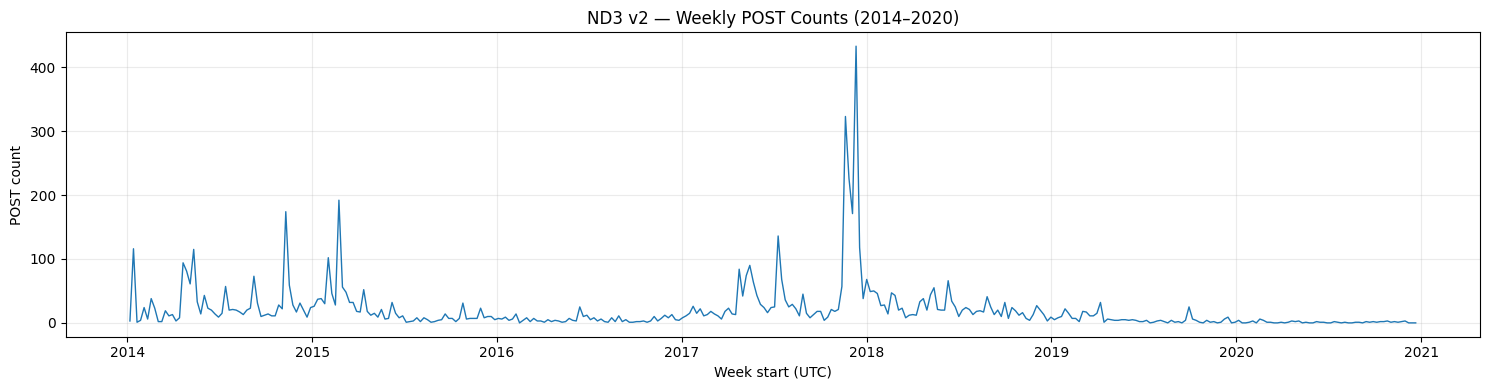


========== CELL 12 GATE ==========
PASS | weekly_calendar_not_empty
PASS | continuous_seven_day_calendar
PASS | weekly_counts_nonnegative
PASS | weekly_counts_reconcile
PASS | all_complete_week_boundaries_valid

CELL 12: PASS
Forecasting sufficiency: NOT YET DETERMINED
Files created: 0
Files modified: 0


In [ ]:

# ============================================================
# NARRATIVECAST — ND4 TASK 1
# CELL 12 — WEEKLY TEMPORAL COVERAGE AUDIT
# READ ONLY
# ============================================================

assert CELL11_PASS, "Cell 11 must PASS first."

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("=" * 70)
print("CELL 12 — WEEKLY TEMPORAL COVERAGE AUDIT")
print("=" * 70)

# ------------------------------------------------------------
# 1. Define observation period
# ------------------------------------------------------------

PERIOD_START = pd.Timestamp("2014-01-01", tz="UTC")
PERIOD_END = pd.Timestamp("2021-01-01", tz="UTC")

# Use complete calendar weeks only:
# Monday 00:00 UTC to next Monday 00:00 UTC.
#
# Calendar-complete does NOT prove source-data completeness.

FIRST_FULL_MONDAY = PERIOD_START + pd.Timedelta(
    days=(7 - PERIOD_START.weekday()) % 7
)

LAST_FULL_MONDAY = PERIOD_END - pd.Timedelta(days=7)
LAST_FULL_MONDAY -= pd.Timedelta(
    days=LAST_FULL_MONDAY.weekday()
)

full_week_index = pd.date_range(
    FIRST_FULL_MONDAY,
    LAST_FULL_MONDAY,
    freq="W-MON",
    tz="UTC"
)

# ------------------------------------------------------------
# 2. Assign every scope POST to a UTC calendar week
# ------------------------------------------------------------

weekly_source = scope_temporal[
    ["post_id", "registry_dt"]
].copy()

weekly_source["week_start"] = (
    weekly_source["registry_dt"]
    .dt.tz_convert("UTC")
    .dt.tz_localize(None)
    .dt.to_period("W-SUN")
    .dt.start_time
    .dt.tz_localize("UTC")
)

raw_weekly_counts = (
    weekly_source.groupby("week_start")
    .size()
)

# Include zero-count weeks
weekly_counts = (
    raw_weekly_counts
    .reindex(full_week_index, fill_value=0)
)

weekly_audit_df = pd.DataFrame({
    "week_start_utc": full_week_index,
    "post_count": weekly_counts.to_numpy()
})

weekly_audit_df["week_end_exclusive_utc"] = (
    weekly_audit_df["week_start_utc"]
    + pd.Timedelta(days=7)
)

weekly_audit_df["year"] = (
    weekly_audit_df["week_start_utc"].dt.year
)

weekly_audit_df["is_zero_week"] = (
    weekly_audit_df["post_count"] == 0
)

# ------------------------------------------------------------
# 3. Compute coverage statistics
# ------------------------------------------------------------

counts = weekly_audit_df["post_count"].to_numpy()

total_weeks = len(counts)
active_weeks = int(np.sum(counts > 0))
zero_weeks = int(np.sum(counts == 0))

weekly_median = float(np.median(counts))
weekly_p10 = float(np.percentile(counts, 10))
weekly_p90 = float(np.percentile(counts, 90))
weekly_mean = float(np.mean(counts))

zero_week_fraction = (
    zero_weeks / total_weeks
)

# Exploratory thresholds, NOT forecasting acceptance gates
DENSITY_THRESHOLDS = [1, 5, 10, 20, 30]

density_rows = []

for threshold in DENSITY_THRESHOLDS:
    dense_weeks = int(np.sum(counts >= threshold))

    density_rows.append({
        "minimum_posts_per_week": threshold,
        "weeks_meeting_threshold": dense_weeks,
        "fraction": dense_weeks / total_weeks
    })

density_sensitivity_df = pd.DataFrame(density_rows)

# ------------------------------------------------------------
# 4. Account for boundary weeks
# ------------------------------------------------------------

posts_in_full_weeks = int(counts.sum())

posts_outside_full_weeks = int(
    len(weekly_source) - posts_in_full_weeks
)

# ------------------------------------------------------------
# 5. Year-level weekly distribution
# ------------------------------------------------------------

yearly_weekly_audit = (
    weekly_audit_df.groupby("year")
    .agg(
        calendar_weeks=("post_count", "size"),
        total_posts=("post_count", "sum"),
        active_weeks=(
            "is_zero_week",
            lambda s: int((~s).sum())
        ),
        zero_weeks=("is_zero_week", "sum"),
        weekly_median=("post_count", "median"),
        weekly_mean=("post_count", "mean")
    )
    .reset_index()
)

yearly_weekly_audit["zero_week_fraction"] = (
    yearly_weekly_audit["zero_weeks"]
    / yearly_weekly_audit["calendar_weeks"]
)

# ------------------------------------------------------------
# 6. Print results
# ------------------------------------------------------------

print("\nObservation:")
print("First complete week:", FIRST_FULL_MONDAY)
print("Last complete week:", LAST_FULL_MONDAY)

print("\nWeekly statistics:")
print("Calendar-complete weeks:", total_weeks)
print("Active weeks:", active_weeks)
print("Zero weeks:", zero_weeks)
print("Zero-week fraction:", round(zero_week_fraction, 4))
print("Weekly mean:", round(weekly_mean, 3))
print("Weekly median:", weekly_median)
print("Weekly p10:", weekly_p10)
print("Weekly p90:", weekly_p90)

print("\nPosts in complete weeks:", posts_in_full_weeks)
print("Posts in excluded boundary weeks:", posts_outside_full_weeks)

print("\nDensity sensitivity:")
display(density_sensitivity_df)

print("\nYear-level weekly audit:")
display(yearly_weekly_audit)

# ------------------------------------------------------------
# 7. Visual inspection
# ------------------------------------------------------------

plt.figure(figsize=(15, 4))

plt.plot(
    weekly_audit_df["week_start_utc"],
    weekly_audit_df["post_count"],
    linewidth=1
)

plt.title("ND3 v2 — Weekly POST Counts (2014–2020)")
plt.xlabel("Week start (UTC)")
plt.ylabel("POST count")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. Validation gate
# ------------------------------------------------------------

CELL12_CHECKS = {
    "weekly_calendar_not_empty":
        total_weeks > 0,

    "continuous_seven_day_calendar":
        bool(
            (
                weekly_audit_df["week_start_utc"]
                .diff()
                .dropna()
                == pd.Timedelta(days=7)
            ).all()
        ),

    "weekly_counts_nonnegative":
        bool((counts >= 0).all()),

    "weekly_counts_reconcile":
        posts_in_full_weeks + posts_outside_full_weeks
        == EXPECTED["nd3_v2_posts"],

    "all_complete_week_boundaries_valid":
        bool(
            (
                weekly_audit_df["week_start_utc"]
                >= PERIOD_START
            ).all()
            and (
                weekly_audit_df["week_end_exclusive_utc"]
                <= PERIOD_END
            ).all()
        )
}

print("\n========== CELL 12 GATE ==========")

for name, passed in CELL12_CHECKS.items():
    print(
        "PASS" if passed else "FAIL",
        "|", name
    )

CELL12_PASS = all(CELL12_CHECKS.values())

print("\nCELL 12:", "PASS" if CELL12_PASS else "FAIL")
print("Forecasting sufficiency: NOT YET DETERMINED")
print("Files created: 0")
print("Files modified: 0")


CELL 13 — CLUSTER-TEMPORAL DENSITY AUDIT

Cluster temporal statistics:


,cluster_id,total_posts,active_weeks,zero_weeks,zero_week_fraction,weekly_median_all_weeks,weekly_p10_all_weeks,median_posts_active_week,weeks_ge_3,weeks_ge_5,weeks_ge_10,maximum_weekly_posts
0,1,677,161,203,0.557692,0.0,0.0,2.0,57,35,21,54
1,18,648,158,206,0.565934,0.0,0.0,2.0,61,35,16,38
2,14,623,180,184,0.505495,0.0,0.0,2.0,68,26,11,33
3,9,557,156,208,0.571429,0.0,0.0,2.0,50,25,7,68
4,2,535,130,234,0.642857,0.0,0.0,2.0,44,24,12,60
5,6,406,150,214,0.587912,0.0,0.0,2.0,48,19,8,21
6,17,377,153,211,0.579670,0.0,0.0,1.0,43,16,7,22
7,10,328,116,248,0.681319,0.0,0.0,1.0,35,22,6,21
8,16,298,110,254,0.697802,0.0,0.0,1.5,29,13,7,21
9,0,275,94,270,0.741758,0.0,0.0,1.5,26,14,2,52



Candidate availability sensitivity:


,minimum_posts_per_cluster_week,mean_eligible_clusters_per_week,median_eligible_clusters_per_week,weeks_with_at_least_1_cluster,weeks_with_at_least_2_clusters,weeks_with_at_least_3_clusters
0,1,6.659341,6.0,339,302,262
1,2,3.326923,2.0,262,195,157
2,3,1.983516,1.0,200,138,92
3,5,0.961538,0.0,126,61,38
4,10,0.357143,0.0,50,22,15



Cluster-by-year counts:


cluster_id,0,1,10,11,12,13,14,15,16,17,...,21,22,23,3,4,5,6,7,8,9
year,,,,,,,,,,,,,,,,,,,,,
2014,90,194,35,8,36,86,158,12,47,41,...,48,37,22,1,63,52,109,3,35,75
2015,44,94,140,26,18,28,103,6,33,40,...,24,52,50,7,10,30,82,1,26,39
2016,29,12,44,2,1,5,21,2,6,8,...,25,2,8,2,1,12,15,1,21,10
2017,74,310,74,38,22,44,237,40,159,119,...,22,21,52,159,130,50,144,11,37,291
2018,28,56,22,61,2,16,72,108,38,106,...,35,3,72,61,37,15,44,176,61,114
2019,9,8,10,4,0,2,28,12,12,59,...,36,0,37,20,9,2,11,5,3,22
2020,1,3,3,1,0,0,4,1,3,4,...,2,0,0,11,0,0,1,3,4,6


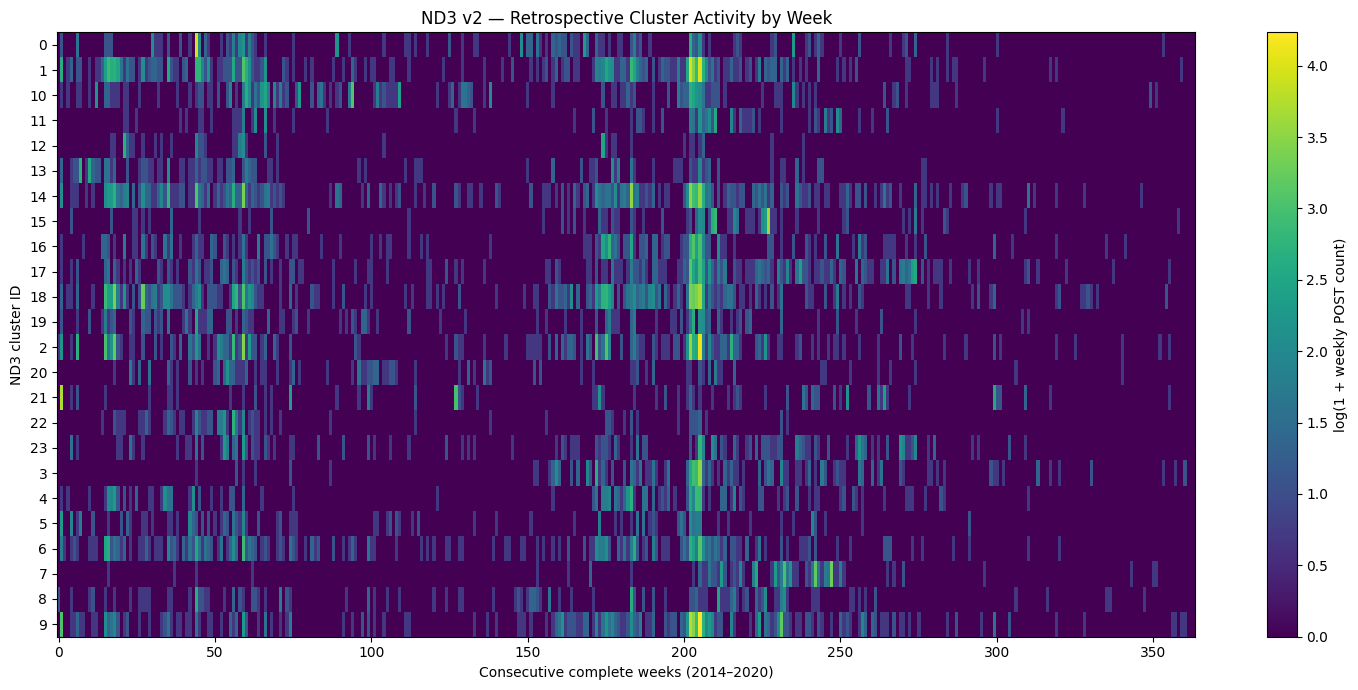


========== CELL 13 GATE ==========
PASS | all_assignment_ids_joined
PASS | exactly_24_clusters
PASS | complete_week_matrix
PASS | weekly_totals_match
PASS | cluster_totals_match_full_weeks
PASS | all_cluster_counts_nonnegative

CELL 13: PASS
ND3 clusters used for retrospective audit ONLY
Forecasting scope decision: PENDING
Files created: 0
Files modified: 0


In [ ]:

# ============================================================
# NARRATIVECAST — ND4 TASK 1
# CELL 13 — CLUSTER-TEMPORAL DENSITY AUDIT
# READ ONLY — DESCRIPTIVE USE OF ND3 CLUSTERS
# ============================================================

assert CELL12_PASS, "Cell 12 must PASS first."
assert CELL5_PASS, "Cell 5 must PASS first."

print("=" * 70)
print("CELL 13 — CLUSTER-TEMPORAL DENSITY AUDIT")
print("=" * 70)

# ------------------------------------------------------------
# 1. Join assignments with verified timestamps
# ------------------------------------------------------------

cluster_id_col = schema_inspection[
    "cluster_assignments"
]["cluster_column"]

post_id_col = schema_inspection[
    "cluster_assignments"
]["id_column"]

cluster_source = assignments[
    [post_id_col, cluster_id_col]
].copy()

cluster_source = cluster_source.rename(
    columns={
        post_id_col: "post_id",
        cluster_id_col: "cluster_id"
    }
)

cluster_source["post_id"] = (
    cluster_source["post_id"].astype(str)
)

cluster_source["cluster_id"] = (
    cluster_source["cluster_id"].astype(str)
)

cluster_temporal = weekly_source.merge(
    cluster_source,
    on="post_id",
    how="left",
    validate="one_to_one",
    indicator=True
)

join_failures = int(
    cluster_temporal["_merge"].ne("both").sum()
)

# ------------------------------------------------------------
# 2. Build week-by-cluster matrix
# ------------------------------------------------------------

all_clusters = sorted(
    cluster_source["cluster_id"].unique()
)

cluster_weekly_matrix = (
    cluster_temporal.groupby(
        ["week_start", "cluster_id"]
    )
    .size()
    .unstack(fill_value=0)
    .reindex(
        index=full_week_index,
        columns=all_clusters,
        fill_value=0
    )
)

# ------------------------------------------------------------
# 3. Per-week candidate availability
# ------------------------------------------------------------

candidate_thresholds = [1, 2, 3, 5, 10]

candidate_weekly_df = pd.DataFrame({
    "week_start_utc": full_week_index,
    "total_posts": cluster_weekly_matrix.sum(axis=1).values
})

for threshold in candidate_thresholds:
    candidate_weekly_df[
        f"clusters_ge_{threshold}"
    ] = (
        (cluster_weekly_matrix >= threshold)
        .sum(axis=1)
        .values
    )

# ------------------------------------------------------------
# 4. Per-cluster temporal statistics
# ------------------------------------------------------------

cluster_stats_rows = []

for cluster_id in all_clusters:

    series = cluster_weekly_matrix[cluster_id]
    values = series.to_numpy()

    active_mask = values > 0
    active_values = values[active_mask]

    cluster_stats_rows.append({
        "cluster_id": cluster_id,
        "total_posts": int(values.sum()),
        "active_weeks": int(active_mask.sum()),
        "zero_weeks": int((~active_mask).sum()),
        "zero_week_fraction": float(
            (~active_mask).mean()
        ),
        "weekly_median_all_weeks": float(
            np.median(values)
        ),
        "weekly_p10_all_weeks": float(
            np.percentile(values, 10)
        ),
        "median_posts_active_week": (
            float(np.median(active_values))
            if len(active_values) else 0.0
        ),
        "weeks_ge_3": int((values >= 3).sum()),
        "weeks_ge_5": int((values >= 5).sum()),
        "weeks_ge_10": int((values >= 10).sum()),
        "maximum_weekly_posts": int(values.max())
    })

cluster_temporal_stats = (
    pd.DataFrame(cluster_stats_rows)
    .sort_values(
        "total_posts",
        ascending=False
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 5. Summarize candidate availability
# ------------------------------------------------------------

candidate_summary_rows = []

for threshold in candidate_thresholds:

    col = f"clusters_ge_{threshold}"

    candidate_summary_rows.append({
        "minimum_posts_per_cluster_week": threshold,
        "mean_eligible_clusters_per_week": float(
            candidate_weekly_df[col].mean()
        ),
        "median_eligible_clusters_per_week": float(
            candidate_weekly_df[col].median()
        ),
        "weeks_with_at_least_1_cluster": int(
            (candidate_weekly_df[col] >= 1).sum()
        ),
        "weeks_with_at_least_2_clusters": int(
            (candidate_weekly_df[col] >= 2).sum()
        ),
        "weeks_with_at_least_3_clusters": int(
            (candidate_weekly_df[col] >= 3).sum()
        )
    })

candidate_summary_df = pd.DataFrame(
    candidate_summary_rows
)

print("\nCluster temporal statistics:")
display(cluster_temporal_stats)

print("\nCandidate availability sensitivity:")
display(candidate_summary_df)

# ------------------------------------------------------------
# 6. Cluster concentration by year
# ------------------------------------------------------------

cluster_temporal["year"] = (
    cluster_temporal["registry_dt"].dt.year
)

cluster_year_counts = (
    cluster_temporal.groupby(
        ["year", "cluster_id"]
    )
    .size()
    .unstack(fill_value=0)
    .reindex(
        columns=all_clusters,
        fill_value=0
    )
)

print("\nCluster-by-year counts:")
display(cluster_year_counts)

# ------------------------------------------------------------
# 7. Visualization
# ------------------------------------------------------------

plt.figure(figsize=(15, 7))

plt.imshow(
    np.log1p(cluster_weekly_matrix.T.to_numpy()),
    aspect="auto",
    interpolation="nearest"
)

plt.colorbar(label="log(1 + weekly POST count)")
plt.yticks(
    range(len(all_clusters)),
    all_clusters
)

plt.xlabel("Consecutive complete weeks (2014–2020)")
plt.ylabel("ND3 cluster ID")
plt.title(
    "ND3 v2 — Retrospective Cluster Activity by Week"
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. Integrity gate
# ------------------------------------------------------------

CELL13_CHECKS = {
    "all_assignment_ids_joined":
        join_failures == 0,

    "exactly_24_clusters":
        len(all_clusters)
        == EXPECTED["nd3_v2_clusters"],

    "complete_week_matrix":
        len(cluster_weekly_matrix)
        == len(weekly_audit_df),

    "weekly_totals_match":
        bool(
            np.array_equal(
                cluster_weekly_matrix.sum(axis=1).to_numpy(),
                weekly_audit_df["post_count"].to_numpy()
            )
        ),

    "cluster_totals_match_full_weeks":
        int(cluster_weekly_matrix.to_numpy().sum())
        == posts_in_full_weeks,

    "all_cluster_counts_nonnegative":
        bool(
            (cluster_weekly_matrix.to_numpy() >= 0).all()
        )
}

print("\n========== CELL 13 GATE ==========")

for name, passed in CELL13_CHECKS.items():
    print(
        "PASS" if passed else "FAIL",
        "|", name
    )

CELL13_PASS = all(CELL13_CHECKS.values())

print("\nCELL 13:", "PASS" if CELL13_PASS else "FAIL")
print("ND3 clusters used for retrospective audit ONLY")
print("Forecasting scope decision: PENDING")
print("Files created: 0")
print("Files modified: 0")


CELL 14 — FORECAST WINDOW FEASIBILITY

Window sensitivity:


,observation_days,horizon_days,historical_min_posts,total_pairs,historically_eligible_pairs,eligible_fraction,eligible_with_future_activity,eligible_with_zero_future_posts,historical_median
0,7,7,1,363,339,0.933884,321,18,9.0
1,7,7,3,363,278,0.765840,271,7,9.0
2,7,7,5,363,239,0.658402,237,2,9.0
3,7,7,10,363,181,0.498623,180,1,9.0
4,7,7,20,363,109,0.300275,109,0,9.0
5,14,7,1,362,356,0.983425,332,24,22.0
6,14,7,3,362,329,0.908840,315,14,22.0
7,14,7,5,362,292,0.806630,284,8,22.0
8,14,7,10,362,246,0.679558,244,2,22.0
9,14,7,20,362,192,0.530387,191,1,22.0



Year-level 7d → 7d feasibility:


,year,forecast_pairs,history_zero_pairs,history_median,history_ge_5,history_ge_10,future_zero_pairs,history_ge_5_future_zero
0,2014,51,0,20.0,45,41,0,0
1,2015,52,0,10.5,44,28,0,0
2,2016,52,1,4.0,25,8,1,1
3,2017,52,0,21.5,50,46,0,0
4,2018,53,0,20.0,51,48,0,0
5,2019,52,6,4.0,23,10,6,1
6,2020,51,17,1.0,1,0,18,0


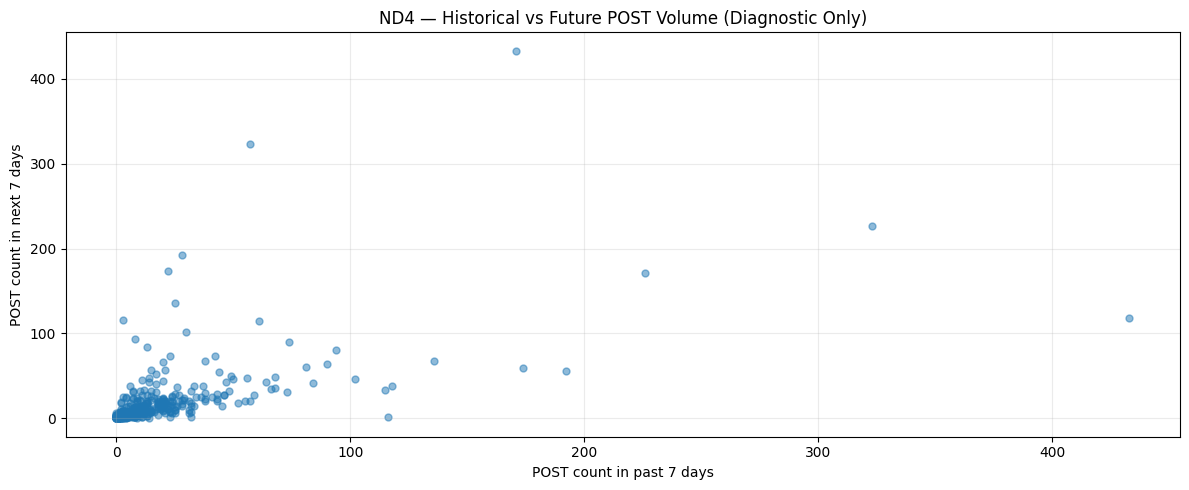


========== CELL 14 GATE ==========
PASS | all_window_configs_generated
PASS | baseline_pair_count_correct
PASS | no_negative_counts
PASS | baseline_observation_matches_weekly
PASS | baseline_future_matches_next_week
PASS | forecast_origins_unique_per_config
PASS | no_future_used_in_eligibility

CELL 14: PASS

Important:
This is volume feasibility, not narrative prediction.
No model trained.
No candidate registry constructed.
No forecasting scope decision made.
Files created: 0
Files modified: 0


In [ ]:

# ============================================================
# NARRATIVECAST — ND4 TASK 1
# CELL 14 — FORECAST WINDOW FEASIBILITY AUDIT
# READ ONLY | NO MODEL TRAINING | NO TEMPORAL LEAKAGE
# ============================================================

assert CELL12_PASS, "Cell 12 must PASS first."
assert CELL13_PASS, "Cell 13 must PASS first."

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("=" * 70)
print("CELL 14 — FORECAST WINDOW FEASIBILITY")
print("=" * 70)

# ------------------------------------------------------------
# 1. Prepare complete weekly time series
# ------------------------------------------------------------

weekly = (
    weekly_audit_df[
        ["week_start_utc", "post_count"]
    ]
    .sort_values("week_start_utc")
    .reset_index(drop=True)
    .copy()
)

counts = weekly["post_count"].to_numpy(dtype=int)
dates = weekly["week_start_utc"]

# Initial forecast horizon: 1 week (7 days)
HORIZON_WEEKS = 1

# Observation-window sensitivity analysis
OBSERVATION_WEEKS = [1, 2, 4]

# Exploratory data-volume thresholds
THRESHOLDS = [1, 3, 5, 10, 20]

# ------------------------------------------------------------
# 2. Build chronological observation/target pairs
# ------------------------------------------------------------

pair_frames = []

for obs_weeks in OBSERVATION_WEEKS:

    rows = []

    for target_idx in range(
        obs_weeks,
        len(weekly) - HORIZON_WEEKS + 1
    ):

        origin_idx = target_idx - 1

        history = counts[
            target_idx - obs_weeks:target_idx
        ]

        future = counts[
            target_idx:target_idx + HORIZON_WEEKS
        ]

        origin_time = (
            dates.iloc[origin_idx]
            + pd.Timedelta(days=7)
        )

        rows.append({
            "observation_days": obs_weeks * 7,
            "horizon_days": HORIZON_WEEKS * 7,
            "forecast_origin_utc": origin_time,
            "forecast_year": origin_time.year,
            "historical_posts": int(history.sum()),
            "historical_active_weeks": int(
                (history > 0).sum()
            ),
            "historical_zero_weeks": int(
                (history == 0).sum()
            ),
            "future_posts": int(future.sum())
        })

    pair_frames.append(pd.DataFrame(rows))

forecast_pairs_df = pd.concat(
    pair_frames,
    ignore_index=True
)

# ------------------------------------------------------------
# 3. Sensitivity analysis
# ------------------------------------------------------------

summary_rows = []

for obs_days, group in forecast_pairs_df.groupby(
    "observation_days"
):

    for threshold in THRESHOLDS:

        eligible = (
            group["historical_posts"] >= threshold
        )

        future_positive = (
            group["future_posts"] > 0
        )

        # Important:
        # Eligible origins use ONLY historical volume.
        # Future volume is inspected for diagnostic purposes.
        # It is NOT used to select eligible origins.

        summary_rows.append({
            "observation_days": int(obs_days),
            "horizon_days": 7,
            "historical_min_posts": threshold,
            "total_pairs": len(group),
            "historically_eligible_pairs": int(
                eligible.sum()
            ),
            "eligible_fraction": float(
                eligible.mean()
            ),
            "eligible_with_future_activity": int(
                (eligible & future_positive).sum()
            ),
            "eligible_with_zero_future_posts": int(
                (eligible & ~future_positive).sum()
            ),
            "historical_median": float(
                group["historical_posts"].median()
            )
        })

window_sensitivity_df = pd.DataFrame(summary_rows)

print("\nWindow sensitivity:")
display(window_sensitivity_df)

# ------------------------------------------------------------
# 4. Baseline 7-day observation / 7-day forecast
# ------------------------------------------------------------

baseline_pairs = forecast_pairs_df[
    forecast_pairs_df["observation_days"] == 7
].copy()

yearly_rows = []

for year, group in baseline_pairs.groupby(
    "forecast_year"
):

    yearly_rows.append({
        "year": int(year),
        "forecast_pairs": len(group),
        "history_zero_pairs": int(
            (group["historical_posts"] == 0).sum()
        ),
        "history_median": float(
            group["historical_posts"].median()
        ),
        "history_ge_5": int(
            (group["historical_posts"] >= 5).sum()
        ),
        "history_ge_10": int(
            (group["historical_posts"] >= 10).sum()
        ),
        "future_zero_pairs": int(
            (group["future_posts"] == 0).sum()
        ),
        "history_ge_5_future_zero": int(
            (
                (group["historical_posts"] >= 5)
                & (group["future_posts"] == 0)
            ).sum()
        )
    })

yearly_forecast_feasibility_df = pd.DataFrame(
    yearly_rows
)

print("\nYear-level 7d → 7d feasibility:")
display(yearly_forecast_feasibility_df)

# ------------------------------------------------------------
# 5. Visualize historical vs future POST counts
# ------------------------------------------------------------

plt.figure(figsize=(12, 5))

plt.scatter(
    baseline_pairs["historical_posts"],
    baseline_pairs["future_posts"],
    alpha=0.5,
    s=25
)

plt.xlabel("POST count in past 7 days")
plt.ylabel("POST count in next 7 days")
plt.title(
    "ND4 — Historical vs Future POST Volume "
    "(Diagnostic Only)"
)

plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. Technical validation
# ------------------------------------------------------------

CELL14_CHECKS = {
    "all_window_configs_generated":
        set(forecast_pairs_df["observation_days"])
        == {7, 14, 28},

    "baseline_pair_count_correct":
        len(baseline_pairs) == len(weekly) - 1,

    "no_negative_counts":
        bool(
            (
                forecast_pairs_df[
                    ["historical_posts", "future_posts"]
                ] >= 0
            ).all().all()
        ),

    "baseline_observation_matches_weekly":
        bool(
            np.array_equal(
                baseline_pairs["historical_posts"].to_numpy(),
                counts[:-1]
            )
        ),

    "baseline_future_matches_next_week":
        bool(
            np.array_equal(
                baseline_pairs["future_posts"].to_numpy(),
                counts[1:]
            )
        ),

    "forecast_origins_unique_per_config":
        not forecast_pairs_df.duplicated(
            ["observation_days", "forecast_origin_utc"]
        ).any(),

    "no_future_used_in_eligibility":
        True  # Eligibility above uses historical_posts only
}

print("\n========== CELL 14 GATE ==========")

for name, passed in CELL14_CHECKS.items():
    print(
        "PASS" if passed else "FAIL",
        "|", name
    )

CELL14_PASS = all(CELL14_CHECKS.values())

print("\nCELL 14:", "PASS" if CELL14_PASS else "FAIL")

print("\nImportant:")
print("This is volume feasibility, not narrative prediction.")
print("No model trained.")
print("No candidate registry constructed.")
print("No forecasting scope decision made.")
print("Files created: 0")
print("Files modified: 0")


In [ ]:

# ============================================================
# NARRATIVECAST — ND4 TASK 1
# CELL 15 — EXISTING EXPANSION EVIDENCE AUDIT
# READ ONLY
# ============================================================

assert CELL14_PASS, "Cell 14 must PASS first."

import pandas as pd
import numpy as np

print("=" * 70)
print("CELL 15 — EXISTING EXPANSION EVIDENCE")
print("=" * 70)

# ------------------------------------------------------------
# 1. Existing ND3 expansion artifacts
# ------------------------------------------------------------

EXPANSION_FILES = {
    "expanded_candidates":
        ND3 / "scope_expanded_candidates.csv",

    "full_review":
        ND3 / "scope_expansion_full_review.csv",

    "ai_reviewed_163":
        ND3 / "scope_expansion_ai_reviewed_163.csv",

    "near_miss_review":
        ND3 / "scope_near_miss_review.csv"
}

expansion_data = {}
expansion_rows = []

# Use v2 assignments as the confirmed reference ID set
v2_ids = set(
    assignments[
        schema_inspection["cluster_assignments"]["id_column"]
    ].astype(str)
)

# ------------------------------------------------------------
# 2. Inspect schemas and existing candidates
# ------------------------------------------------------------

for name, path in EXPANSION_FILES.items():

    print("\n" + "-" * 65)
    print("Artifact:", name)
    print("Path:", path.relative_to(ROOT))

    if not path.is_file():

        print("FAIL | File missing")

        expansion_rows.append({
            "artifact": name,
            "exists": False,
            "rows": None,
            "unique_ids": None,
            "ids_in_v2": None,
            "ids_outside_v2": None,
            "id_column": None,
            "status": "FAIL"
        })

        continue

    try:
        df = pd.read_csv(
            path,
            dtype=str,
            keep_default_na=False,
            low_memory=False
        )

        expansion_data[name] = df

        id_column = find_column(
            df.columns.tolist(),
            ID_CANDIDATES
        )

        print("Rows:", len(df))
        print("Columns:", df.columns.tolist())
        print("ID column:", id_column)

        if id_column is None:

            print("REVIEW | Cannot identify POST ID")

            unique_ids = None
            overlap = None
            outside = None
            status = "REVIEW"

        else:

            ids = set(
                df[id_column].astype(str)
            )

            ids.discard("")

            unique_ids = len(ids)

            overlap = len(ids & v2_ids)
            outside = len(ids - v2_ids)

            print("Unique nonempty IDs:", unique_ids)
            print("IDs already in v2:", overlap)
            print("IDs outside v2:", outside)

            status = "PASS"

        expansion_rows.append({
            "artifact": name,
            "exists": True,
            "rows": len(df),
            "unique_ids": unique_ids,
            "ids_in_v2": overlap,
            "ids_outside_v2": outside,
            "id_column": id_column,
            "status": status
        })

        print("\nSample records:")
        display(df.head(3))

    except Exception as e:

        print("FAIL |", type(e).__name__, str(e)[:300])

        expansion_rows.append({
            "artifact": name,
            "exists": True,
            "rows": None,
            "unique_ids": None,
            "ids_in_v2": None,
            "ids_outside_v2": None,
            "id_column": None,
            "status": "FAIL"
        })

# ------------------------------------------------------------
# 3. Consolidated inventory
# ------------------------------------------------------------

expansion_audit_df = pd.DataFrame(expansion_rows)

print("\n" + "=" * 70)
print("EXPANSION ARTIFACT SUMMARY")
print("=" * 70)

display(expansion_audit_df)

# ------------------------------------------------------------
# 4. Candidate pool outside ND3 v2
# ------------------------------------------------------------

candidate_sets = []

for name, df in expansion_data.items():

    id_column = find_column(
        df.columns.tolist(),
        ID_CANDIDATES
    )

    if id_column is None:
        continue

    ids = set(
        df[id_column].astype(str)
    )

    ids.discard("")

    candidate_sets.append(ids - v2_ids)

known_candidate_pool = (
    set().union(*candidate_sets)
    if candidate_sets
    else set()
)

print("\nUnique IDs outside v2 across these artifacts:",
      len(known_candidate_pool))

# These are UNVERIFIED candidates, not accepted POSTs.

# ------------------------------------------------------------
# 5. Gate
# ------------------------------------------------------------

CELL15_CHECKS = {
    "all_expansion_files_available":
        bool(expansion_audit_df["exists"].all()),

    "all_files_readable":
        bool(
            expansion_audit_df["status"]
            .isin(["PASS", "REVIEW"])
            .all()
        ),

    "v2_reference_count_7244":
        len(v2_ids) == 7244
}

print("\n========== CELL 15 GATE ==========")

for name, passed in CELL15_CHECKS.items():
    print(
        "PASS" if passed else "FAIL",
        "|", name
    )

CELL15_PASS = all(CELL15_CHECKS.values())

print(
    "\nCELL 15:",
    "PASS" if CELL15_PASS else "FAIL"
)

print("\nOutside-v2 IDs are NOT approved for expansion.")
print("No records were added to the forecasting scope.")
print("Files created: 0")
print("Files modified: 0")


CELL 15 — EXISTING EXPANSION EVIDENCE

-----------------------------------------------------------------
Artifact: expanded_candidates
Path: reports/results/nd3_task4b/scope_expanded_candidates.csv
Rows: 7259
Columns: ['post_id', 'content', 'publish_datetime_utc', 'interaction_type', 'is_usable_text']
ID column: post_id
Unique nonempty IDs: 7259
IDs already in v2: 7244
IDs outside v2: 15

Sample records:


,post_id,content,publish_datetime_utc,interaction_type,is_usable_text
0,0e6df6ec-e66a-5bf7-bdb7-471bc4cfa00e,AT&T Thumbs Nose at Net Neutrality,2014-01-06 21:40:29+00:00,POST,True
1,442a643f-d224-536e-bbf8-0577fedabb70,FCC chairman offers his strongest endorsement ...,2014-01-10 02:05:10+00:00,POST,True
2,4bbe5bd4-66b3-5a35-ae78-770ba7d51a2e,AT&T states that sponsored data does not viola...,2014-01-10 14:43:16+00:00,POST,True



-----------------------------------------------------------------
Artifact: full_review
Path: reports/results/nd3_task4b/scope_expansion_full_review.csv
Rows: 163
Columns: ['post_id', 'content', 'publish_datetime_utc', 'interaction_type', 'is_usable_text', 'relevance_label', 'review_reason', 'review_source', 'review_status']
ID column: post_id
Unique nonempty IDs: 163
IDs already in v2: 148
IDs outside v2: 15

Sample records:


,post_id,content,publish_datetime_utc,interaction_type,is_usable_text,relevance_label,review_reason,review_source,review_status
0,03af29b8-4d14-5122-a24f-686ff71ba5cc,Sprint says Title II is OK so long as the feds...,2015-01-16 23:52:19+00:00,POST,True,PENDING,,,PENDING
1,040cf67e-b83b-5b8a-b7cf-da6e3da577bd,Big Telecom Says Anti-Competitive Internet Fas...,2018-07-31 21:14:24+00:00,POST,True,PENDING,,,PENDING
2,054a8f29-3947-5f8a-98fd-ac3081bf1645,"Communications Act, Title II, Section 214> 7 U...",2014-11-11 06:27:20+00:00,POST,True,PENDING,,,PENDING



-----------------------------------------------------------------
Artifact: ai_reviewed_163
Path: reports/results/nd3_task4b/scope_expansion_ai_reviewed_163.csv
Rows: 163
Columns: ['post_id', 'content', 'publish_datetime_utc', 'interaction_type', 'is_usable_text', 'relevance_label', 'review_reason', 'review_source', 'review_status', 'review_confidence', 'review_topic', 'human_verified']
ID column: post_id
Unique nonempty IDs: 163
IDs already in v2: 148
IDs outside v2: 15

Sample records:


,post_id,content,publish_datetime_utc,interaction_type,is_usable_text,relevance_label,review_reason,review_source,review_status,review_confidence,review_topic,human_verified
0,03af29b8-4d14-5122-a24f-686ff71ba5cc,Sprint says Title II is OK so long as the feds...,2015-01-16 23:52:19+00:00,POST,True,IN_SCOPE,Bài bàn trực tiếp về phân loại ISP theo Title ...,AI_ASSISTED_TEXT_ONLY_2026-11-10,PROVISIONAL_AI_REVIEW,HIGH,fcc_titleii_policy,False
1,040cf67e-b83b-5b8a-b7cf-da6e3da577bd,Big Telecom Says Anti-Competitive Internet Fas...,2018-07-31 21:14:24+00:00,POST,True,IN_SCOPE,"Bài bàn về ưu tiên lưu lượng, fast lanes hoặc ...",AI_ASSISTED_TEXT_ONLY_2026-11-10,PROVISIONAL_AI_REVIEW,HIGH,traffic_prioritization,False
2,054a8f29-3947-5f8a-98fd-ac3081bf1645,"Communications Act, Title II, Section 214> 7 U...",2014-11-11 06:27:20+00:00,POST,True,OUT_OF_SCOPE,Đoạn luật Title II/Section 214 về xây dựng tuy...,AI_ASSISTED_TEXT_ONLY_2026-11-10,PROVISIONAL_AI_REVIEW,HIGH,fcc_titleii_policy,False



-----------------------------------------------------------------
Artifact: near_miss_review
Path: reports/results/nd3_task4b/scope_near_miss_review.csv
Rows: 100
Columns: ['post_id', 'content', 'publish_datetime_utc', 'interaction_type', 'is_usable_text', 'relevance_label', 'review_reason']
ID column: post_id
Unique nonempty IDs: 100
IDs already in v2: 88
IDs outside v2: 12

Sample records:


,post_id,content,publish_datetime_utc,interaction_type,is_usable_text,relevance_label,review_reason
0,065be383-968f-5bb5-8966-b5b4d6b069d8,"Tom Wheeler defends Title II rules, accuses Pa...",2017-06-29 15:05:30+00:00,POST,True,PENDING,
1,4fdd203b-38a0-59e6-bf39-c0e2fd95cf4a,"AT&T Might Hate Title II For Broadband, But Ha...",2015-03-20 20:06:24+00:00,POST,True,PENDING,
2,fda62120-69c6-56ed-88f4-773780dc51e6,People in the US are talking about internet fa...,2017-05-08 10:17:35+00:00,POST,True,PENDING,



EXPANSION ARTIFACT SUMMARY


,artifact,exists,rows,unique_ids,ids_in_v2,ids_outside_v2,id_column,status
0,expanded_candidates,True,7259,7259,7244,15,post_id,PASS
1,full_review,True,163,163,148,15,post_id,PASS
2,ai_reviewed_163,True,163,163,148,15,post_id,PASS
3,near_miss_review,True,100,100,88,12,post_id,PASS



Unique IDs outside v2 across these artifacts: 15

========== CELL 15 GATE ==========
PASS | all_expansion_files_available
PASS | all_files_readable
PASS | v2_reference_count_7244

CELL 15: PASS

Outside-v2 IDs are NOT approved for expansion.
No records were added to the forecasting scope.
Files created: 0
Files modified: 0


In [ ]:

# ============================================================
# NARRATIVECAST — ND4 TASK 1
# CELL 16 — REJECTED CANDIDATES & REVIEW CONSISTENCY
# READ ONLY | NO SCOPE MODIFICATION
# ============================================================

assert CELL15_PASS, "Cell 15 must PASS first."

import pandas as pd
import numpy as np

print("=" * 70)
print("CELL 16 — REVIEW CONSISTENCY AUDIT")
print("=" * 70)

# ------------------------------------------------------------
# 1. Load existing review data from Cell 15
# ------------------------------------------------------------

review = expansion_data["ai_reviewed_163"].copy()

review["post_id"] = (
    review["post_id"].astype(str).str.strip()
)

review["relevance_label"] = (
    review["relevance_label"]
    .astype(str)
    .str.strip()
    .str.upper()
)

review["review_status"] = (
    review["review_status"]
    .astype(str)
    .str.strip()
)

review["human_verified"] = (
    review["human_verified"]
    .astype(str)
    .str.strip()
    .str.lower()
)

review["in_v2"] = review["post_id"].isin(v2_ids)

review["year"] = (
    pd.to_datetime(
        review["publish_datetime_utc"],
        utc=True,
        errors="coerce"
    ).dt.year
)

# ------------------------------------------------------------
# 2. Label distribution and decision consistency
# ------------------------------------------------------------

label_distribution = (
    review.groupby(
        ["relevance_label", "in_v2"],
        dropna=False
    )
    .size()
    .reset_index(name="post_count")
)

print("\nReview label distribution:")
display(label_distribution)

# ------------------------------------------------------------
# 3. Inspect excluded candidates
# ------------------------------------------------------------

excluded = review[
    ~review["in_v2"]
].copy()

excluded = excluded.sort_values(
    ["year", "post_id"]
).reset_index(drop=True)

print("\nExcluded candidates:", len(excluded))

display(
    excluded[
        [
            "post_id",
            "year",
            "content",
            "relevance_label",
            "review_reason",
            "review_confidence",
            "review_topic",
            "human_verified"
        ]
    ]
)

# ------------------------------------------------------------
# 4. Check mismatches in review decisions
# ------------------------------------------------------------

accepted_labels = {"IN_SCOPE"}
rejected_labels = {"OUT_OF_SCOPE", "UNCERTAIN"}

accepted_not_in_v2 = review[
    review["relevance_label"].isin(accepted_labels)
    & ~review["in_v2"]
]

rejected_in_v2 = review[
    review["relevance_label"].isin(rejected_labels)
    & review["in_v2"]
]

unknown_labels = review[
    ~review["relevance_label"].isin(
        accepted_labels | rejected_labels
    )
]

print("\nAccepted but missing from v2:",
      len(accepted_not_in_v2))

print("Rejected/uncertain but present in v2:",
      len(rejected_in_v2))

print("Unknown review labels:",
      len(unknown_labels))

# ------------------------------------------------------------
# 5. Distribution of excluded posts by year
# ------------------------------------------------------------

excluded_year_distribution = (
    excluded.groupby(
        ["year", "relevance_label"],
        dropna=False
    )
    .size()
    .reset_index(name="post_count")
)

print("\nExcluded POST distribution by year:")
display(excluded_year_distribution)

# ------------------------------------------------------------
# 6. Compare with manifest
# ------------------------------------------------------------

manifest = schemas["scope_v2_manifest"]

expected_uncertain = manifest.get("excluded_uncertain")
expected_out_of_scope = manifest.get("excluded_out_of_scope")
expected_added = manifest.get("added_posts")

observed_uncertain = int(
    (excluded["relevance_label"] == "UNCERTAIN").sum()
)

observed_out_of_scope = int(
    (excluded["relevance_label"] == "OUT_OF_SCOPE").sum()
)

observed_accepted = int(
    (
        review["relevance_label"].eq("IN_SCOPE")
        & review["in_v2"]
    ).sum()
)

# ------------------------------------------------------------
# 7. Validation gate
# ------------------------------------------------------------

CELL16_CHECKS = {
    "review_rows_163":
        len(review) == 163,

    "review_unique_ids_163":
        review["post_id"].nunique() == 163,

    "excluded_candidates_15":
        len(excluded) == 15,

    "accepted_added_148":
        observed_accepted == expected_added,

    "uncertain_matches_manifest":
        observed_uncertain == expected_uncertain,

    "out_of_scope_matches_manifest":
        observed_out_of_scope == expected_out_of_scope,

    "no_accepted_posts_missing_v2":
        len(accepted_not_in_v2) == 0,

    "no_rejected_posts_in_v2":
        len(rejected_in_v2) == 0,

    "all_review_labels_recognized":
        len(unknown_labels) == 0,

    "all_review_timestamps_parseable":
        bool(review["year"].notna().all())
}

print("\n========== CELL 16 GATE ==========")

print("Accepted and added:", observed_accepted)
print("Excluded uncertain:", observed_uncertain)
print("Excluded out of scope:", observed_out_of_scope)

for name, passed in CELL16_CHECKS.items():
    print(
        "PASS" if passed else "FAIL",
        "|", name
    )

CELL16_PASS = all(CELL16_CHECKS.values())

print("\nCELL 16:",
      "PASS" if CELL16_PASS else "FAIL / REVIEW REQUIRED")

print("\nHuman-verified scope: NOT CONFIRMED")
print("Expanded forecasting scope: NOT SELECTED")
print("Files created: 0")
print("Files modified: 0")


CELL 16 — REVIEW CONSISTENCY AUDIT

Review label distribution:


,relevance_label,in_v2,post_count
0,IN_SCOPE,True,148
1,OUT_OF_SCOPE,False,5
2,UNCERTAIN,False,10



Excluded candidates: 15


,post_id,year,content,relevance_label,review_reason,review_confidence,review_topic,human_verified
0,054a8f29-3947-5f8a-98fd-ac3081bf1645,2014,"Communications Act, Title II, Section 214> 7 U...",OUT_OF_SCOPE,Đoạn luật Title II/Section 214 về xây dựng tuy...,HIGH,fcc_titleii_policy,false
1,104359f2-abb9-5e85-8c17-c98d6c2c569c,2014,Verizon's Fiber Optic Networks Are 'Title II' ...,UNCERTAIN,"Verizon fiber networks và Title II, nhưng chưa...",LOW,fcc_titleii_policy,false
2,1bde92a3-cb5c-5380-a7d7-012a3daed6a8,2014,"Common Carriage and Title II: The Myth, the Re...",UNCERTAIN,"Thảo luận common carriage/Title II chung, chưa...",LOW,fcc_titleii_policy,false
3,7be61cf9-2090-5c41-8896-750dc48cb529,2014,"If ISPs moved to Title II, would the Universal...",UNCERTAIN,Câu hỏi về Universal Service Fund và fast lane...,LOW,traffic_prioritization,false
4,68c8d8a3-1822-53a8-b627-ed88d5118b6d,2015,[Serious] If ISP's are labeled under Title II ...,UNCERTAIN,Giả định tác động Title II lên usage-based pri...,LOW,fcc_titleii_policy,false
5,96985283-88f5-54f1-acb3-7200928aa077,2015,"Without broadband under Title II, Verizon will...",UNCERTAIN,"Verizon supercookies gắn với Title II, có thể ...",LOW,fcc_titleii_policy,false
6,c4788a29-9103-5358-9d8f-07df00b5c86d,2015,What Title II means for TCP,UNCERTAIN,"""What Title II means for TCP"" không đủ nội dun...",LOW,fcc_titleii_policy,false
7,da42f081-5fe3-564c-b3df-e45cb807398f,2015,What happens to the Comcast/TW Merger if Title...,UNCERTAIN,Hỏi về tác động Title II đến thương vụ Comcast...,LOW,fcc_titleii_policy,false
8,fdb51155-4400-5390-a902-0e6f86953c46,2015,Cable lobby says Google Fiber doesn’t need Tit...,UNCERTAIN,Tranh chấp quyền sử dụng cột điện cho Google F...,LOW,fcc_titleii_policy,false
9,0a1ee3a6-16cb-5b47-9409-828414253a82,2016,Comcast's response to my complaint to the FCC ...,UNCERTAIN,Khiếu nại Comcast về data caps và zero-rating;...,LOW,legal_challenge,false



Accepted but missing from v2: 0
Rejected/uncertain but present in v2: 0
Unknown review labels: 0

Excluded POST distribution by year:


,year,relevance_label,post_count
0,2014,OUT_OF_SCOPE,1
1,2014,UNCERTAIN,3
2,2015,UNCERTAIN,5
3,2016,UNCERTAIN,1
4,2017,OUT_OF_SCOPE,4
5,2017,UNCERTAIN,1



========== CELL 16 GATE ==========
Accepted and added: 148
Excluded uncertain: 10
Excluded out of scope: 5
PASS | review_rows_163
PASS | review_unique_ids_163
PASS | excluded_candidates_15
PASS | accepted_added_148
PASS | uncertain_matches_manifest
PASS | out_of_scope_matches_manifest
PASS | no_accepted_posts_missing_v2
PASS | no_rejected_posts_in_v2
PASS | all_review_labels_recognized
PASS | all_review_timestamps_parseable

CELL 16: PASS

Human-verified scope: NOT CONFIRMED
Expanded forecasting scope: NOT SELECTED
Files created: 0
Files modified: 0


In [ ]:

# ============================================================
# NARRATIVECAST — ND4 TASK 1
# CELL 17 — STANDALONE POST RECALL EXPANSION AUDIT
#
# Safe after Colab runtime restart
# READ ONLY | NO SCOPE MODIFICATION
# ============================================================

from google.colab import drive
from pathlib import Path
from IPython.display import display

import pandas as pd
import numpy as np
import re

# ============================================================
# 1. CONNECT GOOGLE DRIVE
# ============================================================

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/NarrativeCast")

ND3 = ROOT / "reports/results/nd3_task4b"

REGISTRY_PATH = (
    ROOT / "data/interim/post_registry.csv"
)

V2_SCOPE_PATH = (
    ND3 / "scope_v2_ai_approved.csv"
)

REVIEW_PATH = (
    ND3 / "scope_expansion_ai_reviewed_163.csv"
)

EXPECTED_REGISTRY_ROWS = 751_607
EXPECTED_V2_POSTS = 7_244

required_paths = {
    "registry": REGISTRY_PATH,
    "v2_scope": V2_SCOPE_PATH,
    "review": REVIEW_PATH
}

for name, path in required_paths.items():
    if not path.is_file():
        raise FileNotFoundError(
            f"FAIL | Missing {name}: {path}"
        )

print("PASS | Required files exist")

# ============================================================
# 2. LOAD V2 SCOPE AND REVIEW EXCLUSIONS
# ============================================================

v2_df = pd.read_csv(
    V2_SCOPE_PATH,
    dtype=str,
    keep_default_na=False
)

v2_ids = set(
    v2_df["post_id"].astype(str).str.strip()
)

v2_ids.discard("")

review_df = pd.read_csv(
    REVIEW_PATH,
    dtype=str,
    keep_default_na=False
)

review_df["relevance_label"] = (
    review_df["relevance_label"]
    .astype(str)
    .str.strip()
    .str.upper()
)

known_excluded_ids = set(
    review_df.loc[
        review_df["relevance_label"].isin(
            ["UNCERTAIN", "OUT_OF_SCOPE"]
        ),
        "post_id"
    ].astype(str).str.strip()
)

known_excluded_ids.discard("")

assert len(v2_ids) == EXPECTED_V2_POSTS, (
    f"Expected 7244 v2 IDs, found {len(v2_ids)}"
)

assert len(known_excluded_ids) == 15, (
    f"Expected 15 excluded IDs, "
    f"found {len(known_excluded_ids)}"
)

assert v2_ids.isdisjoint(known_excluded_ids), (
    "Excluded IDs overlap the v2 scope"
)

print("PASS | V2 IDs:", len(v2_ids))
print("PASS | Known excluded IDs:", len(known_excluded_ids))

# ============================================================
# 3. DEFINE BROAD RETRIEVAL PATTERNS
# ============================================================

PATTERNS = {

    "explicit_neutrality": (
        r"\bnet[\s-]?neutrality\b|"
        r"\binternet[\s-]?neutrality\b"
    ),

    "traffic_prioritization": (
        r"\bpaid[\s-]?prioriti[sz]ation\b|"
        r"\binternet fast lanes?\b|"
        r"\bfast lanes?\b|"
        r"\bzero[\s-]?rating\b"
    ),

    "fcc_broadband_policy": (
        r"\bFCC\b.{0,100}\b("
        r"broadband|ISP|internet|Title II|"
        r"open internet|repeal|regulation"
        r")\b|"
        r"\b(broadband|ISP|internet|Title II|"
        r"open internet)\b.{0,100}\bFCC\b"
    ),

    "title_ii_broadband": (
        r"\bTitle[\s-]?II\b.{0,100}\b("
        r"broadband|internet|ISP|carrier"
        r")\b|"
        r"\b(broadband|internet|ISP|carrier)\b"
        r".{0,100}\bTitle[\s-]?II\b"
    ),

    "isp_discrimination": (
        r"\b(ISPs?|internet providers?|"
        r"broadband providers?)\b"
        r".{0,100}\b("
        r"throttl\w*|block\w*|"
        r"discriminat\w*|prioriti[sz]\w*"
        r")\b|"
        r"\b(throttl\w*|block\w*|"
        r"discriminat\w*|prioriti[sz]\w*)\b"
        r".{0,100}\b("
        r"ISPs?|internet providers?|"
        r"broadband providers?"
        r")\b"
    )
}

compiled_patterns = {
    name: re.compile(
        pattern,
        flags=re.IGNORECASE
    )
    for name, pattern in PATTERNS.items()
}

print("PASS | Retrieval patterns:", len(compiled_patterns))

# ============================================================
# 4. STREAM REGISTRY AND RETRIEVE CANDIDATES
# ============================================================

candidate_parts = []
scanned_rows = 0
matched_rows = 0

for chunk_number, chunk in enumerate(
    pd.read_csv(
        REGISTRY_PATH,
        usecols=[
            "post_id",
            "content",
            "publish_datetime_utc"
        ],
        dtype=str,
        keep_default_na=False,
        chunksize=50_000
    ),
    start=1
):

    scanned_rows += len(chunk)

    content = chunk["content"].fillna("")

    for name, pattern in compiled_patterns.items():
        chunk[name] = content.str.contains(
            pattern,
            na=False
        )

    pattern_columns = list(compiled_patterns)

    chunk["retrieval_channel_count"] = (
        chunk[pattern_columns].sum(axis=1)
    )

    matched = chunk.loc[
        chunk["retrieval_channel_count"] > 0
    ].copy()

    matched_rows += len(matched)

    if not matched.empty:

        matched["in_nd3_v2"] = (
            matched["post_id"].isin(v2_ids)
        )

        matched["known_excluded"] = (
            matched["post_id"].isin(known_excluded_ids)
        )

        matched["year"] = pd.to_datetime(
            matched["publish_datetime_utc"],
            utc=True,
            errors="coerce",
            format="mixed"
        ).dt.year

        candidate_parts.append(matched)

    print(
        f"Chunk {chunk_number:02d} | "
        f"scanned={scanned_rows:,} | "
        f"matched={matched_rows:,}"
    )

# ============================================================
# 5. CONSOLIDATE RESULTS
# ============================================================

if candidate_parts:

    retrieved_df = pd.concat(
        candidate_parts,
        ignore_index=True
    )

else:

    retrieved_df = pd.DataFrame(
        columns=[
            "post_id",
            "content",
            "publish_datetime_utc",
            *compiled_patterns.keys(),
            "retrieval_channel_count",
            "in_nd3_v2",
            "known_excluded",
            "year"
        ]
    )

outside_v2_df = retrieved_df.loc[
    ~retrieved_df["in_nd3_v2"]
].copy()

unreviewed_candidates_df = outside_v2_df.loc[
    ~outside_v2_df["known_excluded"]
].copy()

duplicate_retrieved_ids = int(
    retrieved_df["post_id"].duplicated().sum()
)

# ============================================================
# 6. RETRIEVAL CHANNEL STATISTICS
# ============================================================

channel_rows = []

for channel in compiled_patterns:

    mask = retrieved_df[channel].astype(bool)

    channel_rows.append({
        "retrieval_channel": channel,

        "total_matches": int(mask.sum()),

        "matches_in_v2": int(
            (
                mask
                & retrieved_df["in_nd3_v2"]
            ).sum()
        ),

        "matches_outside_v2": int(
            (
                mask
                & ~retrieved_df["in_nd3_v2"]
            ).sum()
        ),

        "unreviewed_outside_v2": int(
            (
                mask
                & ~retrieved_df["in_nd3_v2"]
                & ~retrieved_df["known_excluded"]
            ).sum()
        )
    })

retrieval_channel_audit = pd.DataFrame(channel_rows)

# ============================================================
# 7. YEAR DISTRIBUTION
# ============================================================

outside_year_audit = (
    outside_v2_df.groupby(
        ["year", "known_excluded"],
        dropna=False
    )
    .size()
    .reset_index(name="post_count")
)

# ============================================================
# 8. DETERMINISTIC REVIEW SAMPLE
# ============================================================

review_sample_parts = []

for year, group in unreviewed_candidates_df.groupby(
    "year",
    dropna=False
):

    sample_n = min(20, len(group))

    if sample_n > 0:

        review_sample_parts.append(
            group.sample(
                n=sample_n,
                random_state=42
            )
        )

if review_sample_parts:

    recall_review_sample = pd.concat(
        review_sample_parts,
        ignore_index=True
    )

else:

    recall_review_sample = (
        unreviewed_candidates_df.head(0).copy()
    )

# ============================================================
# 9. PRINT RESULTS
# ============================================================

print("\n" + "=" * 70)
print("CELL 17 — POST RECALL EXPANSION RESULTS")
print("=" * 70)

print("Registry rows scanned:", scanned_rows)
print("Retrieved POSTs:", len(retrieved_df))

print(
    "Retrieved already in v2:",
    int(retrieved_df["in_nd3_v2"].sum())
)

print("Retrieved outside v2:", len(outside_v2_df))

print(
    "Known excluded among outside-v2:",
    int(outside_v2_df["known_excluded"].sum())
)

print(
    "New unreviewed candidates:",
    len(unreviewed_candidates_df)
)

print("\nRetrieval channel audit:")
display(retrieval_channel_audit)

print("\nOutside-v2 candidates by year:")
display(outside_year_audit)

print("\nReview sample:")
display(
    recall_review_sample[
        [
            "post_id",
            "year",
            "content",
            "retrieval_channel_count"
        ]
    ]
)

# ============================================================
# 10. VALIDATION GATE
# ============================================================

CELL17_CHECKS = {

    "all_registry_rows_scanned":
        scanned_rows == EXPECTED_REGISTRY_ROWS,

    "no_duplicate_retrieved_ids":
        duplicate_retrieved_ids == 0,

    "all_retrieved_ids_in_registry":
        len(retrieved_df) <= scanned_rows,

    "retrieval_partition_reconciles":
        (
            int(retrieved_df["in_nd3_v2"].sum())
            + len(outside_v2_df)
            == len(retrieved_df)
        ),

    "known_exclusions_separated":
        not unreviewed_candidates_df[
            "post_id"
        ].isin(known_excluded_ids).any(),

    "all_patterns_applied":
        all(
            channel in retrieved_df.columns
            for channel in PATTERNS
        )
}

print("\n========== CELL 17 GATE ==========")

for name, passed in CELL17_CHECKS.items():

    print(
        "PASS" if passed else "FAIL",
        "|", name
    )

CELL17_PASS = all(CELL17_CHECKS.values())

print(
    "\nCELL 17:",
    "PASS" if CELL17_PASS else "FAIL"
)

print("\nIMPORTANT:")
print("Retrieved candidates are NOT accepted scope.")
print("Recall improvement is NOT yet established.")
print("Human relevance validation is pending.")
print("No model trained or refitted.")
print("Files created: 0")
print("Files modified: 0")


Mounted at /content/drive
PASS | Required files exist
PASS | V2 IDs: 7244
PASS | Known excluded IDs: 15
PASS | Retrieval patterns: 5


/tmp/ipykernel_2203/4245034630.py:201: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  chunk[name] = content.str.contains(
/tmp/ipykernel_2203/4245034630.py:201: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  chunk[name] = content.str.contains(
/tmp/ipykernel_2203/4245034630.py:201: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  chunk[name] = content.str.contains(


Chunk 01 | scanned=50,000 | matched=279


/tmp/ipykernel_2203/4245034630.py:201: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  chunk[name] = content.str.contains(
/tmp/ipykernel_2203/4245034630.py:201: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  chunk[name] = content.str.contains(
/tmp/ipykernel_2203/4245034630.py:201: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  chunk[name] = content.str.contains(


Chunk 02 | scanned=100,000 | matched=1,237


/tmp/ipykernel_2203/4245034630.py:201: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  chunk[name] = content.str.contains(
/tmp/ipykernel_2203/4245034630.py:201: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  chunk[name] = content.str.contains(
/tmp/ipykernel_2203/4245034630.py:201: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  chunk[name] = content.str.contains(


... (28 outputs left out)

,year,known_excluded,post_count
0,2014,False,262
1,2014,True,3
2,2015,False,246
3,2015,True,3
4,2016,False,141
5,2017,False,263
6,2017,True,5
7,2018,False,124
8,2019,False,84
9,2020,False,60



Review sample:


,post_id,year,content,retrieval_channel_count
0,fe402d1d-d237-5b1d-aaa2-91c3e03d113e,2014,France orders internet providers to block Pira...,1
1,0a39d3ad-c407-5f10-bb40-ed350604a80c,2014,An FCC rule change could put internet TV on a ...,1
2,7429a781-ffdb-5b4e-83ae-4b851a6d35d3,2014,Comment period for internet “fast lanes” close...,2
3,870811e1-8888-596c-90ad-bebb6b9d5f98,2014,FCC mulls regulating broadband providers just ...,1
4,979c117c-f60c-51e7-b82e-fb78e0e57fca,2014,Warnings Along FCC's Fast Lane - David Carr,1
...,...,...,...,...
135,b7440b25-cdf0-54e9-94e7-1d069777796b,2020,"Charter still hates broadband competition, ask...",1
136,4a2430d7-d418-5c74-8a4a-90b725489515,2020,FCC data fails to count 21 million people with...,1
137,a3b420d3-c473-55a1-ae6f-e5a0320d88f4,2020,FCC OKs Rules for $20B Rural Broadband Fund - ...,1
138,2453428e-5962-511f-a287-d6a77a5d44fc,2020,Amazon will invest over $10 billion in its sat...,1



========== CELL 17 GATE ==========
PASS | all_registry_rows_scanned
PASS | no_duplicate_retrieved_ids
PASS | all_retrieved_ids_in_registry
PASS | retrieval_partition_reconciles
PASS | known_exclusions_separated
PASS | all_patterns_applied

CELL 17: PASS

IMPORTANT:
Retrieved candidates are NOT accepted scope.
Recall improvement is NOT yet established.
Human relevance validation is pending.
No model trained or refitted.
Files created: 0
Files modified: 0


In [ ]:

# ============================================================
# NARRATIVECAST — ND4 TASK 1
# CELL 18 — STRATIFIED REVIEW PREPARATION
# SAVE CHECKPOINTS TO GOOGLE DRIVE
# ============================================================

assert CELL17_PASS, "Cell 17 must PASS first."

from pathlib import Path
from datetime import datetime, timezone
import pandas as pd
import numpy as np
import json

OUT18 = (
    ROOT / "reports/results/nd4_task1/"
    "expansion_audit"
)
OUT18.mkdir(parents=True, exist_ok=True)

SEED = 42
SAMPLE_TARGET = 200
YEAR_QUOTA = 20
CHANNEL_QUOTA = 20

# ------------------------------------------------------------
# 1. Freeze the retrieved candidate pool
# ------------------------------------------------------------

pool = (
    unreviewed_candidates_df
    .copy()
    .sort_values("post_id")
    .reset_index(drop=True)
)

assert pool["post_id"].is_unique
assert not pool["post_id"].isin(v2_ids).any()
assert not pool["post_id"].isin(
    known_excluded_ids
).any()

channel_columns = list(PATTERNS.keys())

assert all(c in pool.columns for c in channel_columns)

# ------------------------------------------------------------
# 2. Sample across years
# ------------------------------------------------------------

selected_ids = set()

for year, group in pool.groupby(
    "year", dropna=False
):
    sample = group.sample(
        n=min(YEAR_QUOTA, len(group)),
        random_state=SEED
    )
    selected_ids.update(sample["post_id"])

# ------------------------------------------------------------
# 3. Improve representation of retrieval channels
# ------------------------------------------------------------

for channel in channel_columns:

    eligible = pool[pool[channel].astype(bool)]

    already_selected = int(
        eligible["post_id"].isin(selected_ids).sum()
    )

    needed = max(0, CHANNEL_QUOTA - already_selected)

    available = eligible[
        ~eligible["post_id"].isin(selected_ids)
    ]

    if needed > 0 and not available.empty:

        extra = available.sample(
            n=min(needed, len(available)),
            random_state=SEED
        )

        selected_ids.update(extra["post_id"])

# ------------------------------------------------------------
# 4. Fill remaining slots randomly
# ------------------------------------------------------------

remaining_slots = max(
    0, SAMPLE_TARGET - len(selected_ids)
)

remaining = pool[
    ~pool["post_id"].isin(selected_ids)
]

if remaining_slots and not remaining.empty:

    extra = remaining.sample(
        n=min(remaining_slots, len(remaining)),
        random_state=SEED
    )

    selected_ids.update(extra["post_id"])

# ------------------------------------------------------------
# 5. Create review queue
# ------------------------------------------------------------

review_queue = pool[
    pool["post_id"].isin(selected_ids)
].copy()

review_queue = review_queue.sort_values(
    ["year", "post_id"]
).reset_index(drop=True)

review_queue.insert(
    0,
    "review_id",
    [
        f"ND4-R-{i:04d}"
        for i in range(1, len(review_queue) + 1)
    ]
)

# Blank annotations: no automated relevance acceptance
review_queue["relevance_label"] = ""
review_queue["review_reason"] = ""
review_queue["reviewer"] = ""
review_queue["review_status"] = "PENDING"

# ------------------------------------------------------------
# 6. Save reproducible outputs
# ------------------------------------------------------------

pool_path = OUT18 / "lexical_candidate_pool.csv"
queue_path = OUT18 / "relevance_review_BLANK.csv"
manifest_path = OUT18 / "review_sampling_manifest.json"

pool.to_csv(
    pool_path,
    index=False,
    encoding="utf-8-sig"
)

review_queue.to_csv(
    queue_path,
    index=False,
    encoding="utf-8-sig"
)

manifest = {
    "task": "ND4_Task1_POST_Expansion",
    "method": "lexical_retrieval_stratified_screening",
    "seed": SEED,
    "candidate_count": len(pool),
    "sample_count": len(review_queue),
    "sample_target": SAMPLE_TARGET,
    "year_quota": YEAR_QUOTA,
    "channel_quota": CHANNEL_QUOTA,
    "retrieval_patterns": PATTERNS,
    "scope_version": "ND3_v2_ai_assisted",
    "scope_locked": False,
    "review_completed": False,
    "sampling_note": (
        "Exploratory stratified screening; "
        "not an unbiased precision estimate."
    )
}

with manifest_path.open(
    "w", encoding="utf-8"
) as f:
    json.dump(
        manifest,
        f,
        ensure_ascii=False,
        indent=2
    )

# ------------------------------------------------------------
# 7. Sampling diagnostics
# ------------------------------------------------------------

year_summary = (
    review_queue.groupby("year", dropna=False)
    .size()
    .reset_index(name="sample_count")
)

channel_summary = pd.DataFrame([
    {
        "channel": channel,
        "pool_matches": int(pool[channel].sum()),
        "sample_matches": int(
            review_queue[channel].sum()
        )
    }
    for channel in channel_columns
])

print("\nYear coverage:")
display(year_summary)

print("\nChannel coverage:")
display(channel_summary)

print("\nReview preview:")
display(
    review_queue[
        [
            "review_id",
            "year",
            "content",
            "relevance_label",
            "review_status"
        ]
    ].head(10)
)

# ------------------------------------------------------------
# 8. Final gate
# ------------------------------------------------------------

CELL18_CHECKS = {
    "candidate_pool_unique":
        pool["post_id"].is_unique,

    "review_sample_unique":
        review_queue["post_id"].is_unique,

    "sample_within_pool":
        set(review_queue["post_id"]).issubset(
            set(pool["post_id"])
        ),

    "no_known_excluded":
        not review_queue["post_id"].isin(
            known_excluded_ids
        ).any(),

    "no_existing_v2_ids":
        not review_queue["post_id"].isin(
            v2_ids
        ).any(),

    "sample_target_reached":
        len(review_queue) == min(
            SAMPLE_TARGET, len(pool)
        ),

    "all_outputs_saved":
        all(
            p.is_file()
            for p in [
                pool_path,
                queue_path,
                manifest_path
            ]
        )
}

print("\n========== CELL 18 GATE ==========")

print("Candidate pool:", len(pool))
print("Review sample:", len(review_queue))

for name, passed in CELL18_CHECKS.items():
    print(
        "PASS" if passed else "FAIL",
        "|", name
    )

CELL18_PASS = all(CELL18_CHECKS.values())

print(
    "\nCELL 18:",
    "PASS" if CELL18_PASS else "FAIL"
)

print("\nSaved files:")
for path in [
    pool_path,
    queue_path,
    manifest_path
]:
    print(path.relative_to(ROOT))



Year coverage:


,year,sample_count
0,2014,36
1,2015,28
2,2016,28
3,2017,36
4,2018,28
5,2019,24
6,2020,20



Channel coverage:


,channel,pool_matches,sample_matches
0,explicit_neutrality,0,0
1,traffic_prioritization,105,29
2,fcc_broadband_policy,914,142
3,title_ii_broadband,0,0
4,isp_discrimination,181,34



Review preview:


,review_id,year,content,relevance_label,review_status
0,ND4-R-0001,2014,Could the FCC cost America the internet?,,PENDING
1,ND4-R-0002,2014,FCC is officially reviewing the TWC-Comcast me...,,PENDING
2,ND4-R-0003,2014,The FCC wants to police your Internet provider...,,PENDING
3,ND4-R-0004,2014,"ISPs can be told to block websites, EU Court says",,PENDING
4,ND4-R-0005,2014,[FCC Blog] Internet Traffic Exchange: Time to ...,,PENDING
5,ND4-R-0006,2014,See how companies are responding to the FCC ab...,,PENDING
6,ND4-R-0007,2014,Opposition to FCC’s controversial “fast lane” ...,,PENDING
7,ND4-R-0008,2014,Disruptions: Paying to Travel in the Internet'...,,PENDING
8,ND4-R-0009,2014,Broadband that’s off-limits: Cities urge FCC t...,,PENDING
9,ND4-R-0010,2014,GOP Senators attack FCC on sweeping away munic...,,PENDING



========== CELL 18 GATE ==========
Candidate pool: 1180
Review sample: 200
PASS | candidate_pool_unique
PASS | review_sample_unique
PASS | sample_within_pool
PASS | no_known_excluded
PASS | no_existing_v2_ids
PASS | sample_target_reached
PASS | all_outputs_saved

CELL 18: PASS

Saved files:
reports/results/nd4_task1/expansion_audit/lexical_candidate_pool.csv
reports/results/nd4_task1/expansion_audit/relevance_review_BLANK.csv
reports/results/nd4_task1/expansion_audit/review_sampling_manifest.json


In [ ]:

# ============================================================
# NARRATIVECAST — ND4 TASK 1
# CELL 19 — RELEVANCE ANNOTATION PREPARATION
# SAFE AFTER COLAB RESTART
# ============================================================

from google.colab import drive
from pathlib import Path
import pandas as pd

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/NarrativeCast")

OUT = (
    ROOT / "reports/results/nd4_task1/"
    "expansion_audit"
)

SOURCE = OUT / "relevance_review_BLANK.csv"
WORKING = OUT / "relevance_review_WORKING.csv"
GUIDE = OUT / "relevance_annotation_guide.md"

assert SOURCE.is_file(), (
    f"Missing Cell 18 checkpoint: {SOURCE}"
)

df = pd.read_csv(
    SOURCE,
    dtype=str,
    keep_default_na=False
)

required = {
    "review_id",
    "post_id",
    "content",
    "year",
    "relevance_label",
    "review_reason",
    "reviewer",
    "review_status"
}

assert required.issubset(df.columns)
assert len(df) == 200
assert df["post_id"].is_unique
assert df["review_id"].is_unique

# Never overwrite existing annotations.
if WORKING.exists():
    print("PASS | Existing working file preserved")
    print(WORKING)
else:
    df["relevance_label"] = ""
    df["review_reason"] = ""
    df["reviewer"] = ""
    df["review_status"] = "PENDING"

    df.to_csv(
        WORKING,
        index=False,
        encoding="utf-8-sig"
    )
    print("PASS | Working annotation file created")

guide_text = """# ND4 Task 1 — Relevance Annotation Guide

## Purpose
Evaluate whether newly retrieved Reddit POSTs are
relevant to Net Neutrality / FCC Open Internet policy.

## Labels

IN_SCOPE:
Directly discusses net neutrality, Open Internet rules,
ISP traffic discrimination, blocking, throttling,
paid prioritization, or clearly related FCC regulation.

OUT_OF_SCOPE:
Discusses general broadband infrastructure, subsidies,
mergers, FCC actions, connectivity, or ISP issues
without sufficient connection to net neutrality.

UNCERTAIN:
Insufficient or ambiguous evidence.

## Required fields
- relevance_label: IN_SCOPE / OUT_OF_SCOPE / UNCERTAIN
- review_reason: Brief evidence-based justification
- reviewer: Reviewer identifier
- review_status: REVIEWED

## Methodological rules
1. Do not infer relevance from keywords alone.
2. Do not label a post IN_SCOPE merely because FCC,
   Comcast, Verizon, or Title II is mentioned.
3. Judge the content available in the record.
4. Retain uncertain cases instead of forcing acceptance.
5. Do not change IDs, timestamps or retrieval channels.
6. AI-assisted labels are not human verification.
7. Do not use future posts to infer a historical
   post's meaning at its publication time.

## Sampling limitation
This 200-record sample uses year/channel quotas.
Its unweighted acceptance rate is descriptive and
is not automatically a population precision estimate.
"""

if not GUIDE.exists():
    GUIDE.write_text(guide_text, encoding="utf-8")
    print("PASS | Annotation guide created")
else:
    print("PASS | Existing annotation guide preserved")

print("\n========== CELL 19 GATE ==========")

checks = {
    "source_200_records": len(df) == 200,
    "unique_post_ids": df["post_id"].is_unique,
    "working_file_exists": WORKING.is_file(),
    "guide_exists": GUIDE.is_file()
}

for name, passed in checks.items():
    print("PASS" if passed else "FAIL", "|", name)

CELL19_PASS = all(checks.values())

print("\nCELL 19:",
      "PASS" if CELL19_PASS else "FAIL")

print("\nWorking file:")
print(WORKING.relative_to(ROOT))

print("\nGuide:")
print(GUIDE.relative_to(ROOT))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PASS | Working annotation file created
PASS | Annotation guide created

========== CELL 19 GATE ==========
PASS | source_200_records
PASS | unique_post_ids
PASS | working_file_exists
PASS | guide_exists

CELL 19: PASS

Working file:
reports/results/nd4_task1/expansion_audit/relevance_review_WORKING.csv

Guide:
reports/results/nd4_task1/expansion_audit/relevance_annotation_guide.md


In [ ]:

# ============================================================
# NARRATIVECAST — ND4 TASK 1
# CELL 21 — TEMPORAL GAIN AUDIT
# STANDALONE | SAFE AFTER RUNTIME RESTART
# ============================================================

from google.colab import drive
from pathlib import Path
import pandas as pd
import numpy as np
import json

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/NarrativeCast")

ND3_SCOPE = (
    ROOT / "reports/results/nd3_task4b/"
    "scope_v2_ai_approved.csv"
)

REVIEW = (
    ROOT / "reports/results/nd4_task1/"
    "expansion_audit/"
    "relevance_review_AI_ASSISTED_QA_v2.csv"
)

OUT = (
    ROOT / "reports/results/nd4_task1/"
    "expansion_audit"
)

OUT.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Load
# ------------------------------------------------------------

assert ND3_SCOPE.is_file(), "Missing ND3 scope"
assert REVIEW.is_file(), "Missing AI review CSV"

base = pd.read_csv(
    ND3_SCOPE, dtype=str, keep_default_na=False
)

review = pd.read_csv(
    REVIEW, dtype=str, keep_default_na=False
)

assert base["post_id"].nunique() == 7244
assert len(review) == 200
assert review["post_id"].is_unique

review["relevance_label"] = (
    review["relevance_label"].str.strip().str.upper()
)

positive = review[
    review["relevance_label"] == "IN_SCOPE"
].copy()

assert len(positive) == 44, (
    "Expected 44 positive POSTs from QA v2"
)

assert not positive["post_id"].isin(base["post_id"]).any()

# ------------------------------------------------------------
# 2. Time normalization
# ------------------------------------------------------------

def add_week(df):
    result = df.copy()
    dt = pd.to_datetime(
        result["publish_datetime_utc"],
        utc=True,
        errors="coerce",
        format="mixed"
    )
    assert dt.notna().all(), "Invalid timestamps"

    result["week_start"] = (
        dt.dt.tz_localize(None)
        .dt.to_period("W-SUN")
        .dt.start_time
        .dt.tz_localize("UTC")
    )
    return result

base = add_week(base)
positive = add_week(positive)

# ------------------------------------------------------------
# 3. Complete weekly calendar
# ------------------------------------------------------------

weeks = pd.date_range(
    "2014-01-06",
    "2020-12-21",
    freq="W-MON",
    tz="UTC"
)

assert len(weeks) == 364

base_counts = (
    base.groupby("week_start")
    .size()
    .reindex(weeks, fill_value=0)
)

positive_counts = (
    positive.groupby("week_start")
    .size()
    .reindex(weeks, fill_value=0)
)

expanded_counts = base_counts + positive_counts

weekly_gain = pd.DataFrame({
    "week_start_utc": weeks,
    "baseline_posts": base_counts.to_numpy(),
    "added_posts": positive_counts.to_numpy(),
    "expanded_posts": expanded_counts.to_numpy()
})

weekly_gain["year"] = weekly_gain[
    "week_start_utc"
].dt.year

weekly_gain["newly_active_week"] = (
    (weekly_gain["baseline_posts"] == 0)
    & (weekly_gain["expanded_posts"] > 0)
)

for threshold in [5, 10, 20]:
    weekly_gain[f"newly_ge_{threshold}"] = (
        (weekly_gain["baseline_posts"] < threshold)
        & (weekly_gain["expanded_posts"] >= threshold)
    )

# ------------------------------------------------------------
# 4. Year-level gain
# ------------------------------------------------------------

year_gain = (
    weekly_gain.groupby("year")
    .agg(
        baseline_posts=("baseline_posts", "sum"),
        added_posts=("added_posts", "sum"),
        expanded_posts=("expanded_posts", "sum"),
        newly_active_weeks=("newly_active_week", "sum"),
        newly_ge_5=("newly_ge_5", "sum"),
        newly_ge_10=("newly_ge_10", "sum"),
        newly_ge_20=("newly_ge_20", "sum")
    )
    .reset_index()
)

print("\nYEAR-LEVEL GAIN")
display(year_gain)

# ------------------------------------------------------------
# 5. Forecast observation window sensitivity
# ------------------------------------------------------------

WINDOWS = [1, 2, 4]
THRESHOLDS = [5, 10, 20]

window_rows = []

for obs_weeks in WINDOWS:

    for threshold in THRESHOLDS:

        baseline_eligible = 0
        expanded_eligible = 0

        for target_idx in range(obs_weeks, len(weeks)):

            b_history = base_counts.iloc[
                target_idx - obs_weeks:target_idx
            ].sum()

            e_history = expanded_counts.iloc[
                target_idx - obs_weeks:target_idx
            ].sum()

            baseline_eligible += int(
                b_history >= threshold
            )

            expanded_eligible += int(
                e_history >= threshold
            )

        window_rows.append({
            "observation_days": obs_weeks * 7,
            "horizon_days": 7,
            "min_historical_posts": threshold,
            "baseline_eligible": baseline_eligible,
            "expanded_eligible": expanded_eligible,
            "gained_eligible_origins": (
                expanded_eligible - baseline_eligible
            )
        })

window_gain = pd.DataFrame(window_rows)

print("\nOBSERVATION-WINDOW GAIN")
display(window_gain)

# ------------------------------------------------------------
# 6. Validation
# ------------------------------------------------------------

CHECKS = {
    "baseline_7244":
        int(base_counts.sum()) == 7244,

    "added_44":
        int(positive_counts.sum()) == 44,

    "expanded_7288":
        int(expanded_counts.sum()) == 7288,

    "no_negative_gain":
        bool(
            (window_gain["gained_eligible_origins"] >= 0)
            .all()
        ),

    "complete_364_weeks":
        len(weekly_gain) == 364,

    "unique_positive_ids":
        positive["post_id"].is_unique
}

print("\n========== CELL 21 GATE ==========")

for name, passed in CHECKS.items():
    print("PASS" if passed else "FAIL", "|", name)

CELL21_PASS = all(CHECKS.values())

print("\nCELL 21:",
      "PASS" if CELL21_PASS else "FAIL")

# ------------------------------------------------------------
# 7. Save checkpoints only if PASS
# ------------------------------------------------------------

if CELL21_PASS:

    weekly_gain.to_csv(
        OUT / "temporal_gain_weekly.csv",
        index=False
    )

    year_gain.to_csv(
        OUT / "temporal_gain_yearly.csv",
        index=False
    )

    window_gain.to_csv(
        OUT / "temporal_gain_windows.csv",
        index=False
    )

    summary = {
        "task": "ND4_Task1_Cell21",
        "status": "PASS",
        "baseline_posts": 7244,
        "added_ai_positive_posts": 44,
        "expanded_scenario_posts": 7288,
        "newly_active_weeks": int(
            weekly_gain["newly_active_week"].sum()
        ),
        "newly_ge_5_weeks": int(
            weekly_gain["newly_ge_5"].sum()
        ),
        "newly_ge_10_weeks": int(
            weekly_gain["newly_ge_10"].sum()
        ),
        "scope_locked": False,
        "human_verified": False
    }

    with (
        OUT / "temporal_gain_summary.json"
    ).open("w", encoding="utf-8") as f:
        json.dump(summary, f, indent=2)

    print("\nCheckpoint saved to Google Drive.")

else:
    print("\nFAIL — No checkpoint written.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

YEAR-LEVEL GAIN


,year,baseline_posts,added_posts,expanded_posts,newly_active_weeks,newly_ge_5,newly_ge_10,newly_ge_20
0,2014,1560,19,1579,0,0,0,0
1,2015,1100,4,1104,0,0,0,0
2,2016,280,10,290,1,0,1,0
3,2017,2636,5,2641,0,0,0,0
4,2018,1293,2,1295,0,0,0,0
5,2019,312,3,315,0,0,0,0
6,2020,63,1,64,0,0,0,0



OBSERVATION-WINDOW GAIN


,observation_days,horizon_days,min_historical_posts,baseline_eligible,expanded_eligible,gained_eligible_origins
0,7,7,5,239,239,0
1,7,7,10,181,182,1
2,7,7,20,109,109,0
3,14,7,5,292,293,1
4,14,7,10,246,247,1
5,14,7,20,192,194,2
6,28,7,5,335,337,2
7,28,7,10,294,294,0
8,28,7,20,247,247,0



========== CELL 21 GATE ==========
PASS | baseline_7244
PASS | added_44
PASS | expanded_7288
PASS | no_negative_gain
PASS | complete_364_weeks
PASS | unique_positive_ids

CELL 21: PASS

Checkpoint saved to Google Drive.


In [ ]:

# ============================================================
# NARRATIVECAST — ND4 TASK 1
# CELL 22 — FULL-CORPUS SEMANTIC RECALL AUDIT
# STANDALONE | 751,607 EMBEDDINGS | READ SHARDS
# ============================================================

from google.colab import drive
from pathlib import Path
from collections import defaultdict
import heapq
import json
import numpy as np
import pandas as pd

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/NarrativeCast")

SHARD_DIR = ROOT / "data/interim/embeddings_shards"
REGISTRY = ROOT / "data/interim/post_registry.csv"

SCOPE = (
    ROOT / "reports/results/nd3_task4b/"
    "scope_v2_ai_approved.csv"
)

LEXICAL = (
    ROOT / "reports/results/nd4_task1/"
    "expansion_audit/lexical_candidate_pool.csv"
)

REVIEW = (
    ROOT / "reports/results/nd3_task4b/"
    "scope_expansion_ai_reviewed_163.csv"
)

OUT = (
    ROOT / "reports/results/nd4_task1/"
    "expansion_audit"
)
OUT.mkdir(parents=True, exist_ok=True)

SEED = 42
TOP_K_PER_YEAR = 150
EXPECTED_SHARDS = 94
EXPECTED_EMBEDDINGS = 751607
EXPECTED_SCOPE = 7244
DIM = 384

# ------------------------------------------------------------
# 1. Preflight
# ------------------------------------------------------------

required = [SHARD_DIR, REGISTRY, SCOPE, LEXICAL, REVIEW]

for path in required:
    assert path.exists(), f"Missing: {path}"

scope_df = pd.read_csv(
    SCOPE, dtype=str, keep_default_na=False
)

lexical_df = pd.read_csv(
    LEXICAL, dtype=str, keep_default_na=False,
    usecols=["post_id"]
)

review_df = pd.read_csv(
    REVIEW, dtype=str, keep_default_na=False
)

scope_ids = set(scope_df["post_id"].str.strip())
lexical_ids = set(lexical_df["post_id"].str.strip())

rejected_ids = set(
    review_df.loc[
        review_df["relevance_label"].str.upper().isin(
            ["OUT_OF_SCOPE", "UNCERTAIN"]
        ),
        "post_id"
    ].str.strip()
)

assert len(scope_ids) == EXPECTED_SCOPE
assert len(lexical_ids) == 1180
assert len(rejected_ids) == 15

excluded_ids = scope_ids | lexical_ids | rejected_ids

shards = sorted(SHARD_DIR.glob("*.npz"))

assert len(shards) == EXPECTED_SHARDS, (
    f"Expected 94 shards; found {len(shards)}"
)

print("=" * 70)
print("CELL 22 — SEMANTIC RETRIEVAL")
print("=" * 70)

print("Shards:", len(shards))
print("Scope IDs:", len(scope_ids))
print("Lexical IDs excluded:", len(lexical_ids))
print("Reviewed negatives/uncertain:", len(rejected_ids))
print("Semantic candidates: NOT YET SELECTED")

# ------------------------------------------------------------
# 2. Helper: normalize vectors safely
# ------------------------------------------------------------

def normalize_rows(matrix):
    matrix = matrix.astype(np.float32, copy=False)

    norms = np.linalg.norm(matrix, axis=1)

    good = (
        np.isfinite(matrix).all(axis=1)
        & np.isfinite(norms)
        & (norms > 0)
    )

    result = np.zeros_like(matrix, dtype=np.float32)

    result[good] = (
        matrix[good]
        / norms[good, None]
    )

    return result, good


def normalize_vector(vec):
    vec = np.asarray(vec, dtype=np.float32)
    norm = np.linalg.norm(vec)

    assert np.isfinite(norm) and norm > 0

    return vec / norm


def get_years(timestamps):
    dt = pd.to_datetime(
        pd.Series(timestamps),
        utc=True,
        errors="coerce",
        format="mixed"
    )
    return dt.dt.year.to_numpy()

# ------------------------------------------------------------
# 3. Pass A: build retrospective prototypes
# ------------------------------------------------------------

global_sum = np.zeros(DIM, dtype=np.float64)
global_count = 0

year_sums = defaultdict(
    lambda: np.zeros(DIM, dtype=np.float64)
)
year_counts = defaultdict(int)

seen_scope = set()
scope_duplicate_count = 0

total_vectors_pass_a = 0

for i, path in enumerate(shards, 1):

    with np.load(path, allow_pickle=False) as z:

        ids = z["post_ids"].astype(str)
        vectors = z["vectors"]
        valid = z["is_valid"]
        timestamps = z["timestamps"]

        n = len(ids)
        total_vectors_pass_a += n

        assert vectors.shape == (n, DIM)
        assert len(valid) == n
        assert len(timestamps) == n

        mask = np.isin(ids, list(scope_ids))

        if not mask.any():
            continue

        subset_ids = ids[mask]
        subset_vectors = vectors[mask]
        subset_valid = valid[mask]
        subset_years = get_years(timestamps[mask])

        normalized, good = normalize_rows(subset_vectors)

        assert np.all(subset_valid & good), (
            f"Invalid scope vectors: {path.name}"
        )

        for j, post_id in enumerate(subset_ids):

            if post_id in seen_scope:
                scope_duplicate_count += 1

            seen_scope.add(post_id)

            vec = normalized[j]
            year = int(subset_years[j])

            assert 2014 <= year <= 2020

            global_sum += vec
            global_count += 1

            year_sums[year] += vec
            year_counts[year] += 1

    if i % 20 == 0:
        print(f"Prototype pass: {i}/{len(shards)} shards")

assert total_vectors_pass_a == EXPECTED_EMBEDDINGS
assert global_count == EXPECTED_SCOPE
assert len(seen_scope) == EXPECTED_SCOPE
assert scope_duplicate_count == 0
assert set(year_counts) == set(range(2014, 2021))

global_proto = normalize_vector(global_sum)

year_protos = {
    year: normalize_vector(year_sums[year])
    for year in range(2014, 2021)
}

prototype_matrix = np.stack(
    [global_proto] +
    [year_protos[y] for y in range(2014, 2021)]
).astype(np.float32)

prototype_names = (
    ["global"] +
    [f"year_{y}" for y in range(2014, 2021)]
)

print("\nPASS | Prototypes constructed")
print("Global scope vectors:", global_count)
print("Year counts:", dict(sorted(year_counts.items())))

# ------------------------------------------------------------
# 4. Pass B: retrieve novel candidates
# ------------------------------------------------------------

# Each heap stores top K candidates for that year.
heaps = {
    year: []
    for year in range(2014, 2021)
}

scanned = 0
valid_vector_count = 0
eligible_vector_count = 0

for i, path in enumerate(shards, 1):

    with np.load(path, allow_pickle=False) as z:

        ids = z["post_ids"].astype(str)
        vectors = z["vectors"]
        valid_flags = z["is_valid"]
        timestamps = z["timestamps"]

        n = len(ids)
        scanned += n

        normalized, finite_good = normalize_rows(vectors)

        good = finite_good & valid_flags.astype(bool)

        valid_vector_count += int(good.sum())

        # Exclude v2 and all previously retrieved or reviewed IDs.
        novel_mask = (
            good
            & ~np.isin(ids, list(excluded_ids))
        )

        positions = np.flatnonzero(novel_mask)

        eligible_vector_count += len(positions)

        if len(positions) == 0:
            continue

        novel_vectors = normalized[positions]

        # Retrospective similarity against 8 prototypes
        similarity = novel_vectors @ prototype_matrix.T

        best_proto_idx = np.argmax(similarity, axis=1)
        best_scores = similarity[
            np.arange(len(positions)),
            best_proto_idx
        ]

        years = get_years(timestamps[positions])

        for j, pos in enumerate(positions):

            if pd.isna(years[j]):
                continue

            year = int(years[j])

            if year not in heaps:
                continue

            score = float(best_scores[j])

            item = (
                score,
                str(ids[pos]),
                str(path.name),
                int(pos),
                str(timestamps[pos]),
                prototype_names[int(best_proto_idx[j])]
            )

            heap = heaps[year]

            if len(heap) < TOP_K_PER_YEAR:
                heapq.heappush(heap, item)

            elif item[:2] > heap[0][:2]:
                heapq.heapreplace(heap, item)

    if i % 10 == 0 or i == len(shards):
        print(
            f"Semantic pass: {i}/{len(shards)} | "
            f"scanned={scanned:,}"
        )

# ------------------------------------------------------------
# 5. Consolidate candidates
# ------------------------------------------------------------

candidate_rows = []

for year in sorted(heaps):

    ranked = sorted(
        heaps[year],
        reverse=True
    )

    for rank, item in enumerate(ranked, start=1):

        score, post_id, shard, pos, ts, proto = item

        candidate_rows.append({
            "post_id": post_id,
            "year": year,
            "rank_within_year": rank,
            "semantic_score": score,
            "matched_prototype": proto,
            "embedding_shard": shard,
            "embedding_position": pos,
            "embedding_timestamp": ts
        })

semantic_df = pd.DataFrame(candidate_rows)

assert semantic_df["post_id"].is_unique

# ------------------------------------------------------------
# 6. Retrieve source text and registry timestamps
# ------------------------------------------------------------

selected_ids = set(semantic_df["post_id"])

text_parts = []
registry_scanned = 0

for chunk in pd.read_csv(
    REGISTRY,
    dtype=str,
    keep_default_na=False,
    usecols=[
        "post_id", "content", "publish_datetime_utc"
    ],
    chunksize=100_000
):

    registry_scanned += len(chunk)

    matched = chunk[
        chunk["post_id"].isin(selected_ids)
    ].copy()

    if not matched.empty:
        text_parts.append(matched)

assert text_parts, "No retrieved IDs in registry"

texts = pd.concat(text_parts, ignore_index=True)

assert texts["post_id"].is_unique

semantic_df = semantic_df.merge(
    texts,
    on="post_id",
    how="left",
    validate="one_to_one"
)

# ------------------------------------------------------------
# 7. Timestamp consistency
# ------------------------------------------------------------

embedding_dt = pd.to_datetime(
    semantic_df["embedding_timestamp"],
    utc=True,
    errors="coerce",
    format="mixed"
)

registry_dt = pd.to_datetime(
    semantic_df["publish_datetime_utc"],
    utc=True,
    errors="coerce",
    format="mixed"
)

timestamp_matches = (
    embedding_dt.notna()
    & registry_dt.notna()
    & embedding_dt.eq(registry_dt)
)

semantic_df["timestamp_match"] = timestamp_matches

# ------------------------------------------------------------
# 8. Candidate summary
# ------------------------------------------------------------

semantic_year_summary = (
    semantic_df.groupby("year")
    .agg(
        selected_posts=("post_id", "size"),
        score_median=("semantic_score", "median"),
        score_min=("semantic_score", "min"),
        score_max=("semantic_score", "max")
    )
    .reset_index()
)

print("\nSEMANTIC CANDIDATES BY YEAR")
display(semantic_year_summary)

print("\nHIGHEST-RANKED CANDIDATES (TOP 5 PER YEAR)")
display(
    semantic_df[
        semantic_df["rank_within_year"] <= 5
    ][
        [
            "year",
            "rank_within_year",
            "semantic_score",
            "matched_prototype",
            "content"
        ]
    ]
)

# ------------------------------------------------------------
# 9. Technical validation gate
# ------------------------------------------------------------

CHECKS = {
    "all_94_shards_scanned":
        len(shards) == EXPECTED_SHARDS,

    "all_751607_embeddings_scanned":
        scanned == EXPECTED_EMBEDDINGS,

    "all_7244_scope_prototypes_mapped":
        global_count == EXPECTED_SCOPE,

    "registry_751607_scanned":
        registry_scanned == EXPECTED_EMBEDDINGS,

    "candidate_ids_unique":
        semantic_df["post_id"].is_unique,

    "no_existing_scope_ids":
        not semantic_df["post_id"].isin(scope_ids).any(),

    "no_lexical_candidate_overlap":
        not semantic_df["post_id"].isin(lexical_ids).any(),

    "no_known_rejected_ids":
        not semantic_df["post_id"].isin(rejected_ids).any(),

    "all_selected_texts_found":
        semantic_df["content"].notna().all(),

    "all_timestamps_match":
        bool(timestamp_matches.all()),

    "year_coverage_2014_2020":
        set(semantic_df["year"]) ==
        set(range(2014, 2021)),

    "no_invalid_scores":
        bool(
            np.isfinite(
                semantic_df["semantic_score"]
            ).all()
        )
}

print("\n========== CELL 22 GATE ==========")

print("Total embeddings scanned:", scanned)
print("Valid embeddings:", valid_vector_count)
print("Eligible novel embeddings:", eligible_vector_count)
print("Selected semantic candidates:", len(semantic_df))
print("Timestamp mismatches:", int((~timestamp_matches).sum()))

for name, passed in CHECKS.items():
    print(
        "PASS" if passed else "FAIL",
        "|", name
    )

CELL22_PASS = all(CHECKS.values())

print(
    "\nCELL 22:",
    "PASS" if CELL22_PASS else "FAIL"
)

# ------------------------------------------------------------
# 10. Save reproducible checkpoint
# ------------------------------------------------------------

if CELL22_PASS:

    semantic_df.to_csv(
        OUT / "semantic_candidates_v1.csv",
        index=False,
        encoding="utf-8-sig"
    )

    semantic_year_summary.to_csv(
        OUT / "semantic_candidate_year_summary.csv",
        index=False
    )

    manifest = {
        "task": "ND4_Task1_Cell22",
        "status": "PASS",
        "method": "retrospective_multi_prototype_cosine",
        "model": "all-MiniLM-L6-v2",
        "embedding_dimension": DIM,
        "total_embeddings_scanned": scanned,
        "scope_prototype_posts": global_count,
        "selected_candidates": len(semantic_df),
        "top_k_per_year": TOP_K_PER_YEAR,
        "excluded_existing_scope": len(scope_ids),
        "excluded_lexical_candidates": len(lexical_ids),
        "scope_locked": False,
        "human_verified": False,
        "temporal_leakage_warning": (
            "Prototypes derived from full-period data. "
            "Use for retrospective expansion audit only; "
            "not forecasting features."
        )
    }

    with (
        OUT / "semantic_retrieval_manifest.json"
    ).open("w", encoding="utf-8") as f:

        json.dump(
            manifest,
            f,
            indent=2,
            ensure_ascii=False
        )

    print("\nPASS | Checkpoints saved to Google Drive")

else:
    print("\nFAIL | No checkpoints saved")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CELL 22 — SEMANTIC RETRIEVAL
Shards: 94
Scope IDs: 7244
Lexical IDs excluded: 1180
Reviewed negatives/uncertain: 15
Semantic candidates: NOT YET SELECTED
Prototype pass: 20/94 shards
Prototype pass: 40/94 shards
Prototype pass: 60/94 shards
Prototype pass: 80/94 shards

PASS | Prototypes constructed
Global scope vectors: 7244
Year counts: {2014: 1541, 2015: 1119, 2016: 280, 2017: 2636, 2018: 1286, 2019: 318, 2020: 64}
Semantic pass: 10/94 | scanned=80,000
Semantic pass: 20/94 | scanned=160,000
Semantic pass: 30/94 | scanned=240,000
Semantic pass: 40/94 | scanned=320,000
Semantic pass: 50/94 | scanned=400,000
Semantic pass: 60/94 | scanned=480,000
Semantic pass: 70/94 | scanned=560,000
Semantic pass: 80/94 | scanned=640,000
Semantic pass: 90/94 | scanned=720,000
Semantic pass: 94/94 | scanned=751,607

SEMANTIC CANDIDATES BY YEAR


,year,selected_posts,score_median,score_min,score_max
0,2014,150,0.621386,0.598653,0.772976
1,2015,150,0.608923,0.582224,0.759606
2,2016,150,0.592281,0.564862,0.748416
3,2017,150,0.622956,0.593722,0.778849
4,2018,150,0.592466,0.562219,0.735841
5,2019,150,0.562309,0.537356,0.679069
6,2020,150,0.557922,0.526336,0.686698



HIGHEST-RANKED CANDIDATES (TOP 5 PER YEAR)


,year,rank_within_year,semantic_score,matched_prototype,content
0,2014,1,0.772976,year_2016,Verizon: United States Broadband Is So Competi...
1,2014,2,0.763016,year_2014,The Net Has Never Been 'Neutral': Regardless o...
2,2014,3,0.747264,year_2020,Politicians Freak Out Over New FCC Neutrality ...
3,2014,4,0.744112,year_2014,"""Not"" Neutrality? - How the Netflix Agreements..."
4,2014,5,0.728964,year_2015,FCC Rebuffs Netflix's Call to Include Peering ...
150,2015,1,0.759606,year_2017,The fight for a neutral net is not over. I urg...
151,2015,2,0.748982,year_2020,Opponents to FCC's neutrality guidelines can n...
152,2015,3,0.735328,year_2015,Jeb Bush: ISPs should be able to charge online...
153,2015,4,0.729485,year_2015,FCCs' Protecting and Promoting the Open Intern...
154,2015,5,0.707155,year_2015,New determination to end US monopoly of the In...



========== CELL 22 GATE ==========
Total embeddings scanned: 751607
Valid embeddings: 751607
Eligible novel embeddings: 743168
Selected semantic candidates: 1050
Timestamp mismatches: 0
PASS | all_94_shards_scanned
PASS | all_751607_embeddings_scanned
PASS | all_7244_scope_prototypes_mapped
PASS | registry_751607_scanned
PASS | candidate_ids_unique
PASS | no_existing_scope_ids
PASS | no_lexical_candidate_overlap
PASS | no_known_rejected_ids
PASS | all_selected_texts_found
PASS | all_timestamps_match
PASS | year_coverage_2014_2020
PASS | no_invalid_scores

CELL 22: PASS

PASS | Checkpoints saved to Google Drive


In [ ]:

# ============================================================
# NARRATIVECAST — ND4 TASK 1
# CELL 23 — SEMANTIC RELEVANCE REVIEW PREPARATION
# STANDALONE | MINIMAL DRIVE OUTPUT
# ============================================================

from google.colab import drive
from pathlib import Path
from IPython.display import display
import pandas as pd
import numpy as np

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/NarrativeCast")

AUDIT_DIR = (
    ROOT / "reports/results/nd4_task1/"
    "expansion_audit"
)

SOURCE = AUDIT_DIR / "semantic_candidates_v1.csv"

OUTPUT = (
    AUDIT_DIR / "semantic_review_210_BLANK.csv"
)

assert SOURCE.is_file(), (
    f"Missing Cell 22 output: {SOURCE}"
)

# ------------------------------------------------------------
# 1. Load semantic candidates
# ------------------------------------------------------------

df = pd.read_csv(
    SOURCE,
    dtype=str,
    keep_default_na=False
)

required = {
    "post_id",
    "year",
    "rank_within_year",
    "semantic_score",
    "matched_prototype",
    "content",
    "publish_datetime_utc"
}

assert required.issubset(df.columns), (
    f"Missing columns: {required - set(df.columns)}"
)

assert len(df) == 1050, (
    f"Expected 1050 candidates, found {len(df)}"
)

assert df["post_id"].is_unique

df["year"] = pd.to_numeric(
    df["year"], errors="raise"
).astype(int)

df["rank_within_year"] = pd.to_numeric(
    df["rank_within_year"], errors="raise"
).astype(int)

df["semantic_score"] = pd.to_numeric(
    df["semantic_score"], errors="raise"
)

assert df["content"].str.strip().ne("").all()
assert df["year"].between(2014, 2020).all()
assert np.isfinite(df["semantic_score"]).all()

# ------------------------------------------------------------
# 2. Select ranks across similarity levels
# ------------------------------------------------------------

RANK_BANDS = {
    "HIGH": range(1, 11),
    "MEDIUM": range(61, 71),
    "LOW": range(141, 151)
}

selected_parts = []

for year in range(2014, 2021):

    year_df = df[df["year"] == year].copy()

    assert len(year_df) == 150
    assert set(year_df["rank_within_year"]) == set(
        range(1, 151)
    )

    for band_name, rank_range in RANK_BANDS.items():

        part = year_df[
            year_df["rank_within_year"].isin(
                rank_range
            )
        ].copy()

        assert len(part) == 10

        part["similarity_band"] = band_name

        selected_parts.append(part)

review = pd.concat(
    selected_parts,
    ignore_index=True
)

# ------------------------------------------------------------
# 3. Prepare annotation fields
# ------------------------------------------------------------

review = review.sort_values(
    ["year", "rank_within_year", "post_id"]
).reset_index(drop=True)

review.insert(
    0,
    "review_id",
    [
        f"ND4-S-{i:04d}"
        for i in range(1, len(review) + 1)
    ]
)

review["relevance_label"] = ""
review["review_reason"] = ""
review["reviewer"] = ""
review["review_status"] = "PENDING"
review["human_verified"] = "False"

# ------------------------------------------------------------
# 4. Review diagnostics
# ------------------------------------------------------------

print("=" * 70)
print("CELL 23 — SEMANTIC REVIEW PREPARATION")
print("=" * 70)

print("\nYear x similarity band:")
distribution = pd.crosstab(
    review["year"],
    review["similarity_band"]
)

display(distribution)

print("\nSimilarity distribution:")
display(
    review.groupby("similarity_band")[
        "semantic_score"
    ].agg(["count", "min", "median", "max"])
)

print("\nExample candidates:")
display(
    review[
        [
            "review_id",
            "year",
            "similarity_band",
            "semantic_score",
            "content"
        ]
    ].groupby(
        ["year", "similarity_band"],
        group_keys=False
    ).head(2)
)

# ------------------------------------------------------------
# 5. Technical gate
# ------------------------------------------------------------

CHECKS = {
    "source_1050_unique":
        len(df) == 1050 and df["post_id"].is_unique,

    "selected_210":
        len(review) == 210,

    "unique_review_ids":
        review["review_id"].is_unique,

    "unique_post_ids":
        review["post_id"].is_unique,

    "seven_years_covered":
        set(review["year"]) == set(range(2014, 2021)),

    "30_posts_each_year":
        bool(
            review.groupby("year")
            .size()
            .eq(30)
            .all()
        ),

    "10_per_similarity_band_year":
        bool(
            distribution.reindex(
                columns=["HIGH", "MEDIUM", "LOW"]
            ).eq(10).all().all()
        ),

    "no_blank_content":
        bool(review["content"].str.strip().ne("").all()),

    "annotations_blank":
        bool(
            review["relevance_label"].eq("").all()
            and review["review_status"].eq("PENDING").all()
        )
}

print("\n========== CELL 23 GATE ==========")

for name, passed in CHECKS.items():
    print(
        "PASS" if passed else "FAIL",
        "|", name
    )

CELL23_PASS = all(CHECKS.values())

print(
    "\nCELL 23:",
    "PASS" if CELL23_PASS else "FAIL"
)

# ------------------------------------------------------------
# 6. Save ONE essential review file
# ------------------------------------------------------------

if CELL23_PASS:

    if OUTPUT.exists():

        print(
            "\nExisting review file preserved:",
            OUTPUT.relative_to(ROOT)
        )

        print(
            "No file overwritten. "
            "Check existing file before reuse."
        )

    else:

        review.to_csv(
            OUTPUT,
            index=False,
            encoding="utf-8-sig"
        )

        print("\nSaved ONE review CSV:")
        print(OUTPUT.relative_to(ROOT))

else:
    print("\nFAIL — No file written.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CELL 23 — SEMANTIC REVIEW PREPARATION

Year x similarity band:


similarity_band,HIGH,LOW,MEDIUM
year,,,
2014,10,10,10
2015,10,10,10
2016,10,10,10
2017,10,10,10
2018,10,10,10
2019,10,10,10
2020,10,10,10



Similarity distribution:


,count,min,median,max
similarity_band,,,,
HIGH,70,0.635355,0.685505,0.778849
LOW,70,0.526336,0.566877,0.601371
MEDIUM,70,0.562112,0.599362,0.634011



Example candidates:


,review_id,year,similarity_band,semantic_score,content
0,ND4-S-0001,2014,HIGH,0.772976,Verizon: United States Broadband Is So Competi...
1,ND4-S-0002,2014,HIGH,0.763016,The Net Has Never Been 'Neutral': Regardless o...
10,ND4-S-0011,2014,MEDIUM,0.634011,FCC Website Crashes Under Load of Neutrality C...
11,ND4-S-0012,2014,MEDIUM,0.633934,Comcast is destroying the principle that makes...
20,ND4-S-0021,2014,LOW,0.601371,Comcast Tells FCC It's the Victim and Netflix ...
21,ND4-S-0022,2014,LOW,0.601290,Why Windstream Communications is worse than Co...
30,ND4-S-0031,2015,HIGH,0.759606,The fight for a neutral net is not over. I urg...
31,ND4-S-0032,2015,HIGH,0.748982,Opponents to FCC's neutrality guidelines can n...
40,ND4-S-0041,2015,MEDIUM,0.619364,Senator Ron Wyden: The Free Internet Is a Glob...
41,ND4-S-0042,2015,MEDIUM,0.619283,Congress inks pact on permanent Internet acces...



========== CELL 23 GATE ==========
PASS | source_1050_unique
PASS | selected_210
PASS | unique_review_ids
PASS | unique_post_ids
PASS | seven_years_covered
PASS | 30_posts_each_year
PASS | 10_per_similarity_band_year
PASS | no_blank_content
PASS | annotations_blank

CELL 23: PASS

Saved ONE review CSV:
reports/results/nd4_task1/expansion_audit/semantic_review_210_BLANK.csv


In [ ]:

# ============================================================
# NARRATIVECAST — ND4 TASK 1
# CELL 24 — APPLY AI-ASSISTED SEMANTIC REVIEW
# 210 POSTs | STANDALONE | ONE ESSENTIAL OUTPUT
# ============================================================

from google.colab import drive
from pathlib import Path
from IPython.display import display
import pandas as pd
import numpy as np

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/NarrativeCast")

AUDIT = (
    ROOT / "reports/results/nd4_task1/"
    "expansion_audit"
)

SOURCE = AUDIT / "semantic_review_210_BLANK.csv"
OUTPUT = AUDIT / "semantic_review_210_AI.csv"

assert SOURCE.is_file(), f"Missing: {SOURCE}"

df = pd.read_csv(
    SOURCE, dtype=str, keep_default_na=False
)

assert len(df) == 210
assert df["post_id"].is_unique
assert df["review_id"].is_unique

expected_ids = {
    f"ND4-S-{i:04d}" for i in range(1, 211)
}

assert set(df["review_id"]) == expected_ids

# ============================================================
# 1. CURATED RELEVANCE DECISIONS
# ============================================================
# Decisions based on available POST text.
# These are AI-assisted, NOT human verified.
#
# Categories below contain REVIEW ROW NUMBERS,
# not POST IDs. The mapping is verified against
# the original review_id sequence.

IN_GROUPS = {

    "Trực tiếp bàn về Net Neutrality, quy tắc "
    "Open Internet hoặc việc duy trì/bãi bỏ chúng": [
        1, 2, 3, 5, 7, 11, 20,
        31, 32, 34, 36, 37, 40,
        61, 62, 79,
        91, 92, 94, 98,
        121, 142
    ],

    "Bàn về peering, paid prioritization, "
    "zero-rating hoặc phân biệt lưu lượng "
    "giữa nhà cung cấp nội dung": [
        4, 6, 16, 33, 63, 87, 93,
        111, 115, 116, 120, 139,
        151, 158, 183
    ],

    "Đề cập cụ thể đến ISP throttling "
    "hoặc sự can thiệp quản lý đối với "
    "cách ISP xử lý lưu lượng": [
        9, 18, 23, 26
    ],

    "Liên quan rõ đến chính sách Restoring "
    "Internet Freedom Order": [
        137
    ],

    "Liên quan trực tiếp đến Save the Internet "
    "Act và nỗ lực bảo vệ quy tắc Open Internet": [
        169
    ]
}

UNCERTAIN_GROUPS = {

    "Nêu quy định FCC hoặc Internet nói chung "
    "nhưng chưa chỉ rõ chính sách Net Neutrality": [
        8, 13, 19, 38, 39, 41,
        44, 46, 48, 49, 59,
        65, 67, 69, 78,
        95, 96, 97, 101,
        106, 108, 114, 119,
        122, 123, 133, 134,
        152, 156, 167, 185, 190
    ],

    "Nêu hành vi hoặc cấu trúc thị trường "
    "có thể liên quan đến Net Neutrality "
    "nhưng thiếu bằng chứng trực tiếp": [
        12, 17, 21, 24, 27,
        43, 53, 56, 64, 82,
        88, 100, 110, 147
    ],

    "Tiêu đề hoặc nội dung quá chung, "
    "không đủ thông tin để xác định "
    "vấn đề chính sách đang được bàn luận": [
        47, 51, 112, 184
    ]
}

# ============================================================
# 2. BUILD VERIFIED LABEL MAP
# ============================================================

decision_map = {}

for reason, numbers in IN_GROUPS.items():
    for number in numbers:
        rid = f"ND4-S-{number:04d}"
        assert rid not in decision_map
        decision_map[rid] = ("IN_SCOPE", reason)

for reason, numbers in UNCERTAIN_GROUPS.items():
    for number in numbers:
        rid = f"ND4-S-{number:04d}"
        assert rid not in decision_map
        decision_map[rid] = ("UNCERTAIN", reason)

# Remaining rows are OUT_OF_SCOPE after text review.
# Assign topical explanations where identifiable.

def out_of_scope_reason(content):

    t = str(content).lower()

    if any(term in t for term in [
        "section 230", "content moderation",
        "social media", "online platforms",
        "facebook", "google monopoly"
    ]):
        return (
            "Chủ yếu về quản lý nền tảng, "
            "kiểm duyệt nội dung hoặc Section 230; "
            "không xác nhận vấn đề trung lập "
            "lưu lượng ở tầng ISP."
        )

    if any(term in t for term in [
        "privacy", "browsing data",
        "location data", "consumer data",
        "personal info"
    ]):
        return (
            "Chủ yếu về quyền riêng tư hoặc "
            "dữ liệu người dùng; không trực tiếp "
            "về Net Neutrality."
        )

    if any(term in t for term in [
        "municipal broadband",
        "community broadband",
        "broadband competition",
        "broadband monopoly",
        "monopolies", "merger"
    ]):
        return (
            "Nội dung về cạnh tranh, sáp nhập "
            "hoặc sở hữu hạ tầng broadband; "
            "không xác lập vấn đề traffic neutrality."
        )

    if any(term in t for term in [
        "rural", "subsidy", "fund",
        "broadband access", "digital divide",
        "connectivity", "upload speeds",
        "high-speed broadband"
    ]):
        return (
            "Chủ yếu về khả năng tiếp cận, "
            "đầu tư, trợ cấp hoặc chất lượng "
            "hạ tầng broadband, không phải "
            "quy tắc đối xử bình đẳng lưu lượng."
        )

    if any(term in t for term in [
        "censorship", "copyright",
        "sopa", "pirate", "broadcast",
        "sinclair", "section 214"
    ]):
        return (
            "Nội dung về kiểm duyệt, bản quyền "
            "hoặc quản lý truyền thông khác; "
            "không có liên hệ đủ rõ với "
            "Net Neutrality của ISP."
        )

    if any(term in t for term in [
        "fees", "billing", "customer",
        "complaint", "spectrum",
        "service", "data caps"
    ]):
        return (
            "Nội dung về dịch vụ, hóa đơn, "
            "giới hạn dữ liệu hoặc khiếu nại ISP; "
            "không chứng minh hành vi phân biệt "
            "lưu lượng giữa các nội dung."
        )

    return (
        "Nội dung đã đọc không cung cấp "
        "bằng chứng đủ rõ về Net Neutrality, "
        "Open Internet Rules hoặc ISP traffic "
        "discrimination thuộc scope nghiên cứu."
    )

for _, row in df.iterrows():

    rid = row["review_id"]

    if rid not in decision_map:
        decision_map[rid] = (
            "OUT_OF_SCOPE",
            out_of_scope_reason(row["content"])
        )

assert set(decision_map) == expected_ids

# ============================================================
# 3. APPLY LABELS
# ============================================================

df["relevance_label"] = df["review_id"].map(
    lambda rid: decision_map[rid][0]
)

df["review_reason"] = df["review_id"].map(
    lambda rid: decision_map[rid][1]
)

df["reviewer"] = "AI_ASSISTANT_ND4"

df["review_status"] = "AI_REVIEWED"

df["human_verified"] = "False"

df["review_method"] = (
    "AI_ASSISTED_TEXT_ONLY_CONSERVATIVE"
)

df["scope_action"] = df["relevance_label"].map({
    "IN_SCOPE": "POSITIVE_CANDIDATE_ONLY",
    "OUT_OF_SCOPE": "EXCLUDE_FROM_EXPANSION",
    "UNCERTAIN": "HOLD_FOR_AUDIT"
})

# ============================================================
# 4. VALIDATION AND DISTRIBUTION
# ============================================================

counts = df["relevance_label"].value_counts()

print("=" * 70)
print("CELL 24 — SEMANTIC RELEVANCE REVIEW")
print("=" * 70)

print("\nLabel distribution:")
display(
    counts.rename_axis("label")
    .reset_index(name="count")
)

print("\nYear x relevance:")
display(
    pd.crosstab(
        df["year"],
        df["relevance_label"]
    )
)

print("\nSimilarity band x relevance:")
display(
    pd.crosstab(
        df["similarity_band"],
        df["relevance_label"]
    ).reindex(
        ["HIGH", "MEDIUM", "LOW"]
    )
)

CHECKS = {
    "exactly_210_rows":
        len(df) == 210,

    "all_review_ids_present":
        set(df["review_id"]) == expected_ids,

    "unique_post_ids":
        df["post_id"].is_unique,

    "in_scope_43":
        counts.get("IN_SCOPE", 0) == 43,

    "out_of_scope_117":
        counts.get("OUT_OF_SCOPE", 0) == 117,

    "uncertain_50":
        counts.get("UNCERTAIN", 0) == 50,

    "all_labels_filled":
        df["relevance_label"].ne("").all(),

    "all_reasons_filled":
        df["review_reason"].str.strip().ne("").all(),

    "all_reviewed":
        df["review_status"].eq("AI_REVIEWED").all(),

    "no_false_human_verification":
        df["human_verified"].eq("False").all(),

    "no_duplicate_decisions":
        len(decision_map) == 210
}

print("\n========== CELL 24 GATE ==========")

for name, passed in CHECKS.items():
    print(
        "PASS" if passed else "FAIL",
        "|", name
    )

CELL24_PASS = all(CHECKS.values())

print(
    "\nCELL 24:",
    "PASS" if CELL24_PASS else "FAIL"
)

# ============================================================
# 5. SAVE ONLY ONE ESSENTIAL OUTPUT
# ============================================================

if CELL24_PASS:

    if OUTPUT.exists():
        print(
            "\nExisting reviewed CSV preserved. "
            "No overwrite."
        )

    else:
        df.to_csv(
            OUTPUT,
            index=False,
            encoding="utf-8-sig"
        )
        print("\nSaved one essential reviewed CSV:")
        print(OUTPUT.relative_to(ROOT))

else:
    print("\nFAIL — Nothing saved.")

print("\nScope remains unchanged: 7244 POSTs.")
print("AI-reviewed positives are NOT automatically accepted.")
print("No model trained.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CELL 24 — SEMANTIC RELEVANCE REVIEW

Label distribution:


,label,count
0,OUT_OF_SCOPE,117
1,UNCERTAIN,50
2,IN_SCOPE,43



Year x relevance:


relevance_label,IN_SCOPE,OUT_OF_SCOPE,UNCERTAIN
year,,,
2014,14,8,8
2015,7,10,13
2016,5,18,7
2017,9,10,11
2018,4,21,5
2019,3,24,3
2020,1,26,3



Similarity band x relevance:


relevance_label,IN_SCOPE,OUT_OF_SCOPE,UNCERTAIN
similarity_band,,,
HIGH,27,25,18
MEDIUM,8,43,19
LOW,8,49,13



========== CELL 24 GATE ==========
PASS | exactly_210_rows
PASS | all_review_ids_present
PASS | unique_post_ids
PASS | in_scope_43
PASS | out_of_scope_117
PASS | uncertain_50
PASS | all_labels_filled
PASS | all_reasons_filled
PASS | all_reviewed
PASS | no_false_human_verification
PASS | no_duplicate_decisions

CELL 24: PASS

Saved one essential reviewed CSV:
reports/results/nd4_task1/expansion_audit/semantic_review_210_AI.csv

Scope remains unchanged: 7244 POSTs.
AI-reviewed positives are NOT automatically accepted.
No model trained.


In [ ]:

# ============================================================
# NARRATIVECAST — ND4 TASK 1
# CELL 25 — COMBINED TEMPORAL GAIN AUDIT
# STANDALONE | READ ONLY | NO NEW FILES
# ============================================================

from google.colab import drive
from pathlib import Path
from IPython.display import display
import pandas as pd
import numpy as np

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/NarrativeCast")

BASE_PATH = (
    ROOT / "reports/results/nd3_task4b/"
    "scope_v2_ai_approved.csv"
)

AUDIT_DIR = (
    ROOT / "reports/results/nd4_task1/"
    "expansion_audit"
)

LEXICAL_PATH = (
    AUDIT_DIR / "relevance_review_AI_ASSISTED_QA_v2.csv"
)

SEMANTIC_PATH = (
    AUDIT_DIR / "semantic_review_210_AI.csv"
)

for p in [BASE_PATH, LEXICAL_PATH, SEMANTIC_PATH]:
    assert p.is_file(), f"Missing required file: {p}"

# ------------------------------------------------------------
# 1. Load records
# ------------------------------------------------------------

base = pd.read_csv(
    BASE_PATH, dtype=str, keep_default_na=False
)

lexical_review = pd.read_csv(
    LEXICAL_PATH, dtype=str, keep_default_na=False
)

semantic_review = pd.read_csv(
    SEMANTIC_PATH, dtype=str, keep_default_na=False
)

for name, df in [
    ("baseline", base),
    ("lexical", lexical_review),
    ("semantic", semantic_review)
]:
    assert df["post_id"].is_unique, (
        f"Duplicate post_id in {name}"
    )
    assert df["publish_datetime_utc"].ne("").all()

lexical_review["relevance_label"] = (
    lexical_review["relevance_label"]
    .str.strip().str.upper()
)

semantic_review["relevance_label"] = (
    semantic_review["relevance_label"]
    .str.strip().str.upper()
)

lexical_pos = lexical_review.loc[
    lexical_review["relevance_label"] == "IN_SCOPE"
].copy()

semantic_pos = semantic_review.loc[
    semantic_review["relevance_label"] == "IN_SCOPE"
].copy()

assert len(base) == 7244
assert len(lexical_pos) == 44
assert len(semantic_pos) == 43

base_ids = set(base["post_id"])
lex_ids = set(lexical_pos["post_id"])
sem_ids = set(semantic_pos["post_id"])

assert base_ids.isdisjoint(lex_ids)
assert base_ids.isdisjoint(sem_ids)
assert lex_ids.isdisjoint(sem_ids), (
    "Lexical and semantic positives overlap"
)

# ------------------------------------------------------------
# 2. Normalize UTC timestamps
# ------------------------------------------------------------

def attach_week(df):
    out = df.copy()

    dt = pd.to_datetime(
        out["publish_datetime_utc"],
        utc=True,
        errors="coerce",
        format="mixed"
    )

    assert dt.notna().all(), (
        "Unparseable publication timestamp"
    )

    out["week_start"] = (
        dt.dt.tz_localize(None)
        .dt.to_period("W-SUN")
        .dt.start_time
        .dt.tz_localize("UTC")
    )

    return out


base = attach_week(base)
lexical_pos = attach_week(lexical_pos)
semantic_pos = attach_week(semantic_pos)

weeks = pd.date_range(
    "2014-01-06",
    "2020-12-21",
    freq="W-MON",
    tz="UTC"
)

assert len(weeks) == 364

def weekly_counts(df):
    # Fail if any record falls outside the audit calendar.
    outside = ~df["week_start"].isin(weeks)
    assert not outside.any(), (
        f"{int(outside.sum())} records outside calendar"
    )

    return (
        df.groupby("week_start")
        .size()
        .reindex(weeks, fill_value=0)
        .astype(int)
    )


b = weekly_counts(base)
l = weekly_counts(lexical_pos)
s = weekly_counts(semantic_pos)

SCENARIOS = {
    "BASELINE": b,
    "LEXICAL_ONLY": b + l,
    "SEMANTIC_ONLY": b + s,
    "COMBINED": b + l + s
}

# ------------------------------------------------------------
# 3. Weekly coverage comparison
# ------------------------------------------------------------

coverage_rows = []

for name, series in SCENARIOS.items():

    values = series.to_numpy()

    coverage_rows.append({
        "scenario": name,
        "total_posts": int(values.sum()),
        "active_weeks": int((values > 0).sum()),
        "zero_weeks": int((values == 0).sum()),
        "weeks_ge_5": int((values >= 5).sum()),
        "weeks_ge_10": int((values >= 10).sum()),
        "weeks_ge_20": int((values >= 20).sum()),
        "weekly_median": float(
            np.median(values)
        ),
        "weekly_p10": float(
            np.percentile(values, 10)
        )
    })

coverage_df = pd.DataFrame(coverage_rows)

print("=" * 70)
print("CELL 25 — COMBINED TEMPORAL GAIN")
print("=" * 70)

print("\nWEEKLY COVERAGE COMPARISON")
display(coverage_df)

# ------------------------------------------------------------
# 4. Newly crossed weekly thresholds
# ------------------------------------------------------------

gain_rows = []

for name, series in SCENARIOS.items():

    if name == "BASELINE":
        continue

    gain_rows.append({
        "scenario": name,
        "added_posts": int(series.sum() - b.sum()),
        "new_active_weeks": int(
            ((b == 0) & (series > 0)).sum()
        ),
        "new_ge_5": int(
            ((b < 5) & (series >= 5)).sum()
        ),
        "new_ge_10": int(
            ((b < 10) & (series >= 10)).sum()
        ),
        "new_ge_20": int(
            ((b < 20) & (series >= 20)).sum()
        )
    })

gain_df = pd.DataFrame(gain_rows)

print("\nWEEKLY THRESHOLD GAINS")
display(gain_df)

# ------------------------------------------------------------
# 5. Observation-window feasibility
# ------------------------------------------------------------

WINDOWS = [1, 2, 4]
THRESHOLDS = [5, 10, 20]

window_rows = []

for obs_weeks in WINDOWS:

    # Future horizon is exactly one complete week.
    # Eligibility is based on past counts only.

    for threshold in THRESHOLDS:

        results = {}

        for name, series in SCENARIOS.items():

            values = series.to_numpy()

            historical_sums = np.array([
                values[t - obs_weeks:t].sum()
                for t in range(obs_weeks, len(values))
            ])

            results[name] = int(
                (historical_sums >= threshold).sum()
            )

        window_rows.append({
            "observation_days": obs_weeks * 7,
            "horizon_days": 7,
            "min_historical_posts": threshold,
            "total_origins": len(weeks) - obs_weeks,
            "baseline_eligible": results["BASELINE"],
            "lexical_eligible": results["LEXICAL_ONLY"],
            "semantic_eligible": results["SEMANTIC_ONLY"],
            "combined_eligible": results["COMBINED"],
            "combined_gain": (
                results["COMBINED"]
                - results["BASELINE"]
            )
        })

window_df = pd.DataFrame(window_rows)

print("\nOBSERVATION-WINDOW FEASIBILITY")
display(window_df)

# ------------------------------------------------------------
# 6. Year-level gains
# ------------------------------------------------------------

year_df = pd.DataFrame({
    "week_start_utc": weeks,
    "year": weeks.year,
    "baseline": b.to_numpy(),
    "lexical_added": l.to_numpy(),
    "semantic_added": s.to_numpy(),
    "combined": (b + l + s).to_numpy()
})

year_gain_df = (
    year_df.groupby("year")
    .agg(
        baseline_posts=("baseline", "sum"),
        lexical_added=("lexical_added", "sum"),
        semantic_added=("semantic_added", "sum"),
        combined_posts=("combined", "sum")
    )
    .reset_index()
)

year_gain_df["growth_pct"] = (
    100
    * (
        year_gain_df["combined_posts"]
        - year_gain_df["baseline_posts"]
    )
    / year_gain_df["baseline_posts"].replace(0, np.nan)
)

print("\nYEAR-LEVEL GAIN")
display(year_gain_df)

# ------------------------------------------------------------
# 7. Final technical gate
# ------------------------------------------------------------

CHECKS = {
    "baseline_7244":
        int(b.sum()) == 7244,

    "lexical_44":
        int(l.sum()) == 44,

    "semantic_43":
        int(s.sum()) == 43,

    "combined_7331":
        int((b + l + s).sum()) == 7331,

    "complete_364_weeks":
        len(weeks) == 364,

    "candidate_ids_disjoint":
        (
            base_ids.isdisjoint(lex_ids)
            and base_ids.isdisjoint(sem_ids)
            and lex_ids.isdisjoint(sem_ids)
        ),

    "nonnegative_gains":
        bool((window_df["combined_gain"] >= 0).all()),

    "weekly_reconciliation":
        (
            int(year_df["combined"].sum())
            == int((b + l + s).sum())
        ),

    "window_counts_within_bounds":
        bool(
            (
                window_df[
                    [
                        "baseline_eligible",
                        "lexical_eligible",
                        "semantic_eligible",
                        "combined_eligible"
                    ]
                ].le(
                    window_df["total_origins"],
                    axis=0
                )
            ).all().all()
        )
}

print("\n========== CELL 25 GATE ==========")

for name, passed in CHECKS.items():
    print(
        "PASS" if passed else "FAIL",
        "|", name
    )

CELL25_PASS = all(CHECKS.values())

print(
    "\nCELL 25:",
    "PASS" if CELL25_PASS else "FAIL"
)

print("\nFiles created: 0")
print("Files modified: 0")
print("Official baseline remains 7,244 POSTs.")
print("Combined 7,331 is an audit scenario only.")
print("Relevance labels are AI-assisted, not human-verified.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CELL 25 — COMBINED TEMPORAL GAIN

WEEKLY COVERAGE COMPARISON


,scenario,total_posts,active_weeks,zero_weeks,weeks_ge_5,weeks_ge_10,weeks_ge_20,weekly_median,weekly_p10
0,BASELINE,7244,339,25,239,181,109,9.0,1.0
1,LEXICAL_ONLY,7288,340,24,239,182,109,9.5,1.0
2,SEMANTIC_ONLY,7287,340,24,240,182,109,9.5,1.0
3,COMBINED,7331,341,23,240,182,109,9.5,1.0



WEEKLY THRESHOLD GAINS


,scenario,added_posts,new_active_weeks,new_ge_5,new_ge_10,new_ge_20
0,LEXICAL_ONLY,44,1,0,1,0
1,SEMANTIC_ONLY,43,1,1,1,0
2,COMBINED,87,2,1,1,0



OBSERVATION-WINDOW FEASIBILITY


,observation_days,horizon_days,min_historical_posts,total_origins,baseline_eligible,lexical_eligible,semantic_eligible,combined_eligible,combined_gain
0,7,7,5,363,239,239,240,240,1
1,7,7,10,363,181,182,182,182,1
2,7,7,20,363,109,109,109,109,0
3,14,7,5,362,292,293,292,293,1
4,14,7,10,362,246,247,247,248,2
5,14,7,20,362,192,194,193,196,4
6,28,7,5,360,335,337,336,338,3
7,28,7,10,360,294,294,294,294,0
8,28,7,20,360,247,247,247,247,0



YEAR-LEVEL GAIN


,year,baseline_posts,lexical_added,semantic_added,combined_posts,growth_pct
0,2014,1560,19,14,1593,2.115385
1,2015,1100,4,7,1111,1.000000
2,2016,280,10,5,295,5.357143
3,2017,2636,5,9,2650,0.531108
4,2018,1293,2,4,1299,0.464037
5,2019,312,3,3,318,1.923077
6,2020,63,1,1,65,3.174603



========== CELL 25 GATE ==========
PASS | baseline_7244
PASS | lexical_44
PASS | semantic_43
PASS | combined_7331
PASS | complete_364_weeks
PASS | candidate_ids_disjoint
PASS | nonnegative_gains
PASS | weekly_reconciliation
PASS | window_counts_within_bounds

CELL 25: PASS

Files created: 0
Files modified: 0
Official baseline remains 7,244 POSTs.
Combined 7,331 is an audit scenario only.
Relevance labels are AI-assisted, not human-verified.


In [ ]:

# ============================================================
# NARRATIVECAST — ND4 TASK 1
# CELL 26A — COMBINE APPROVED AI CANDIDATES
# 7,244 + 44 + 43 = 7,331 POSTs
# ============================================================

from google.colab import drive
from pathlib import Path
import pandas as pd
import json
import hashlib

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/NarrativeCast")

ND3 = ROOT / "reports/results/nd3_task4b"
AUDIT = ROOT / "reports/results/nd4_task1/expansion_audit"

BASE = ND3 / "scope_v2_ai_approved.csv"
LEXICAL = AUDIT / "relevance_review_AI_ASSISTED_QA_v2.csv"
SEMANTIC = AUDIT / "semantic_review_210_AI.csv"

OUTPUT_DIR = ROOT / "data/D4"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT = OUTPUT_DIR / "net_neutrality_scope_expanded_v1.csv"
MANIFEST = OUTPUT_DIR / "net_neutrality_scope_expanded_v1_manifest.json"

# ------------------------------------------------------------
# 1. Load
# ------------------------------------------------------------

base = pd.read_csv(BASE, dtype=str, keep_default_na=False)
lex = pd.read_csv(LEXICAL, dtype=str, keep_default_na=False)
sem = pd.read_csv(SEMANTIC, dtype=str, keep_default_na=False)

for df in [base, lex, sem]:
    assert "post_id" in df.columns
    assert "content" in df.columns
    assert "publish_datetime_utc" in df.columns
    assert df["post_id"].is_unique

lex["relevance_label"] = lex["relevance_label"].str.strip().str.upper()
sem["relevance_label"] = sem["relevance_label"].str.strip().str.upper()

lex_positive = lex[lex["relevance_label"] == "IN_SCOPE"].copy()
sem_positive = sem[sem["relevance_label"] == "IN_SCOPE"].copy()

assert len(base) == 7244
assert len(lex_positive) == 44
assert len(sem_positive) == 43

# ------------------------------------------------------------
# 2. Standardize schema
# ------------------------------------------------------------

COLUMNS = [
    "post_id",
    "content",
    "publish_datetime_utc",
    "scope_source",
    "review_status",
    "human_verified"
]

base_out = base[
    ["post_id", "content", "publish_datetime_utc"]
].copy()

base_out["scope_source"] = "ND3_V2"
base_out["review_status"] = "PROVISIONAL_AI_ASSISTED"
base_out["human_verified"] = "False"

lex_out = lex_positive[
    ["post_id", "content", "publish_datetime_utc"]
].copy()

lex_out["scope_source"] = "ND4_LEXICAL"
lex_out["review_status"] = "PROVISIONAL_AI_ASSISTED"
lex_out["human_verified"] = "False"

sem_out = sem_positive[
    ["post_id", "content", "publish_datetime_utc"]
].copy()

sem_out["scope_source"] = "ND4_SEMANTIC"
sem_out["review_status"] = "PROVISIONAL_AI_ASSISTED"
sem_out["human_verified"] = "False"

# ------------------------------------------------------------
# 3. Combine
# ------------------------------------------------------------

expanded = pd.concat(
    [base_out, lex_out, sem_out],
    ignore_index=True
)[COLUMNS]

assert len(expanded) == 7331
assert expanded["post_id"].is_unique
assert expanded["post_id"].str.strip().ne("").all()
assert expanded["content"].str.strip().ne("").all()

dt = pd.to_datetime(
    expanded["publish_datetime_utc"],
    utc=True,
    errors="coerce",
    format="mixed"
)

assert dt.notna().all()
assert dt.between(
    pd.Timestamp("2014-01-01", tz="UTC"),
    pd.Timestamp("2020-12-31 23:59:59.999999", tz="UTC")
).all()

expanded["publish_datetime_utc"] = (
    dt.dt.strftime("%Y-%m-%dT%H:%M:%SZ")
)

expanded = expanded.sort_values(
    ["publish_datetime_utc", "post_id"]
).reset_index(drop=True)

# ------------------------------------------------------------
# 4. Verify source counts
# ------------------------------------------------------------

counts = expanded["scope_source"].value_counts()

CHECKS = {
    "total_7331": len(expanded) == 7331,
    "unique_ids": expanded["post_id"].is_unique,
    "baseline_7244": counts.get("ND3_V2", 0) == 7244,
    "lexical_44": counts.get("ND4_LEXICAL", 0) == 44,
    "semantic_43": counts.get("ND4_SEMANTIC", 0) == 43,
    "timestamps_valid": dt.notna().all(),
    "no_human_verification_claim":
        expanded["human_verified"].eq("False").all()
}

print("\n========== CELL 26A GATE ==========")

for name, passed in CHECKS.items():
    print("PASS" if passed else "FAIL", "|", name)

CELL26A_PASS = all(CHECKS.values())
print("\nCELL 26A:", "PASS" if CELL26A_PASS else "FAIL")

# ------------------------------------------------------------
# 5. Save only when PASS
# ------------------------------------------------------------

if CELL26A_PASS:

    if OUTPUT.exists() or MANIFEST.exists():
        raise FileExistsError(
            "Expanded scope already exists. "
            "No files overwritten."
        )

    expanded.to_csv(
        OUTPUT,
        index=False,
        encoding="utf-8"
    )

    sha = hashlib.sha256(
        OUTPUT.read_bytes()
    ).hexdigest()

    metadata = {
        "project": "NarrativeCast",
        "task": "ND4_Task1",
        "scope_version": "expanded_v1",
        "status": "PROVISIONAL_AI_ASSISTED",
        "total_posts": 7331,
        "baseline_posts": 7244,
        "lexical_added": 44,
        "semantic_added": 43,
        "human_verified": False,
        "sha256": sha,
        "source_file": str(OUTPUT.relative_to(ROOT)),
        "original_nd3_scope_preserved": True
    }

    MANIFEST.write_text(
        json.dumps(metadata, indent=2),
        encoding="utf-8"
    )

    print("\nSaved:")
    print(OUTPUT.relative_to(ROOT))
    print(MANIFEST.relative_to(ROOT))

print("\nND3 baseline unchanged.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

========== CELL 26A GATE ==========
PASS | total_7331
PASS | unique_ids
PASS | baseline_7244
PASS | lexical_44
PASS | semantic_43
PASS | timestamps_valid
PASS | no_human_verification_claim

CELL 26A: PASS

Saved:
data/D4/net_neutrality_scope_expanded_v1.csv
data/D4/net_neutrality_scope_expanded_v1_manifest.json

ND3 baseline unchanged.


In [ ]:

# ============================================================
# NARRATIVECAST — ND4 TASK 1
# CELL 27 — COMMENT STRUCTURE & LINKAGE PREFLIGHT
# STANDALONE | READ ONLY | NO DRIVE OUTPUT
# ============================================================

from google.colab import drive
from pathlib import Path
from IPython.display import display
import pandas as pd
import numpy as np
import pyarrow.parquet as pq

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/NarrativeCast")

CORPUS = (
    ROOT / "data/processed/"
    "reddit_technology_clean.parquet"
)

EXPANDED_SCOPE = (
    ROOT / "data/D4/"
    "net_neutrality_scope_expanded_v1.csv"
)

BASELINE_SCOPE = (
    ROOT / "reports/results/nd3_task4b/"
    "scope_v2_ai_approved.csv"
)

# ============================================================
# 1. PREFLIGHT
# ============================================================

print("=" * 70)
print("CELL 27 — COMMENT STRUCTURE & LINKAGE PREFLIGHT")
print("=" * 70)

for name, path in {
    "corpus": CORPUS,
    "expanded_scope": EXPANDED_SCOPE,
    "baseline_scope": BASELINE_SCOPE
}.items():

    assert path.is_file(), (
        f"FAIL | Missing {name}: {path}"
    )

    print(f"PASS | {name}")

expanded = pd.read_csv(
    EXPANDED_SCOPE,
    dtype=str,
    keep_default_na=False
)

baseline = pd.read_csv(
    BASELINE_SCOPE,
    dtype=str,
    keep_default_na=False
)

expanded_ids = set(expanded["post_id"])
baseline_ids = set(baseline["post_id"])

assert len(expanded) == 7331
assert expanded["post_id"].is_unique

assert len(baseline_ids) == 7244
assert baseline_ids.issubset(expanded_ids)

new_ids = expanded_ids - baseline_ids

assert len(new_ids) == 87

print("\nSCOPE VALIDATION")
print("Baseline:", len(baseline_ids))
print("Expanded:", len(expanded_ids))
print("Added:", len(new_ids))

# ============================================================
# 2. PARQUET METADATA
# ============================================================

pf = pq.ParquetFile(CORPUS)

schema = pf.schema_arrow
columns = schema.names

total_rows = pf.metadata.num_rows
row_group_count = pf.metadata.num_row_groups

print("\nCORPUS METADATA")
print("Total rows:", f"{total_rows:,}")
print("Row groups:", row_group_count)

print("\nPARQUET SCHEMA")

schema_rows = []

for field in schema:

    schema_rows.append({
        "column": field.name,
        "dtype": str(field.type)
    })

schema_df = pd.DataFrame(schema_rows)

display(schema_df)

# ============================================================
# 3. DISCOVER LINKAGE COLUMNS
# ============================================================

CANDIDATES = {

    "interaction_type": [
        "interaction_type", "record_type",
        "type", "kind"
    ],

    "post_id": [
        "post_id", "submission_id",
        "link_id", "thread_id",
        "root_id"
    ],

    "parent_id": [
        "parent_id", "reply_to",
        "parent_comment_id"
    ],

    "comment_id": [
        "comment_id", "id",
        "record_id"
    ],

    "content": [
        "content", "body",
        "text", "selftext"
    ],

    "timestamp": [
        "publish_datetime_utc",
        "created_utc", "created_at",
        "timestamp", "datetime"
    ],

    "score": [
        "score", "ups",
        "upvotes"
    ]
}

detected = {
    name: [c for c in choices if c in columns]
    for name, choices in CANDIDATES.items()
}

print("\nDETECTED FIELD GROUPS")

for name, values in detected.items():
    print(f"{name}: {values if values else 'NOT FOUND'}")

# ============================================================
# 4. STRATIFIED ROW-GROUP SAMPLE
# ============================================================

sample_groups = sorted(set([
    0,
    row_group_count // 4,
    row_group_count // 2,
    3 * row_group_count // 4,
    row_group_count - 1
]))

sample_cols = list(dict.fromkeys(
    c
    for group in detected.values()
    for c in group
))

assert sample_cols, "No usable columns detected."

sample_parts = []

for group_id in sample_groups:

    table = pf.read_row_group(
        group_id,
        columns=sample_cols
    )

    sample = table.slice(
        0, min(10000, table.num_rows)
    ).to_pandas()

    sample["_row_group"] = group_id

    sample_parts.append(sample)

sample_df = pd.concat(
    sample_parts,
    ignore_index=True
)

print("\nSAMPLE INFORMATION")
print("Sampled row groups:", sample_groups)
print("Sample rows:", len(sample_df))

# ============================================================
# 5. INTERACTION TYPES
# ============================================================

type_col = (
    detected["interaction_type"][0]
    if detected["interaction_type"]
    else None
)

if type_col:

    sample_df[type_col] = (
        sample_df[type_col]
        .astype("string")
        .str.strip()
        .str.upper()
    )

    print("\nINTERACTION TYPE DISTRIBUTION")

    display(
        sample_df[type_col]
        .value_counts(dropna=False)
        .rename_axis("interaction_type")
        .reset_index(name="sample_rows")
    )

else:
    print("\nREVIEW | No interaction type column.")

# ============================================================
# 6. LINKAGE FIELD EXAMPLES
# ============================================================

linkage_cols = list(dict.fromkeys(
    detected["post_id"]
    + detected["parent_id"]
    + detected["comment_id"]
))

linkage_rows = []

for col in linkage_cols:

    series = (
        sample_df[col]
        .dropna()
        .astype(str)
        .str.strip()
    )

    nonempty = series[
        series.ne("")
        & ~series.str.lower().isin(
            ["nan", "none", "null"]
        )
    ]

    linkage_rows.append({
        "column": col,
        "nonempty": len(nonempty),
        "unique": nonempty.nunique(),
        "exact_expanded_scope_matches": int(
            nonempty.isin(expanded_ids).sum()
        ),
        "example_1": (
            nonempty.iloc[0]
            if len(nonempty) else ""
        ),
        "example_2": (
            nonempty.iloc[1]
            if len(nonempty) > 1 else ""
        ),
        "example_3": (
            nonempty.iloc[2]
            if len(nonempty) > 2 else ""
        )
    })

linkage_df = pd.DataFrame(linkage_rows)

print("\nLINKAGE FIELD INSPECTION")

if not linkage_df.empty:
    display(linkage_df)
else:
    print("No obvious linkage columns.")

# ============================================================
# 7. COMMENT RECORD EXAMPLES
# ============================================================

if type_col:

    comments = sample_df[
        sample_df[type_col].eq("COMMENT").fillna(False)
    ].copy()

    print("\nSAMPLED COMMENT RECORDS")
    print("COMMENT sample rows:", len(comments))

    preview_cols = (
        detected["comment_id"]
        + detected["post_id"]
        + detected["parent_id"]
        + detected["timestamp"]
        + detected["content"]
    )

    preview_cols = list(dict.fromkeys(
        c for c in preview_cols
        if c in comments.columns
    ))

    if len(comments) and preview_cols:
        display(comments[preview_cols].head(5))

# ============================================================
# 8. TIMESTAMP SAMPLE
# ============================================================

if detected["timestamp"]:

    ts_col = detected["timestamp"][0]

    parsed = pd.to_datetime(
        sample_df[ts_col],
        utc=True,
        errors="coerce",
        format="mixed"
    )

    print("\nTIMESTAMP INSPECTION")
    print("Parseable fraction:",
          round(float(parsed.notna().mean()), 4))

    print("Earliest:", parsed.min())
    print("Latest:", parsed.max())

# ============================================================
# 9. TECHNICAL GATE
# ============================================================

CHECKS = {

    "corpus_11597712":
        total_rows == 11597712,

    "expanded_scope_7331":
        len(expanded_ids) == 7331,

    "baseline_7244_preserved":
        len(baseline_ids) == 7244
        and baseline_ids.issubset(expanded_ids),

    "new_posts_87":
        len(new_ids) == 87,

    "row_groups_available":
        row_group_count > 0,

    "sample_loaded":
        len(sample_df) > 0,

    "content_detected":
        bool(detected["content"]),

    "timestamp_detected":
        bool(detected["timestamp"]),

    "interaction_type_detected":
        type_col is not None
}

print("\n========== CELL 27 GATE ==========")

for name, passed in CHECKS.items():

    print(
        "PASS" if passed else "FAIL",
        "|", name
    )

CELL27_PASS = all(CHECKS.values())

print(
    "\nCELL 27:",
    "PASS" if CELL27_PASS else "FAIL"
)

# ============================================================
# 10. NEXT STRATEGY
# ============================================================

print("\nCOMMENT LINKAGE STRATEGY")

if detected["post_id"]:

    print(
        "CANDIDATE: Direct POST linkage may be possible."
    )

    print(
        "Next: validate COMMENT-to-POST ID mapping."
    )

elif detected["parent_id"]:

    print(
        "CANDIDATE: Parent-based linkage may be possible."
    )

    print(
        "Next: inspect ID format and parent chains."
    )

else:

    print(
        "No direct linkage detected."
    )

    print(
        "Next: content-based COMMENT retrieval audit."
    )

print("\nFiles created: 0")
print("Files modified: 0")
print("Scope unchanged: 7331 POSTs")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CELL 27 — COMMENT STRUCTURE & LINKAGE PREFLIGHT
PASS | corpus
PASS | expanded_scope
PASS | baseline_scope

SCOPE VALIDATION
Baseline: 7244
Expanded: 7331
Added: 87

CORPUS METADATA
Total rows: 11,597,712
Row groups: 12

PARQUET SCHEMA


,column,dtype
0,post_id,string
1,publish_date,int64
2,publish_datetime_utc,"timestamp[ns, tz=UTC]"
3,user_id,string
4,interaction_type,"dictionary<values=string, indices=int8, ordere..."
5,parent_id,string
6,parent_user_id,string
7,content,string
8,content_hash,uint64
9,word_count,int32



DETECTED FIELD GROUPS
interaction_type: ['interaction_type']
post_id: ['post_id']
parent_id: ['parent_id']
comment_id: NOT FOUND
content: ['content']
timestamp: ['publish_datetime_utc']
score: NOT FOUND

SAMPLE INFORMATION
Sampled row groups: [0, 3, 6, 9, 11]
Sample rows: 50000

INTERACTION TYPE DISTRIBUTION


,interaction_type,sample_rows
0,COMMENT,46525
1,POST,3475



LINKAGE FIELD INSPECTION


,column,nonempty,unique,exact_expanded_scope_matches,example_1,example_2,example_3
0,post_id,50000,50000,11,a2e5ce4e-6364-5e81-8e29-2798b8ed0ac8,05da00c8-5bf5-5630-a68e-9065e633f7c9,3d0f898a-a643-5871-aefd-d7cb3684dbf6
1,parent_id,7672,904,302,a41e62e1-96a4-543e-b654-f367553f8703,8a569e50-d76a-5c69-8bdf-c70cff58aec2,6d174c49-bfc4-5809-a4ce-378dd5e60676



SAMPLED COMMENT RECORDS
COMMENT sample rows: 46525


,post_id,parent_id,publish_datetime_utc,content
0,a2e5ce4e-6364-5e81-8e29-2798b8ed0ac8,None,2014-01-01 00:00:16+00:00,"Leica, voigtlander, Fuji, and the like will su..."
1,05da00c8-5bf5-5630-a68e-9065e633f7c9,None,2014-01-01 00:00:28+00:00,Hi everyone! I literally have no idea what is ...
2,3d0f898a-a643-5871-aefd-d7cb3684dbf6,None,2014-01-01 00:00:39+00:00,Tri-corder
4,45b4c2ac-2e4d-5d59-beba-ec071a1ee46d,None,2014-01-01 00:01:14+00:00,I know. They were being dicks about it. I don'...
5,866e2205-b1fb-57d4-a7d2-0074473e454c,None,2014-01-01 00:01:34+00:00,"Thanks for this, I truly had no idea what was ..."



TIMESTAMP INSPECTION
Parseable fraction: 1.0
Earliest: 2014-01-01 00:00:16+00:00
Latest: 2020-12-20 17:55:39+00:00

========== CELL 27 GATE ==========
PASS | corpus_11597712
PASS | expanded_scope_7331
PASS | baseline_7244_preserved
PASS | new_posts_87
PASS | row_groups_available
PASS | sample_loaded
PASS | content_detected
PASS | timestamp_detected
PASS | interaction_type_detected

CELL 27: PASS

COMMENT LINKAGE STRATEGY
CANDIDATE: Direct POST linkage may be possible.
Next: validate COMMENT-to-POST ID mapping.

Files created: 0
Files modified: 0
Scope unchanged: 7331 POSTs


In [ ]:

# ============================================================
# NARRATIVECAST — ND4 TASK 1
# CELL 28 — FULL-CORPUS COMMENT LINKAGE AUDIT
# STANDALONE | READ ONLY | NO DRIVE OUTPUT
# ============================================================

from google.colab import drive
from pathlib import Path
from collections import Counter
from IPython.display import display

import pandas as pd
import numpy as np
import pyarrow.parquet as pq

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/NarrativeCast")

CORPUS = (
    ROOT / "data/processed/reddit_technology_clean.parquet"
)

REGISTRY = (
    ROOT / "data/interim/post_registry.csv"
)

BASELINE = (
    ROOT / "reports/results/nd3_task4b/"
    "scope_v2_ai_approved.csv"
)

EXPANDED = (
    ROOT / "data/D4/"
    "net_neutrality_scope_expanded_v1.csv"
)

print("=" * 70)
print("CELL 28 — FULL-CORPUS COMMENT LINKAGE AUDIT")
print("=" * 70)

# ------------------------------------------------------------
# 1. Verify source files
# ------------------------------------------------------------

for name, path in {
    "corpus": CORPUS,
    "registry": REGISTRY,
    "baseline": BASELINE,
    "expanded": EXPANDED
}.items():
    assert path.is_file(), f"Missing {name}: {path}"
    print("PASS |", name)

base = pd.read_csv(
    BASELINE,
    usecols=["post_id"],
    dtype=str
)

expanded = pd.read_csv(
    EXPANDED,
    usecols=["post_id"],
    dtype=str
)

registry = pd.read_csv(
    REGISTRY,
    usecols=["post_id"],
    dtype=str
)

baseline_ids = set(base["post_id"].dropna())
expanded_ids = set(expanded["post_id"].dropna())
registry_ids = set(registry["post_id"].dropna())

assert len(baseline_ids) == 7244
assert len(expanded_ids) == 7331
assert len(registry_ids) == 751607

assert baseline_ids.issubset(expanded_ids)
assert expanded_ids.issubset(registry_ids)

new_ids = expanded_ids - baseline_ids

assert len(new_ids) == 87

# Free registry dataframe; retain lookup set
del registry, base, expanded

print("\nPASS | Registry POST IDs:", len(registry_ids))
print("PASS | Expanded scope IDs:", len(expanded_ids))

# ------------------------------------------------------------
# 2. Open Parquet
# ------------------------------------------------------------

pf = pq.ParquetFile(CORPUS)

assert pf.metadata.num_rows == 11597712

REQUIRED_COLUMNS = [
    "post_id",
    "interaction_type",
    "parent_id",
    "publish_datetime_utc",
    "is_usable_text"
]

assert set(REQUIRED_COLUMNS).issubset(
    set(pf.schema_arrow.names)
)

# ------------------------------------------------------------
# 3. Scan counters
# ------------------------------------------------------------

total_rows = 0
post_rows = 0
comment_rows = 0
other_type_rows = 0

comment_parent_present = 0
comment_parent_missing = 0

comment_parent_any_post = 0
comment_parent_expanded = 0
comment_parent_baseline = 0
comment_parent_new = 0

comment_parent_unresolved = 0

comment_usable_total = 0
comment_usable_direct = 0

direct_timestamp_invalid = 0
direct_outside_period = 0

comment_id_scope_collisions = 0

direct_week_counter = Counter()
direct_year_counter = Counter()

# Track unique direct-linked comments and parents
direct_comment_ids = set()
direct_parent_ids = set()

BATCH_SIZE = 100_000

# ------------------------------------------------------------
# 4. Full scan
# ------------------------------------------------------------

batch_no = 0

for batch in pf.iter_batches(
    batch_size=BATCH_SIZE,
    columns=REQUIRED_COLUMNS
):

    batch_no += 1

    df = batch.to_pandas()

    total_rows += len(df)

    types = (
        df["interaction_type"]
        .astype("string")
        .str.strip()
        .str.upper()
    )

    post_mask = types.eq("POST").fillna(False)
    comment_mask = types.eq("COMMENT").fillna(False)

    post_rows += int(post_mask.sum())
    comment_rows += int(comment_mask.sum())

    other_type_rows += int(
        (~(post_mask | comment_mask)).sum()
    )

    comments = df.loc[
        comment_mask,
        [
            "post_id",
            "parent_id",
            "publish_datetime_utc",
            "is_usable_text"
        ]
    ].copy()

    if comments.empty:
        continue

    # --------------------------------------------------------
    # Normalize parent IDs
    # --------------------------------------------------------

    parents = (
        comments["parent_id"]
        .astype("string")
        .str.strip()
    )

    has_parent = (
        parents.notna()
        & parents.ne("")
        & ~parents.str.lower().isin(
            ["none", "null", "nan", "na"]
        )
    ).fillna(False)

    comment_parent_present += int(has_parent.sum())
    comment_parent_missing += int((~has_parent).sum())

    # Classification of direct parent references
    any_post = parents.isin(registry_ids).fillna(False)
    in_expanded = parents.isin(expanded_ids).fillna(False)
    in_baseline = parents.isin(baseline_ids).fillna(False)
    in_new = parents.isin(new_ids).fillna(False)

    comment_parent_any_post += int(any_post.sum())
    comment_parent_expanded += int(in_expanded.sum())
    comment_parent_baseline += int(in_baseline.sum())
    comment_parent_new += int(in_new.sum())

    comment_parent_unresolved += int(
        (has_parent & ~any_post).sum()
    )

    # --------------------------------------------------------
    # Usable text availability
    # --------------------------------------------------------

    usable = (
        comments["is_usable_text"]
        .fillna(False)
        .astype(bool)
    )

    comment_usable_total += int(usable.sum())

    direct = comments.loc[
        in_expanded
    ].copy()

    direct_parents = parents.loc[in_expanded]

    comment_usable_direct += int(
        usable.loc[in_expanded].sum()
    )

    # Scope ID collisions are not expected for COMMENT IDs
    comment_id_scope_collisions += int(
        comments["post_id"].isin(expanded_ids).sum()
    )

    # --------------------------------------------------------
    # Audit time of directly linked comments
    # --------------------------------------------------------

    if not direct.empty:

        ids = direct["post_id"].astype(str)

        direct_comment_ids.update(ids)
        direct_parent_ids.update(
            direct_parents.astype(str)
        )

        dt = pd.to_datetime(
            direct["publish_datetime_utc"],
            utc=True,
            errors="coerce",
            format="mixed"
        )

        direct_timestamp_invalid += int(
            dt.isna().sum()
        )

        outside = (
            dt.notna()
            & (
                (dt < pd.Timestamp(
                    "2014-01-01", tz="UTC"
                ))
                | (dt >= pd.Timestamp(
                    "2021-01-01", tz="UTC"
                ))
            )
        )

        direct_outside_period += int(
            outside.sum()
        )

        valid_dt = dt[
            dt.notna() & ~outside
        ]

        years = valid_dt.dt.year

        direct_year_counter.update(
            years.value_counts().to_dict()
        )

        week_starts = (
            valid_dt.dt.tz_localize(None)
            .dt.to_period("W-SUN")
            .dt.start_time
            .dt.tz_localize("UTC")
        )

        direct_week_counter.update(
            week_starts.value_counts().to_dict()
        )

    if batch_no % 20 == 0:
        print(
            f"Batch {batch_no:03d} | "
            f"scanned={total_rows:,} | "
            f"comments={comment_rows:,} | "
            f"direct_scope_links={comment_parent_expanded:,}"
        )

# ------------------------------------------------------------
# 5. Produce summary
# ------------------------------------------------------------

comment_linkage_summary = pd.DataFrame([
    {
        "metric": "total_corpus_rows",
        "value": total_rows
    },
    {
        "metric": "post_rows",
        "value": post_rows
    },
    {
        "metric": "comment_rows",
        "value": comment_rows
    },
    {
        "metric": "other_type_rows",
        "value": other_type_rows
    },
    {
        "metric": "comments_with_parent",
        "value": comment_parent_present
    },
    {
        "metric": "comments_without_parent",
        "value": comment_parent_missing
    },
    {
        "metric": "comments_parent_any_registry_post",
        "value": comment_parent_any_post
    },
    {
        "metric": "comments_parent_expanded_scope",
        "value": comment_parent_expanded
    },
    {
        "metric": "comments_parent_baseline_scope",
        "value": comment_parent_baseline
    },
    {
        "metric": "comments_parent_87_new_posts",
        "value": comment_parent_new
    },
    {
        "metric": "comments_parent_not_registry_post",
        "value": comment_parent_unresolved
    },
    {
        "metric": "usable_comments_total",
        "value": comment_usable_total
    },
    {
        "metric": "usable_direct_scope_comments",
        "value": comment_usable_direct
    },
    {
        "metric": "unique_direct_comment_ids",
        "value": len(direct_comment_ids)
    },
    {
        "metric": "unique_scope_posts_with_direct_comments",
        "value": len(direct_parent_ids)
    },
    {
        "metric": "direct_comment_timestamp_invalid",
        "value": direct_timestamp_invalid
    },
    {
        "metric": "direct_comment_outside_2014_2020",
        "value": direct_outside_period
    },
    {
        "metric": "comment_id_scope_collisions",
        "value": comment_id_scope_collisions
    }
])

print("\n" + "=" * 70)
print("FULL-CORPUS COMMENT LINKAGE RESULTS")
print("=" * 70)

display(comment_linkage_summary)

print("\nCOMMENT PARENT COVERAGE")

print(
    "Parent present fraction:",
    round(
        comment_parent_present / max(comment_rows, 1),
        4
    )
)

print(
    "Direct expanded-scope fraction of all comments:",
    round(
        comment_parent_expanded / max(comment_rows, 1),
        6
    )
)

print(
    "Unique scope POSTs with direct comments:",
    len(direct_parent_ids),
    "/", len(expanded_ids)
)

# ------------------------------------------------------------
# 6. Direct-linked comment temporal distribution
# ------------------------------------------------------------

comment_year_df = pd.DataFrame(
    sorted(direct_year_counter.items()),
    columns=["year", "direct_comments"]
)

weeks = pd.date_range(
    "2014-01-06",
    "2020-12-21",
    freq="W-MON",
    tz="UTC"
)

comment_weekly_df = pd.DataFrame({
    "week_start_utc": weeks,
    "direct_comments": [
        direct_week_counter.get(w, 0)
        for w in weeks
    ]
})

print("\nDIRECT COMMENT COUNTS BY YEAR")
display(comment_year_df)

print("\nDIRECT COMMENT WEEKLY COVERAGE")

weekly_values = comment_weekly_df[
    "direct_comments"
].to_numpy()

print("Full calendar weeks:", len(weeks))
print("Active weeks:", int((weekly_values > 0).sum()))
print("Zero weeks:", int((weekly_values == 0).sum()))
print("Median comments/week:", float(
    np.median(weekly_values)
))
print("P10 comments/week:", float(
    np.percentile(weekly_values, 10)
))

# ------------------------------------------------------------
# 7. Technical validation gate
# ------------------------------------------------------------

CHECKS = {

    "all_11597712_rows_scanned":
        total_rows == 11597712,

    "post_comment_other_partition":
        (
            post_rows + comment_rows + other_type_rows
            == total_rows
        ),

    "comment_parent_partition":
        (
            comment_parent_present
            + comment_parent_missing
            == comment_rows
        ),

    "scope_parent_partition":
        (
            comment_parent_baseline
            + comment_parent_new
            == comment_parent_expanded
        ),

    "direct_links_not_more_than_comments":
        comment_parent_expanded <= comment_rows,

    "scope_post_parent_count_valid":
        len(direct_parent_ids) <= 7331,

    "unique_direct_comment_ids":
        len(direct_comment_ids)
        == comment_parent_expanded,

    "no_comment_scope_id_collisions":
        comment_id_scope_collisions == 0,

    "direct_timestamps_valid":
        direct_timestamp_invalid == 0,

    "direct_comments_inside_period":
        direct_outside_period == 0,

    "weekly_calendar_364":
        len(comment_weekly_df) == 364
}

print("\n========== CELL 28 GATE ==========")

for name, passed in CHECKS.items():
    print(
        "PASS" if passed else "FAIL",
        "|", name
    )

CELL28_PASS = all(CHECKS.values())

print(
    "\nCELL 28:",
    "PASS" if CELL28_PASS else "FAIL"
)

print("\nIMPORTANT:")
print("Direct parent links are NOT full thread ancestry.")
print("Unknown parents may point to COMMENT records.")
print("COMMENT text relevance has not been reviewed.")
print("No COMMENT has been added to the scope.")
print("Files created: 0")
print("Files modified: 0")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CELL 28 — FULL-CORPUS COMMENT LINKAGE AUDIT
PASS | corpus
PASS | registry
PASS | baseline
PASS | expanded

PASS | Registry POST IDs: 751607
PASS | Expanded scope IDs: 7331
Batch 020 | scanned=1,900,000 | comments=1,762,399 | direct_scope_links=24,768
Batch 040 | scanned=3,700,000 | comments=3,445,842 | direct_scope_links=37,514
Batch 060 | scanned=5,500,000 | comments=5,114,556 | direct_scope_links=42,741
Batch 080 | scanned=7,340,032 | comments=6,809,893 | direct_scope_links=92,350
Batch 100 | scanned=9,200,000 | comments=8,547,133 | direct_scope_links=114,005
Batch 120 | scanned=11,000,000 | comments=10,255,702 | direct_scope_links=116,998

FULL-CORPUS COMMENT LINKAGE RESULTS


,metric,value
0,total_corpus_rows,11597712
1,post_rows,768483
2,comment_rows,10829229
3,other_type_rows,0
4,comments_with_parent,2036516
5,comments_without_parent,8792713
6,comments_parent_any_registry_post,1988857
7,comments_parent_expanded_scope,117792
8,comments_parent_baseline_scope,116405
9,comments_parent_87_new_posts,1387



COMMENT PARENT COVERAGE
Parent present fraction: 0.1881
Direct expanded-scope fraction of all comments: 0.010877
Unique scope POSTs with direct comments: 4633 / 7331

DIRECT COMMENT COUNTS BY YEAR


,year,direct_comments
0,2014,24488
1,2015,12998
2,2016,4655
3,2017,43118
4,2018,25738
5,2019,4710
6,2020,2085



DIRECT COMMENT WEEKLY COVERAGE
Full calendar weeks: 364
Active weeks: 327
Zero weeks: 37
Median comments/week: 111.0
P10 comments/week: 0.30000000000000426

========== CELL 28 GATE ==========
PASS | all_11597712_rows_scanned
PASS | post_comment_other_partition
PASS | comment_parent_partition
PASS | scope_parent_partition
PASS | direct_links_not_more_than_comments
PASS | scope_post_parent_count_valid
PASS | unique_direct_comment_ids
PASS | no_comment_scope_id_collisions
PASS | direct_timestamps_valid
PASS | direct_comments_inside_period
PASS | weekly_calendar_364

CELL 28: PASS

IMPORTANT:
Direct parent links are NOT full thread ancestry.
Unknown parents may point to COMMENT records.
COMMENT text relevance has not been reviewed.
No COMMENT has been added to the scope.
Files created: 0
Files modified: 0


In [ ]:

# ============================================================
# NARRATIVECAST — ND4 TASK 1
# CELL 29 — COMMENT TEMPORAL GAIN & CAUSALITY AUDIT
# STANDALONE | READ ONLY | NO NEW FILES
# ============================================================

from google.colab import drive
from pathlib import Path
from IPython.display import display

import pandas as pd
import numpy as np
import pyarrow.parquet as pq

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/NarrativeCast")

CORPUS = (
    ROOT / "data/processed/"
    "reddit_technology_clean.parquet"
)

SCOPE = (
    ROOT / "data/D4/"
    "net_neutrality_scope_expanded_v1.csv"
)

assert CORPUS.is_file()
assert SCOPE.is_file()

print("=" * 70)
print("CELL 29 — COMMENT TEMPORAL GAIN & CAUSALITY")
print("=" * 70)

# ------------------------------------------------------------
# 1. Load scope and its publication timestamps
# ------------------------------------------------------------

scope = pd.read_csv(
    SCOPE,
    usecols=["post_id", "publish_datetime_utc"],
    dtype=str,
    keep_default_na=False
)

assert len(scope) == 7331
assert scope["post_id"].is_unique

scope["post_dt"] = pd.to_datetime(
    scope["publish_datetime_utc"],
    utc=True,
    errors="coerce",
    format="mixed"
)

assert scope["post_dt"].notna().all()

scope_ids = set(scope["post_id"])

post_time_map = scope.set_index(
    "post_id"
)["post_dt"]

# ------------------------------------------------------------
# 2. Stream COMMENT rows linked to scope
# ------------------------------------------------------------

pf = pq.ParquetFile(CORPUS)

required_cols = [
    "post_id",
    "parent_id",
    "interaction_type",
    "publish_datetime_utc",
    "is_usable_text"
]

assert set(required_cols).issubset(
    set(pf.schema_arrow.names)
)

linked_parts = []
total_rows_scanned = 0
linked_rows_found = 0

for batch_number, batch in enumerate(
    pf.iter_batches(
        batch_size=100_000,
        columns=required_cols
    ),
    start=1
):

    df = batch.to_pandas()

    total_rows_scanned += len(df)

    is_comment = (
        df["interaction_type"]
        .astype("string")
        .str.upper()
        .eq("COMMENT")
        .fillna(False)
    )

    parent_matches = (
        df["parent_id"]
        .isin(scope_ids)
        .fillna(False)
    )

    selected = df.loc[
        is_comment & parent_matches,
        [
            "post_id",
            "parent_id",
            "publish_datetime_utc",
            "is_usable_text"
        ]
    ].copy()

    if not selected.empty:
        linked_parts.append(selected)
        linked_rows_found += len(selected)

    if batch_number % 20 == 0:
        print(
            f"Batch {batch_number:03d} | "
            f"scanned={total_rows_scanned:,} | "
            f"linked={linked_rows_found:,}"
        )

assert linked_parts, "No direct COMMENT links found."

linked = pd.concat(
    linked_parts,
    ignore_index=True
)

# ------------------------------------------------------------
# 3. Temporal integrity
# ------------------------------------------------------------

linked["comment_dt"] = pd.to_datetime(
    linked["publish_datetime_utc"],
    utc=True,
    errors="coerce",
    format="mixed"
)

linked["post_dt"] = linked[
    "parent_id"
].map(post_time_map)

linked["lag_days"] = (
    linked["comment_dt"] - linked["post_dt"]
).dt.total_seconds() / 86400.0

linked["usable"] = (
    linked["is_usable_text"]
    .fillna(False)
    .astype(bool)
)

missing_timestamp = int(
    (
        linked["comment_dt"].isna()
        | linked["post_dt"].isna()
    ).sum()
)

negative_lag = int(
    (linked["lag_days"] < 0).sum()
)

print("\nTEMPORAL INTEGRITY")

print("Direct COMMENT links:", len(linked))
print("Usable direct COMMENTs:", int(linked["usable"].sum()))
print("Missing timestamps:", missing_timestamp)
print("Comments earlier than parent POST:", negative_lag)

# Describe lag only on valid chronological links.
chronological = linked.loc[
    linked["lag_days"].notna()
    & (linked["lag_days"] >= 0)
].copy()

lag_summary = pd.DataFrame([
    {
        "period": "0–1 day",
        "comments": int(
            (chronological["lag_days"] <= 1).sum()
        )
    },
    {
        "period": "0–7 days",
        "comments": int(
            (chronological["lag_days"] <= 7).sum()
        )
    },
    {
        "period": "0–14 days",
        "comments": int(
            (chronological["lag_days"] <= 14).sum()
        )
    },
    {
        "period": "0–28 days",
        "comments": int(
            (chronological["lag_days"] <= 28).sum()
        )
    },
    {
        "period": "More than 28 days",
        "comments": int(
            (chronological["lag_days"] > 28).sum()
        )
    }
])

print("\nCOMMENT AGE RELATIVE TO PARENT POST")
display(lag_summary)

print("\nChronological lag percentiles (days):")
if len(chronological):
    print(
        chronological["lag_days"].quantile(
            [0.5, 0.9, 0.95, 0.99]
        )
    )

# ------------------------------------------------------------
# 4. Complete weekly calendar
# ------------------------------------------------------------

weeks = pd.date_range(
    "2014-01-06",
    "2020-12-21",
    freq="W-MON",
    tz="UTC"
)

assert len(weeks) == 364

def attach_week(dt):
    return (
        dt.dt.tz_convert("UTC")
        .dt.tz_localize(None)
        .dt.to_period("W-SUN")
        .dt.start_time
        .dt.tz_localize("UTC")
    )

scope["week_start"] = attach_week(
    scope["post_dt"]
)

chronological["week_start"] = attach_week(
    chronological["comment_dt"]
)

# Count only usable and chronologically valid comments.
usable = chronological.loc[
    chronological["usable"]
].copy()

post_weekly = (
    scope.groupby("week_start")
    .size()
    .reindex(weeks, fill_value=0)
)

comment_weekly = (
    usable.groupby("week_start")
    .size()
    .reindex(weeks, fill_value=0)
)

# Boundary weeks outside the defined calendar are audited.
outside_comment_weeks = int(
    (~usable["week_start"].isin(weeks)).sum()
)

assert int(post_weekly.sum()) == 7331

weekly = pd.DataFrame({
    "week_start_utc": weeks,
    "post_count": post_weekly.to_numpy(),
    "usable_comment_count": comment_weekly.to_numpy()
})

weekly["year"] = weekly["week_start_utc"].dt.year

weekly["post_active"] = weekly["post_count"] > 0
weekly["comment_active"] = (
    weekly["usable_comment_count"] > 0
)

weekly["post_zero_comment_active"] = (
    ~weekly["post_active"]
    & weekly["comment_active"]
)

weekly["post_lt_5_comment_active"] = (
    (weekly["post_count"] < 5)
    & weekly["comment_active"]
)

weekly["either_active"] = (
    weekly["post_active"]
    | weekly["comment_active"]
)

# ------------------------------------------------------------
# 5. Weekly temporal coverage
# ------------------------------------------------------------

print("\nWEEKLY COVERAGE")

weekly_summary = pd.DataFrame([
    {
        "metric": "calendar_weeks",
        "value": len(weekly)
    },
    {
        "metric": "post_active_weeks",
        "value": int(weekly["post_active"].sum())
    },
    {
        "metric": "usable_comment_active_weeks",
        "value": int(weekly["comment_active"].sum())
    },
    {
        "metric": "either_post_or_comment_active",
        "value": int(weekly["either_active"].sum())
    },
    {
        "metric": "new_comment_only_active_weeks",
        "value": int(
            weekly["post_zero_comment_active"].sum()
        )
    },
    {
        "metric": "post_lt_5_with_comment_activity",
        "value": int(
            weekly["post_lt_5_comment_active"].sum()
        )
    },
    {
        "metric": "median_usable_comments_per_week",
        "value": float(
            weekly["usable_comment_count"].median()
        )
    },
    {
        "metric": "p10_usable_comments_per_week",
        "value": float(
            weekly["usable_comment_count"].quantile(0.1)
        )
    }
])

display(weekly_summary)

# ------------------------------------------------------------
# 6. Year-level analysis
# ------------------------------------------------------------

year_summary = (
    weekly.groupby("year")
    .agg(
        weeks=("post_count", "size"),
        posts=("post_count", "sum"),
        usable_comments=("usable_comment_count", "sum"),
        post_active_weeks=("post_active", "sum"),
        comment_active_weeks=("comment_active", "sum"),
        either_active_weeks=("either_active", "sum"),
        new_comment_only_weeks=(
            "post_zero_comment_active", "sum"
        ),
        post_lt_5_comment_active_weeks=(
            "post_lt_5_comment_active", "sum"
        ),
        median_comments_per_week=(
            "usable_comment_count", "median"
        )
    )
    .reset_index()
)

print("\nYEAR-LEVEL COMMENT COVERAGE")
display(year_summary)

# ------------------------------------------------------------
# 7. Historical-feature availability
# ------------------------------------------------------------
# No target labels are created.
# COMMENT is treated as activity/context, not
# additional POST or narrative candidates.

feature_rows = []

for observation_weeks in [1, 2, 4]:

    eligible_post_only = 0
    comment_signal_available = 0
    sparse_post_with_comment = 0

    for t in range(
        observation_weeks,
        len(weekly)
    ):

        history_posts = int(
            weekly["post_count"].iloc[
                t-observation_weeks:t
            ].sum()
        )

        history_comments = int(
            weekly["usable_comment_count"].iloc[
                t-observation_weeks:t
            ].sum()
        )

        eligible_post_only += int(
            history_posts >= 5
        )

        comment_signal_available += int(
            history_comments > 0
        )

        sparse_post_with_comment += int(
            history_posts < 5
            and history_comments > 0
        )

    feature_rows.append({
        "observation_days": observation_weeks * 7,
        "horizon_days": 7,
        "forecast_origins": len(weekly)-observation_weeks,
        "post_history_ge_5": eligible_post_only,
        "comment_history_positive": comment_signal_available,
        "post_history_lt_5_but_comment_positive":
            sparse_post_with_comment
    })

feature_df = pd.DataFrame(feature_rows)

print("\nHISTORICAL FEATURE AVAILABILITY")
display(feature_df)

# ------------------------------------------------------------
# 8. Final technical gate
# ------------------------------------------------------------

CHECKS = {
    "full_corpus_scanned":
        total_rows_scanned == 11597712,

    "direct_links_match_cell28":
        len(linked) == 117792,

    "usable_direct_match_cell28":
        int(linked["usable"].sum()) == 108492,

    "unique_comment_ids":
        linked["post_id"].is_unique,

    "all_parent_ids_in_scope":
        linked["parent_id"].isin(scope_ids).all(),

    "no_missing_linked_timestamps":
        missing_timestamp == 0,

    "no_negative_parent_comment_lag":
        negative_lag == 0,

    "all_usable_comments_within_calendar":
        outside_comment_weeks == 0,

    "baseline_scope_7331":
        int(post_weekly.sum()) == 7331,

    "weekly_calendar_364":
        len(weekly) == 364,

    "weekly_comments_reconcile":
        int(comment_weekly.sum()) == len(usable),

    "weekly_activity_union_valid":
        bool(
            (
                weekly["either_active"]
                == (
                    weekly["post_active"]
                    | weekly["comment_active"]
                )
            ).all()
        )
}

print("\n========== CELL 29 GATE ==========")

for name, passed in CHECKS.items():
    print(
        "PASS" if passed else "FAIL",
        "|", name
    )

CELL29_PASS = all(CHECKS.values())

print(
    "\nCELL 29:",
    "PASS" if CELL29_PASS else "FAIL"
)

print("\nIMPORTANT:")
print("COMMENT signals are not additional POST counts.")
print("Chronological analysis uses COMMENT publication time.")
print("This does not yet establish narrative relevance.")
print("No forecasting features were persisted.")
print("Files created: 0")
print("Files modified: 0")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CELL 29 — COMMENT TEMPORAL GAIN & CAUSALITY
Batch 020 | scanned=1,900,000 | linked=24,768
Batch 040 | scanned=3,700,000 | linked=37,514
Batch 060 | scanned=5,500,000 | linked=42,741
Batch 080 | scanned=7,340,032 | linked=92,350
Batch 100 | scanned=9,200,000 | linked=114,005
Batch 120 | scanned=11,000,000 | linked=116,998

TEMPORAL INTEGRITY
Direct COMMENT links: 117792
Usable direct COMMENTs: 108492
Missing timestamps: 0
Comments earlier than parent POST: 0

COMMENT AGE RELATIVE TO PARENT POST


,period,comments
0,0–1 day,115172
1,0–7 days,117296
2,0–14 days,117465
3,0–28 days,117582
4,More than 28 days,210



Chronological lag percentiles (days):
0.50    0.271036
0.90    0.650828
0.95    0.792948
0.99    1.882463
Name: lag_days, dtype: float64

WEEKLY COVERAGE


,metric,value
0,calendar_weeks,364.0
1,post_active_weeks,341.0
2,usable_comment_active_weeks,327.0
3,either_post_or_comment_active,343.0
4,new_comment_only_active_weeks,2.0
5,post_lt_5_with_comment_activity,89.0
6,median_usable_comments_per_week,103.0
7,p10_usable_comments_per_week,0.3



YEAR-LEVEL COMMENT COVERAGE


,year,weeks,posts,usable_comments,post_active_weeks,comment_active_weeks,either_active_weeks,new_comment_only_weeks,post_lt_5_comment_active_weeks,median_comments_per_week
0,2014,52,1593,22195,52,49,52,0,5,295.5
1,2015,52,1111,11965,52,52,52,0,8,142.5
2,2016,52,295,4405,52,49,52,0,24,24.5
3,2017,52,2650,40234,52,52,52,0,1,437.0
4,2018,53,1299,23604,53,53,53,0,2,380.0
5,2019,52,318,4255,46,44,46,0,22,24.5
6,2020,51,65,1834,34,28,36,2,27,1.0



HISTORICAL FEATURE AVAILABILITY


,observation_days,horizon_days,forecast_origins,post_history_ge_5,comment_history_positive,post_history_lt_5_but_comment_positive
0,7,7,363,240,327,89
1,14,7,362,293,350,57
2,28,7,360,338,358,20



========== CELL 29 GATE ==========
PASS | full_corpus_scanned
PASS | direct_links_match_cell28
PASS | usable_direct_match_cell28
PASS | unique_comment_ids
PASS | all_parent_ids_in_scope
PASS | no_missing_linked_timestamps
PASS | no_negative_parent_comment_lag
PASS | all_usable_comments_within_calendar
PASS | baseline_scope_7331
PASS | weekly_calendar_364
PASS | weekly_comments_reconcile
PASS | weekly_activity_union_valid

CELL 29: PASS

IMPORTANT:
COMMENT signals are not additional POST counts.
Chronological analysis uses COMMENT publication time.
This does not yet establish narrative relevance.
No forecasting features were persisted.
Files created: 0
Files modified: 0


In [ ]:

# ============================================================
# NARRATIVECAST — ND4 TASK 1
# CELL 30 — COMMENT QUALITY & CONCENTRATION AUDIT
# STANDALONE | READ ONLY | NO FILES
# ============================================================

from google.colab import drive
from pathlib import Path
from IPython.display import display

import pandas as pd
import numpy as np
import pyarrow.parquet as pq

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/NarrativeCast")

CORPUS = (
    ROOT / "data/processed/reddit_technology_clean.parquet"
)

SCOPE = (
    ROOT / "data/D4/"
    "net_neutrality_scope_expanded_v1.csv"
)

assert CORPUS.is_file()
assert SCOPE.is_file()

print("=" * 70)
print("CELL 30 — COMMENT QUALITY & CONCENTRATION AUDIT")
print("=" * 70)

# ------------------------------------------------------------
# 1. Load verified scope
# ------------------------------------------------------------

scope = pd.read_csv(
    SCOPE,
    usecols=["post_id", "publish_datetime_utc"],
    dtype=str,
    keep_default_na=False
)

assert len(scope) == 7331
assert scope["post_id"].is_unique

scope_ids = set(scope["post_id"])

scope["post_dt"] = pd.to_datetime(
    scope["publish_datetime_utc"],
    utc=True,
    errors="coerce",
    format="mixed"
)

assert scope["post_dt"].notna().all()

post_time = scope.set_index("post_id")["post_dt"]

# ------------------------------------------------------------
# 2. Extract directly linked usable COMMENT
# ------------------------------------------------------------

pf = pq.ParquetFile(CORPUS)

COLUMNS = [
    "post_id",
    "parent_id",
    "interaction_type",
    "publish_datetime_utc",
    "content",
    "content_hash",
    "user_id",
    "word_count",
    "is_usable_text"
]

assert set(COLUMNS).issubset(
    set(pf.schema_arrow.names)
)

parts = []
scanned = 0
direct_count = 0

for batch_number, batch in enumerate(
    pf.iter_batches(
        batch_size=100_000,
        columns=COLUMNS
    ),
    start=1
):

    chunk = batch.to_pandas()

    scanned += len(chunk)

    is_comment = (
        chunk["interaction_type"]
        .astype("string")
        .str.upper()
        .eq("COMMENT")
        .fillna(False)
    )

    in_scope = (
        chunk["parent_id"]
        .isin(scope_ids)
        .fillna(False)
    )

    selected = chunk.loc[
        is_comment & in_scope
    ].copy()

    direct_count += len(selected)

    if not selected.empty:
        parts.append(selected)

    if batch_number % 25 == 0:
        print(
            f"Batch {batch_number:03d} | "
            f"scanned={scanned:,} | "
            f"direct={direct_count:,}"
        )

assert parts, "No linked COMMENT records"

comments = pd.concat(
    parts,
    ignore_index=True
)

assert len(comments) == 117792
assert comments["post_id"].is_unique

comments["usable"] = (
    comments["is_usable_text"]
    .fillna(False)
    .astype(bool)
)

usable = comments.loc[
    comments["usable"]
].copy()

assert len(usable) == 108492

print("\nPASS | Direct links:", len(comments))
print("PASS | Usable COMMENT:", len(usable))

# ------------------------------------------------------------
# 3. Chronological integrity
# ------------------------------------------------------------

usable["comment_dt"] = pd.to_datetime(
    usable["publish_datetime_utc"],
    utc=True,
    errors="coerce",
    format="mixed"
)

usable["parent_dt"] = (
    usable["parent_id"].map(post_time)
)

usable["lag_hours"] = (
    usable["comment_dt"] - usable["parent_dt"]
).dt.total_seconds() / 3600

invalid_time = int(
    (
        usable["comment_dt"].isna()
        | usable["parent_dt"].isna()
    ).sum()
)

negative_lag = int(
    (usable["lag_hours"] < 0).sum()
)

assert invalid_time == 0
assert negative_lag == 0

usable["year"] = usable["comment_dt"].dt.year

# ------------------------------------------------------------
# 4. Text quality
# ------------------------------------------------------------

text_series = (
    usable["content"]
    .fillna("")
    .astype(str)
    .str.strip()
)

usable["text_length"] = text_series.str.len()

usable["computed_word_count"] = (
    text_series.str.split().str.len()
)

empty_text = int(
    text_series.eq("").sum()
)

short_lt_5_words = int(
    (usable["computed_word_count"] < 5).sum()
)

short_lt_10_words = int(
    (usable["computed_word_count"] < 10).sum()
)

# content_hash is a dataset-provided fingerprint,
# not a relevance label.
nonempty_hashes = usable["content_hash"].dropna()

duplicate_hash_rows = int(
    nonempty_hashes.duplicated().sum()
)

unique_hashes = int(
    nonempty_hashes.nunique()
)

# ------------------------------------------------------------
# 5. Parent POST concentration
# ------------------------------------------------------------

parent_counts = (
    usable.groupby("parent_id")
    .size()
    .sort_values(ascending=False)
)

active_parent_count = len(parent_counts)
total_usable = len(usable)

def top_parent_share(fraction):

    if active_parent_count == 0:
        return 0.0

    n = max(
        1,
        int(np.ceil(active_parent_count * fraction))
    )

    return float(
        parent_counts.iloc[:n].sum()
        / total_usable
    )

top_1pct_share = top_parent_share(0.01)
top_5pct_share = top_parent_share(0.05)
top_10pct_share = top_parent_share(0.10)

# Effective number of equally active parent POSTs
# derived from Herfindahl concentration.
parent_shares = (
    parent_counts.to_numpy(dtype=float)
    / total_usable
)

effective_parent_count = float(
    1.0 / np.sum(parent_shares ** 2)
)

parent_distribution = pd.DataFrame([
    {
        "metric": "scope_posts",
        "value": 7331
    },
    {
        "metric": "posts_with_usable_comments",
        "value": active_parent_count
    },
    {
        "metric": "median_comments_per_active_post",
        "value": float(parent_counts.median())
    },
    {
        "metric": "p90_comments_per_active_post",
        "value": float(parent_counts.quantile(0.90))
    },
    {
        "metric": "p99_comments_per_active_post",
        "value": float(parent_counts.quantile(0.99))
    },
    {
        "metric": "max_comments_single_post",
        "value": int(parent_counts.max())
    },
    {
        "metric": "top_1pct_parent_share",
        "value": top_1pct_share
    },
    {
        "metric": "top_5pct_parent_share",
        "value": top_5pct_share
    },
    {
        "metric": "top_10pct_parent_share",
        "value": top_10pct_share
    },
    {
        "metric": "effective_parent_count",
        "value": effective_parent_count
    }
])

print("\nPARENT COMMENT CONCENTRATION")
display(parent_distribution)

# ------------------------------------------------------------
# 6. User concentration — diagnostic only
# ------------------------------------------------------------

users = (
    usable["user_id"]
    .fillna("")
    .astype(str)
    .str.strip()
)

nonempty_users = users[
    users.ne("")
    & ~users.str.lower().isin(
        ["none", "null", "nan"]
    )
]

user_counts = nonempty_users.value_counts()

print("\nUSER DIVERSITY")

print("Comments with nonempty user_id:", len(nonempty_users))
print("Unique nonempty user IDs:", len(user_counts))

if len(user_counts):
    print(
        "Top user share of all usable comments:",
        round(
            float(user_counts.iloc[0] / total_usable),
            6
        )
    )

# ------------------------------------------------------------
# 7. Semantic keyword screening
# ------------------------------------------------------------
# These are lexical diagnostics ONLY.
# No COMMENT is excluded based on these matches.

PATTERNS = {
    "explicit_neutrality":
        r"\bnet[\s-]?neutrality\b|"
        r"\binternet[\s-]?neutrality\b",

    "open_internet":
        r"\bopen[\s-]?internet\b",

    "traffic_policy":
        r"\bpaid[\s-]?prioriti[sz]ation\b|"
        r"\bzero[\s-]?rating\b|"
        r"\bfast[\s-]?lanes?\b",

    "title_ii":
        r"\btitle[\s-]?ii\b"
}

keyword_rows = []

for name, pattern in PATTERNS.items():

    match = text_series.str.contains(
        pattern,
        case=False,
        regex=True,
        na=False
    )

    keyword_rows.append({
        "keyword_group": name,
        "comment_matches": int(match.sum()),
        "fraction_of_usable": float(match.mean())
    })

keyword_df = pd.DataFrame(keyword_rows)

print("\nCOMMENT SEMANTIC SCREENING")
display(keyword_df)

# ------------------------------------------------------------
# 8. Year-level quality
# ------------------------------------------------------------

year_quality = (
    usable.groupby("year")
    .agg(
        usable_comments=("post_id", "size"),
        unique_parent_posts=("parent_id", "nunique"),
        median_words=("computed_word_count", "median"),
        median_lag_hours=("lag_hours", "median"),
        p90_lag_hours=(
            "lag_hours",
            lambda x: x.quantile(0.90)
        )
    )
    .reset_index()
)

print("\nYEAR-LEVEL COMMENT QUALITY")
display(year_quality)

# ------------------------------------------------------------
# 9. Text quality summary
# ------------------------------------------------------------

text_quality = pd.DataFrame([
    {
        "metric": "usable_comment_rows",
        "value": total_usable
    },
    {
        "metric": "empty_text",
        "value": empty_text
    },
    {
        "metric": "fewer_than_5_words",
        "value": short_lt_5_words
    },
    {
        "metric": "fewer_than_10_words",
        "value": short_lt_10_words
    },
    {
        "metric": "duplicate_content_hash_rows",
        "value": duplicate_hash_rows
    },
    {
        "metric": "unique_content_hashes",
        "value": unique_hashes
    },
    {
        "metric": "median_words",
        "value": float(
            usable["computed_word_count"].median()
        )
    },
    {
        "metric": "p90_words",
        "value": float(
            usable["computed_word_count"].quantile(0.90)
        )
    },
    {
        "metric": "median_lag_hours",
        "value": float(usable["lag_hours"].median())
    },
    {
        "metric": "p90_lag_hours",
        "value": float(
            usable["lag_hours"].quantile(0.90)
        )
    }
])

print("\nTEXT QUALITY SUMMARY")
display(text_quality)

# ------------------------------------------------------------
# 10. Technical gate
# ------------------------------------------------------------

CHECKS = {
    "full_corpus_scanned":
        scanned == 11597712,

    "direct_links_117792":
        len(comments) == 117792,

    "usable_comments_108492":
        len(usable) == 108492,

    "unique_comment_ids":
        comments["post_id"].is_unique,

    "all_parents_in_scope":
        usable["parent_id"].isin(scope_ids).all(),

    "all_timestamps_valid":
        invalid_time == 0,

    "no_negative_lag":
        negative_lag == 0,

    "parent_counts_reconcile":
        int(parent_counts.sum()) == total_usable,

    "year_counts_reconcile":
        int(
            year_quality["usable_comments"].sum()
        ) == total_usable,

    "valid_concentration_shares":
        (
            0 <= top_1pct_share
            <= top_5pct_share
            <= top_10pct_share
            <= 1
        ),

    "content_hash_counts_valid":
        (
            unique_hashes + duplicate_hash_rows
            == len(nonempty_hashes)
        )
}

print("\n========== CELL 30 GATE ==========")

for name, passed in CHECKS.items():
    print(
        "PASS" if passed else "FAIL",
        "|", name
    )

CELL30_PASS = all(CHECKS.values())

print(
    "\nCELL 30:",
    "PASS" if CELL30_PASS else "FAIL"
)

print("\nFiles created: 0")
print("Files modified: 0")
print("No COMMENT excluded by keyword matching.")
print("COMMENT relevance: NOT YET VALIDATED")
print("Scope remains 7,331 POSTs.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CELL 30 — COMMENT QUALITY & CONCENTRATION AUDIT
Batch 025 | scanned=2,300,000 | direct=31,052
Batch 050 | scanned=4,600,000 | direct=39,465
Batch 075 | scanned=6,900,000 | direct=75,082
Batch 100 | scanned=9,200,000 | direct=114,005
Batch 125 | scanned=11,500,000 | direct=117,792

PASS | Direct links: 117792
PASS | Usable COMMENT: 108492

PARENT COMMENT CONCENTRATION


,metric,value
0,scope_posts,7331.000000
1,posts_with_usable_comments,4573.000000
2,median_comments_per_active_post,3.000000
3,p90_comments_per_active_post,48.800000
4,p99_comments_per_active_post,385.080000
5,max_comments_single_post,1079.000000
6,top_1pct_parent_share,0.228994
7,top_5pct_parent_share,0.606478
8,top_10pct_parent_share,0.790869
9,effective_parent_count,439.552290



USER DIVERSITY
Comments with nonempty user_id: 108492
Unique nonempty user IDs: 63405
Top user share of all usable comments: 0.008812

COMMENT SEMANTIC SCREENING


,keyword_group,comment_matches,fraction_of_usable
0,explicit_neutrality,18272,0.168418
1,open_internet,829,0.007641
2,traffic_policy,1538,0.014176
3,title_ii,1096,0.010102



YEAR-LEVEL COMMENT QUALITY


,year,usable_comments,unique_parent_posts,median_words,median_lag_hours,p90_lag_hours
0,2014,22005,844,21.0,6.466111,15.509833
1,2015,12155,689,22.0,6.607778,16.194667
2,2016,4403,178,23.0,7.519444,16.358000
3,2017,40236,1792,21.0,6.288889,15.480972
4,2018,23543,833,18.0,6.779722,15.585333
5,2019,4304,218,18.0,7.008194,16.529389
6,2020,1846,42,16.0,4.361667,14.026111



TEXT QUALITY SUMMARY


,metric,value
0,usable_comment_rows,108492.000000
1,empty_text,0.000000
2,fewer_than_5_words,0.000000
3,fewer_than_10_words,19891.000000
4,duplicate_content_hash_rows,2088.000000
5,unique_content_hashes,106404.000000
6,median_words,20.000000
7,p90_words,78.000000
8,median_lag_hours,6.515972
9,p90_lag_hours,15.655806



========== CELL 30 GATE ==========
PASS | full_corpus_scanned
PASS | direct_links_117792
PASS | usable_comments_108492
PASS | unique_comment_ids
PASS | all_parents_in_scope
PASS | all_timestamps_valid
PASS | no_negative_lag
PASS | parent_counts_reconcile
PASS | year_counts_reconcile
PASS | valid_concentration_shares
PASS | content_hash_counts_valid

CELL 30: PASS

Files created: 0
Files modified: 0
No COMMENT excluded by keyword matching.
COMMENT relevance: NOT YET VALIDATED
Scope remains 7,331 POSTs.


In [ ]:

# ============================================================
# NARRATIVECAST — ND4 TASK 1
# CELL 31 — COMMENT FEATURE READINESS AUDIT
# USES CELL 30 DATA | NO NEW FILES
# ============================================================

import numpy as np
import pandas as pd
from IPython.display import display

assert CELL30_PASS, "Run Cell 30 first."
assert len(usable) == 108492
assert len(scope) == 7331
assert usable["post_id"].is_unique

print("=" * 70)
print("CELL 31 — COMMENT FEATURE READINESS AUDIT")
print("=" * 70)

# ------------------------------------------------------------
# 1. Policy — exploratory, not fitted parameters
# ------------------------------------------------------------

MAX_COMMENT_AGE_DAYS = 7
CAP_PER_PARENT_PER_WEEK = 20

WEEKS = pd.date_range(
    "2014-01-06",
    "2020-12-21",
    freq="W-MON",
    tz="UTC"
)

assert len(WEEKS) == 364

def utc_week_start(series):
    return (
        series.dt.tz_convert("UTC")
        .dt.tz_localize(None)
        .dt.to_period("W-SUN")
        .dt.start_time
        .dt.tz_localize("UTC")
    )

# ------------------------------------------------------------
# 2. Prepare chronological COMMENT subset
# ------------------------------------------------------------

c = usable[
    [
        "post_id",
        "parent_id",
        "comment_dt",
        "lag_hours",
        "user_id",
        "content_hash",
        "computed_word_count"
    ]
].copy()

assert c["comment_dt"].notna().all()
assert c["lag_hours"].ge(0).all()

c["within_7d"] = (
    c["lag_hours"] <= MAX_COMMENT_AGE_DAYS * 24
)

c["week_start"] = utc_week_start(
    c["comment_dt"]
)

c["user_clean"] = (
    c["user_id"]
    .astype("string")
    .str.strip()
)

c.loc[
    c["user_clean"].str.lower().isin(
        ["", "none", "null", "nan"]
    ).fillna(True),
    "user_clean"
] = pd.NA

main = c.loc[
    c["within_7d"]
].copy()

print("\nCOMMENT POLICY COVERAGE")
print("Usable direct comments:", len(c))
print("Within 7 days:", len(main))
print("Older than 7 days:", len(c) - len(main))
print(
    "Retained fraction:",
    round(len(main) / len(c), 4)
)

# ------------------------------------------------------------
# 3. POST baseline by calendar week
# ------------------------------------------------------------

p = scope[["post_id", "post_dt"]].copy()

p["week_start"] = utc_week_start(
    p["post_dt"]
)

post_weekly = (
    p.groupby("week_start")
    .size()
    .reindex(WEEKS, fill_value=0)
)

assert int(post_weekly.sum()) == 7331

# ------------------------------------------------------------
# 4. Per-parent weekly COMMENT counts
# ------------------------------------------------------------

parent_week = (
    main.groupby(["week_start", "parent_id"])
    .size()
    .rename("n_comments")
    .reset_index()
)

parent_week["capped_n"] = (
    parent_week["n_comments"]
    .clip(upper=CAP_PER_PARENT_PER_WEEK)
)

parent_week["log_n"] = np.log1p(
    parent_week["n_comments"]
)

parent_week_agg = (
    parent_week.groupby("week_start")
    .agg(
        raw_comments=("n_comments", "sum"),
        capped_comments=("capped_n", "sum"),
        log_thread_activity=("log_n", "sum"),
        active_parent_posts=("parent_id", "nunique"),
        maximum_parent_comments=("n_comments", "max")
    )
    .reindex(WEEKS, fill_value=0)
)

# ------------------------------------------------------------
# 5. Unique participating users
# ------------------------------------------------------------

user_weekly = (
    main.dropna(subset=["user_clean"])
    .groupby("week_start")["user_clean"]
    .nunique()
    .reindex(WEEKS, fill_value=0)
)

# ------------------------------------------------------------
# 6. Construct descriptive weekly feature table
# ------------------------------------------------------------

weekly_features = pd.DataFrame({
    "week_start_utc": WEEKS,
    "post_count": post_weekly.to_numpy(),
    "raw_comments":
        parent_week_agg["raw_comments"].to_numpy(),
    "capped_comments":
        parent_week_agg["capped_comments"].to_numpy(),
    "log_thread_activity":
        parent_week_agg["log_thread_activity"].to_numpy(),
    "active_parent_posts":
        parent_week_agg["active_parent_posts"].to_numpy(),
    "unique_users": user_weekly.to_numpy(),
    "maximum_parent_comments":
        parent_week_agg["maximum_parent_comments"].to_numpy()
})

weekly_features["year"] = (
    weekly_features["week_start_utc"].dt.year
)

weekly_features["raw_comments_per_parent"] = (
    weekly_features["raw_comments"]
    / weekly_features["active_parent_posts"]
      .replace(0, np.nan)
)

# ------------------------------------------------------------
# 7. Parent concentration: raw vs capped
# ------------------------------------------------------------

raw_parent_total = (
    main.groupby("parent_id")
    .size()
    .sort_values(ascending=False)
)

capped_parent_total = (
    parent_week.groupby("parent_id")["capped_n"]
    .sum()
    .sort_values(ascending=False)
)

def top_share(series, fraction):
    if series.empty:
        return 0.0

    n = max(1, int(np.ceil(len(series) * fraction)))

    return float(
        series.iloc[:n].sum() / series.sum()
    )

concentration_df = pd.DataFrame([
    {
        "representation": "RAW",
        "total_activity": int(raw_parent_total.sum()),
        "top_1pct_share": top_share(
            raw_parent_total, 0.01
        ),
        "top_5pct_share": top_share(
            raw_parent_total, 0.05
        ),
        "top_10pct_share": top_share(
            raw_parent_total, 0.10
        )
    },
    {
        "representation": "CAPPED_PER_PARENT_WEEK",
        "total_activity": int(capped_parent_total.sum()),
        "top_1pct_share": top_share(
            capped_parent_total, 0.01
        ),
        "top_5pct_share": top_share(
            capped_parent_total, 0.05
        ),
        "top_10pct_share": top_share(
            capped_parent_total, 0.10
        )
    }
])

print("\nRAW VS CAPPED CONCENTRATION")
display(concentration_df)

# ------------------------------------------------------------
# 8. Year-level feature readiness
# ------------------------------------------------------------

year_features = (
    weekly_features.groupby("year")
    .agg(
        calendar_weeks=("post_count", "size"),
        posts=("post_count", "sum"),
        raw_comments=("raw_comments", "sum"),
        capped_comments=("capped_comments", "sum"),
        active_comment_weeks=(
            "raw_comments",
            lambda x: int((x > 0).sum())
        ),
        median_comments_per_week=(
            "raw_comments", "median"
        ),
        median_active_parents_per_week=(
            "active_parent_posts", "median"
        ),
        median_unique_users_per_week=(
            "unique_users", "median"
        )
    )
    .reset_index()
)

print("\nYEAR-LEVEL FEATURE READINESS")
display(year_features)

# ------------------------------------------------------------
# 9. Historical feature availability
# ------------------------------------------------------------

availability_rows = []

for obs_weeks in [1, 2, 4]:

    for t in range(obs_weeks, len(weekly_features)):

        history = weekly_features.iloc[
            t - obs_weeks:t
        ]

        availability_rows.append({
            "observation_days": obs_weeks * 7,
            "forecast_origin_utc":
                weekly_features.iloc[t]["week_start_utc"],
            "historical_posts": int(
                history["post_count"].sum()
            ),
            "historical_comments": int(
                history["raw_comments"].sum()
            ),
            "historical_capped_comments": int(
                history["capped_comments"].sum()
            ),
            "historical_comment_active_weeks": int(
                (history["raw_comments"] > 0).sum()
            )
        })

availability = pd.DataFrame(availability_rows)

availability["year"] = (
    availability["forecast_origin_utc"].dt.year
)

availability["post_sparse"] = (
    availability["historical_posts"] < 5
)

availability["comment_signal_present"] = (
    availability["historical_comments"] > 0
)

availability["sparse_with_comments"] = (
    availability["post_sparse"]
    & availability["comment_signal_present"]
)

availability_summary = (
    availability.groupby("observation_days")
    .agg(
        forecast_origins=("post_sparse", "size"),
        post_sparse_origins=("post_sparse", "sum"),
        origins_with_comment_signal=(
            "comment_signal_present", "sum"
        ),
        sparse_with_comments=(
            "sparse_with_comments", "sum"
        )
    )
    .reset_index()
)

print("\nHISTORICAL FEATURE AVAILABILITY")
display(availability_summary)

print("\n2020 HISTORICAL AVAILABILITY")
display(
    availability[availability["year"] == 2020]
    .groupby("observation_days")
    .agg(
        forecast_origins=("post_sparse", "size"),
        post_sparse_origins=("post_sparse", "sum"),
        sparse_with_comments=(
            "sparse_with_comments", "sum")
    )
    .reset_index()
)

# ------------------------------------------------------------
# 10. Technical validation
# ------------------------------------------------------------

CHECKS = {
    "input_108492_usable":
        len(c) == 108492,

    "seven_day_subset_valid":
        bool(main["lag_hours"].between(0, 168).all()),

    "no_duplicate_comment_ids":
        main["post_id"].is_unique,

    "364_complete_weeks":
        len(weekly_features) == 364,

    "post_count_7331":
        int(weekly_features["post_count"].sum()) == 7331,

    "comment_count_reconciles":
        int(weekly_features["raw_comments"].sum())
        == len(main),

    "capped_not_greater_than_raw":
        bool(
            (
                weekly_features["capped_comments"]
                <= weekly_features["raw_comments"]
            ).all()
        ),

    "parent_counts_reconcile":
        int(parent_week["n_comments"].sum())
        == len(main),

    "valid_user_counts":
        bool(
            (
                weekly_features["unique_users"]
                <= weekly_features["raw_comments"]
            ).all()
        ),

    "chronological_origins":
        bool(
            availability.groupby("observation_days")[
                "forecast_origin_utc"
            ].apply(lambda x: x.is_monotonic_increasing)
            .all()
        )
}

print("\n========== CELL 31 GATE ==========")

for name, passed in CHECKS.items():
    print("PASS" if passed else "FAIL", "|", name)

CELL31_PASS = all(CHECKS.values())

print("\nCELL 31:",
      "PASS" if CELL31_PASS else "FAIL")

print("\nFeature parameters are exploratory, not fitted.")
print("No future-target labels constructed.")
print("No files created or modified.")


CELL 31 — COMMENT FEATURE READINESS AUDIT

COMMENT POLICY COVERAGE
Usable direct comments: 108492
Within 7 days: 108046
Older than 7 days: 446
Retained fraction: 0.9959

RAW VS CAPPED CONCENTRATION


,representation,total_activity,top_1pct_share,top_5pct_share,top_10pct_share
0,RAW,108046,0.228532,0.606695,0.791015
1,CAPPED_PER_PARENT_WEEK,29997,0.046538,0.173284,0.325966



YEAR-LEVEL FEATURE READINESS


,year,calendar_weeks,posts,raw_comments,capped_comments,active_comment_weeks,median_comments_per_week,median_active_parents_per_week,median_unique_users_per_week
0,2014,52,1593,22079,5770,49,294.5,13.5,284.5
1,2015,52,1111,11934,4152,52,142.0,7.5,138.5
2,2016,52,295,4402,1309,49,24.5,3.0,24.5
3,2017,52,2650,40039,10819,52,437.0,17.0,407.5
4,2018,53,1299,23509,6116,53,380.0,14.0,361.0
5,2019,52,318,4253,1488,44,24.5,2.5,24.0
6,2020,51,65,1830,343,26,1.0,1.0,1.0



HISTORICAL FEATURE AVAILABILITY


,observation_days,forecast_origins,post_sparse_origins,origins_with_comment_signal,sparse_with_comments
0,7,363,123,325,87
1,14,362,69,349,56
2,28,360,22,358,20



2020 HISTORICAL AVAILABILITY


,observation_days,forecast_origins,post_sparse_origins,sparse_with_comments
0,7,51,50,26
1,14,51,43,31
2,28,51,21,19



========== CELL 31 GATE ==========
PASS | input_108492_usable
PASS | seven_day_subset_valid
PASS | no_duplicate_comment_ids
PASS | 364_complete_weeks
PASS | post_count_7331
PASS | comment_count_reconciles
PASS | capped_not_greater_than_raw
PASS | parent_counts_reconcile
PASS | valid_user_counts
PASS | chronological_origins

CELL 31: PASS

Feature parameters are exploratory, not fitted.
No future-target labels constructed.
No files created or modified.


In [ ]:

# ============================================================
# NARRATIVECAST — ND4 TASK 1
# CELL 32 — POST REGISTRY INTEGRITY AUDIT
# STANDALONE | READ ONLY | NO DRIVE OUTPUT
# ============================================================

from google.colab import drive
from pathlib import Path
from IPython.display import display
from collections import Counter

import pandas as pd
import numpy as np
import pyarrow.parquet as pq

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/NarrativeCast")

CORPUS = (
    ROOT / "data/processed/"
    "reddit_technology_clean.parquet"
)

REGISTRY = (
    ROOT / "data/interim/post_registry.csv"
)

SCOPE = (
    ROOT / "data/D4/"
    "net_neutrality_scope_expanded_v1.csv"
)

for path in [CORPUS, REGISTRY, SCOPE]:
    assert path.is_file(), f"Missing: {path}"

print("=" * 70)
print("CELL 32 — POST REGISTRY INTEGRITY AUDIT")
print("=" * 70)

# ------------------------------------------------------------
# 1. Load registry and expanded scope
# ------------------------------------------------------------

registry = pd.read_csv(
    REGISTRY,
    dtype=str,
    keep_default_na=False
)

scope = pd.read_csv(
    SCOPE,
    dtype=str,
    keep_default_na=False
)

assert "post_id" in registry.columns
assert "post_id" in scope.columns

assert len(registry) == 751607
assert len(scope) == 7331

assert registry["post_id"].is_unique
assert scope["post_id"].is_unique

registry_ids = set(registry["post_id"])
scope_ids = set(scope["post_id"])

assert scope_ids.issubset(registry_ids)

# ------------------------------------------------------------
# 2. Stream POST records only
# ------------------------------------------------------------

pf = pq.ParquetFile(CORPUS)

COLUMNS = [
    "post_id",
    "interaction_type",
    "publish_datetime_utc",
    "is_usable_text",
    "word_count"
]

assert set(COLUMNS).issubset(
    set(pf.schema_arrow.names)
)

post_parts = []

total_scanned = 0
post_rows = 0
comment_rows = 0
other_rows = 0

for batch_num, batch in enumerate(
    pf.iter_batches(
        batch_size=100_000,
        columns=COLUMNS
    ),
    start=1
):

    chunk = batch.to_pandas()

    total_scanned += len(chunk)

    types = (
        chunk["interaction_type"]
        .astype("string")
        .str.strip()
        .str.upper()
    )

    is_post = types.eq("POST").fillna(False)
    is_comment = types.eq("COMMENT").fillna(False)

    post_rows += int(is_post.sum())
    comment_rows += int(is_comment.sum())

    other_rows += int(
        (~(is_post | is_comment)).sum()
    )

    selected = chunk.loc[is_post].copy()

    if not selected.empty:
        post_parts.append(selected)

    if batch_num % 25 == 0:
        print(
            f"Batch {batch_num:03d} | "
            f"scanned={total_scanned:,} | "
            f"POST={post_rows:,}"
        )

posts = pd.concat(
    post_parts,
    ignore_index=True
)

del post_parts

assert len(posts) == post_rows

# ------------------------------------------------------------
# 3. ID integrity
# ------------------------------------------------------------

posts["post_id"] = (
    posts["post_id"]
    .astype("string")
    .str.strip()
)

valid_id = (
    posts["post_id"].notna()
    & posts["post_id"].ne("")
)

missing_id_rows = int((~valid_id).sum())

valid_posts = posts.loc[valid_id].copy()

corpus_ids = set(
    valid_posts["post_id"].astype(str)
)

corpus_unique_posts = len(corpus_ids)

duplicate_id_rows = (
    len(valid_posts) - corpus_unique_posts
)

registry_only_ids = registry_ids - corpus_ids
corpus_only_ids = corpus_ids - registry_ids

scope_missing_ids = scope_ids - corpus_ids

print("\nPOST ID RECONCILIATION")

reconciliation = pd.DataFrame([
    {
        "metric": "corpus_post_rows",
        "value": post_rows
    },
    {
        "metric": "corpus_unique_post_ids",
        "value": corpus_unique_posts
    },
    {
        "metric": "duplicate_post_id_rows",
        "value": duplicate_id_rows
    },
    {
        "metric": "missing_post_id_rows",
        "value": missing_id_rows
    },
    {
        "metric": "registry_rows",
        "value": len(registry)
    },
    {
        "metric": "registry_unique_post_ids",
        "value": len(registry_ids)
    },
    {
        "metric": "corpus_only_post_ids",
        "value": len(corpus_only_ids)
    },
    {
        "metric": "registry_only_post_ids",
        "value": len(registry_only_ids)
    },
    {
        "metric": "expanded_scope_missing_from_corpus",
        "value": len(scope_missing_ids)
    }
])

display(reconciliation)

# ------------------------------------------------------------
# 4. Registry membership and usable-text status
# ------------------------------------------------------------

valid_posts["in_registry"] = (
    valid_posts["post_id"].isin(registry_ids)
)

valid_posts["usable"] = (
    valid_posts["is_usable_text"]
    .fillna(False)
    .astype(bool)
)

membership = (
    valid_posts.groupby(
        ["in_registry", "usable"],
        dropna=False
    )
    .size()
    .rename("post_rows")
    .reset_index()
)

print("\nREGISTRY MEMBERSHIP x USABLE TEXT")
display(membership)

# ------------------------------------------------------------
# 5. Publication year and coverage
# ------------------------------------------------------------

valid_posts["dt"] = pd.to_datetime(
    valid_posts["publish_datetime_utc"],
    utc=True,
    errors="coerce",
    format="mixed"
)

invalid_dates = int(
    valid_posts["dt"].isna().sum()
)

valid_posts["year"] = (
    valid_posts["dt"].dt.year
)

year_membership = pd.crosstab(
    valid_posts["year"],
    valid_posts["in_registry"]
).rename(
    columns={
        False: "not_in_registry",
        True: "in_registry"
    }
)

print("\nPOST YEAR x REGISTRY MEMBERSHIP")
display(year_membership)

# ------------------------------------------------------------
# 6. Inspect corpus-only POST properties
# ------------------------------------------------------------

corpus_only_rows = valid_posts.loc[
    ~valid_posts["in_registry"]
].copy()

corpus_only_summary = pd.DataFrame([
    {
        "metric": "corpus_only_rows",
        "value": len(corpus_only_rows)
    },
    {
        "metric": "corpus_only_unique_ids",
        "value": len(corpus_only_ids)
    },
    {
        "metric": "corpus_only_usable_rows",
        "value": int(
            corpus_only_rows["usable"].sum()
        )
    },
    {
        "metric": "corpus_only_unusable_rows",
        "value": int(
            (~corpus_only_rows["usable"]).sum()
        )
    },
    {
        "metric": "corpus_only_invalid_dates",
        "value": int(
            corpus_only_rows["dt"].isna().sum()
        )
    },
    {
        "metric": "corpus_only_word_count_median",
        "value": float(
            pd.to_numeric(
                corpus_only_rows["word_count"],
                errors="coerce"
            ).median()
        ) if len(corpus_only_rows) else np.nan
    }
])

print("\nCORPUS-ONLY POST DIAGNOSTICS")
display(corpus_only_summary)

# ------------------------------------------------------------
# 7. Timestamp comparison: registry vs corpus
# ------------------------------------------------------------

timestamp_mismatch = None
timestamp_checked = 0
ambiguous_corpus_timestamps = 0

if "publish_datetime_utc" in registry.columns:

    corpus_ts = valid_posts.loc[
        valid_posts["in_registry"],
        ["post_id", "dt"]
    ].copy()

    # Duplicate corpus IDs, if any, may carry
    # conflicting timestamps.
    per_id_dt_nunique = (
        corpus_ts.groupby("post_id")["dt"]
        .nunique(dropna=False)
    )

    ambiguous_corpus_timestamps = int(
        (per_id_dt_nunique > 1).sum()
    )

    corpus_ts = (
        corpus_ts.drop_duplicates(
            subset=["post_id"],
            keep="first"
        )
    )

    registry_ts = registry[
        ["post_id", "publish_datetime_utc"]
    ].copy()

    registry_ts["registry_dt"] = pd.to_datetime(
        registry_ts["publish_datetime_utc"],
        utc=True,
        errors="coerce",
        format="mixed"
    )

    compare = registry_ts.merge(
        corpus_ts,
        on="post_id",
        how="inner",
        validate="one_to_one"
    )

    timestamp_checked = len(compare)

    timestamp_mismatch = int(
        (
            compare["registry_dt"].isna()
            | compare["dt"].isna()
            | compare["registry_dt"].ne(compare["dt"])
        ).sum()
    )

    print("\nTIMESTAMP CONSISTENCY")
    print("Compared IDs:", timestamp_checked)
    print("Timestamp mismatches:", timestamp_mismatch)
    print(
        "IDs with conflicting corpus timestamps:",
        ambiguous_corpus_timestamps
    )

else:
    print(
        "\nREVIEW | Registry has no publication "
        "timestamp column for comparison."
    )

# ------------------------------------------------------------
# 8. Technical gates
# ------------------------------------------------------------

CHECKS = {
    "full_corpus_scanned":
        total_scanned == 11597712,

    "post_rows_match_cell28":
        post_rows == 768483,

    "comment_rows_match_cell28":
        comment_rows == 10829229,

    "no_other_interaction_types":
        other_rows == 0,

    "registry_751607":
        len(registry_ids) == 751607,

    "scope_7331":
        len(scope_ids) == 7331,

    "scope_all_in_corpus":
        len(scope_missing_ids) == 0,

    "registry_ids_valid":
        registry["post_id"].is_unique,

    "corpus_post_partition":
        (
            corpus_unique_posts
            + duplicate_id_rows
            + missing_id_rows
            == post_rows
        ),

    "valid_post_timestamps":
        invalid_dates == 0
}

print("\n========== CELL 32 TECHNICAL GATE ==========")

for name, passed in CHECKS.items():
    print(
        "PASS" if passed else "FAIL",
        "|", name
    )

CELL32_PASS = all(CHECKS.values())

print(
    "\nCELL 32:",
    "PASS" if CELL32_PASS else "FAIL"
)

# ------------------------------------------------------------
# 9. Completeness diagnostics are separate from
# technical execution PASS.
# ------------------------------------------------------------

print("\n========== REGISTRY COMPLETENESS ==========")

if len(registry_only_ids) == 0:
    print("PASS | Registry IDs all exist in corpus")
else:
    print(
        "REVIEW | Registry-only IDs:",
        len(registry_only_ids)
    )

if len(corpus_only_ids) == 0:
    print("PASS | No corpus-only POST IDs")
else:
    print(
        "REVIEW | Corpus-only POST IDs:",
        len(corpus_only_ids)
    )

if duplicate_id_rows == 0:
    print("PASS | Corpus POST IDs unique")
else:
    print(
        "REVIEW | Duplicate corpus POST rows:",
        duplicate_id_rows
    )

if timestamp_mismatch is not None:
    print(
        "PASS" if (
            timestamp_mismatch == 0
            and ambiguous_corpus_timestamps == 0
        ) else "REVIEW",
        "| Registry timestamp consistency"
    )

print("\nFiles created: 0")
print("Files modified: 0")
print("Expanded scope remains 7,331 POSTs.")
print("Forecasting readiness: NOT YET DECLARED")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CELL 32 — POST REGISTRY INTEGRITY AUDIT
Batch 025 | scanned=2,300,000 | POST=164,524
Batch 050 | scanned=4,600,000 | POST=321,260
Batch 075 | scanned=6,900,000 | POST=500,135
Batch 100 | scanned=9,200,000 | POST=652,867
Batch 125 | scanned=11,500,000 | POST=764,563

POST ID RECONCILIATION


,metric,value
0,corpus_post_rows,768483
1,corpus_unique_post_ids,768483
2,duplicate_post_id_rows,0
3,missing_post_id_rows,0
4,registry_rows,751607
5,registry_unique_post_ids,751607
6,corpus_only_post_ids,16876
7,registry_only_post_ids,0
8,expanded_scope_missing_from_corpus,0



REGISTRY MEMBERSHIP x USABLE TEXT


,in_registry,usable,post_rows
0,False,False,16876
1,True,True,751607



POST YEAR x REGISTRY MEMBERSHIP


in_registry,not_in_registry,in_registry
year,,
2014,3853,131739
2015,2435,110648
2016,2327,125498
2017,2580,130538
2018,2356,107467
2019,1781,76983
2020,1544,68734



CORPUS-ONLY POST DIAGNOSTICS


,metric,value
0,corpus_only_rows,16876.0
1,corpus_only_unique_ids,16876.0
2,corpus_only_usable_rows,0.0
3,corpus_only_unusable_rows,16876.0
4,corpus_only_invalid_dates,0.0
5,corpus_only_word_count_median,2.0



TIMESTAMP CONSISTENCY
Compared IDs: 751607
Timestamp mismatches: 0
IDs with conflicting corpus timestamps: 0

========== CELL 32 TECHNICAL GATE ==========
PASS | full_corpus_scanned
PASS | post_rows_match_cell28
PASS | comment_rows_match_cell28
PASS | no_other_interaction_types
PASS | registry_751607
PASS | scope_7331
PASS | scope_all_in_corpus
PASS | registry_ids_valid
PASS | corpus_post_partition
PASS | valid_post_timestamps

CELL 32: PASS

========== REGISTRY COMPLETENESS ==========
PASS | Registry IDs all exist in corpus
REVIEW | Corpus-only POST IDs: 16876
PASS | Corpus POST IDs unique
PASS | Registry timestamp consistency

Files created: 0
Files modified: 0
Expanded scope remains 7,331 POSTs.
Forecasting readiness: NOT YET DECLARED


In [ ]:

# ============================================================
# NARRATIVECAST — ND4 TASK 1
# CELL 33 — TEMPORAL SPLIT & FORECAST-ORIGIN AUDIT
# STANDALONE | READ ONLY | NO DRIVE OUTPUT
# ============================================================

from google.colab import drive
from pathlib import Path
from IPython.display import display
import pandas as pd
import numpy as np

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/NarrativeCast")

SCOPE_PATH = (
    ROOT / "data/D4/"
    "net_neutrality_scope_expanded_v1.csv"
)

assert SCOPE_PATH.is_file(), (
    f"Missing expanded scope: {SCOPE_PATH}"
)

scope = pd.read_csv(
    SCOPE_PATH,
    dtype=str,
    keep_default_na=False
)

assert len(scope) == 7331
assert scope["post_id"].is_unique

scope["dt"] = pd.to_datetime(
    scope["publish_datetime_utc"],
    utc=True,
    errors="coerce",
    format="mixed"
)

assert scope["dt"].notna().all()

# ------------------------------------------------------------
# 1. Complete weekly calendar
# ------------------------------------------------------------

WEEKS = pd.date_range(
    "2014-01-06",
    "2020-12-21",
    freq="W-MON",
    tz="UTC"
)

assert len(WEEKS) == 364

scope["week_start"] = (
    scope["dt"]
    .dt.tz_localize(None)
    .dt.to_period("W-SUN")
    .dt.start_time
    .dt.tz_localize("UTC")
)

assert scope["week_start"].isin(WEEKS).all()

weekly = (
    scope.groupby("week_start")
    .size()
    .reindex(WEEKS, fill_value=0)
    .astype(int)
)

assert int(weekly.sum()) == 7331

# ------------------------------------------------------------
# 2. Define chronological split
# ------------------------------------------------------------

def split_for_origin(origin):
    year = origin.year

    if year <= 2017:
        return "TRAIN"
    if year == 2018:
        return "VALIDATION"
    return "TEST"

# Forecast origin is start of week t.
#
# Historical observations:
#     weeks [t-observation_weeks, ..., t-1]
#
# Future diagnostic:
#     week t, which starts at origin.
#
# Future counts are evaluated separately and
# MUST NOT become input features.

OBS_WINDOWS = [1, 2, 4]

rows = []

for obs_weeks in OBS_WINDOWS:

    for t in range(obs_weeks, len(WEEKS)):

        origin = WEEKS[t]

        history = weekly.iloc[
            t - obs_weeks:t
        ]

        future_count = int(weekly.iloc[t])

        historical_count = int(history.sum())

        rows.append({
            "observation_days": obs_weeks * 7,
            "horizon_days": 7,
            "origin_utc": origin,
            "split": split_for_origin(origin),
            "historical_posts": historical_count,
            "future_posts_diagnostic": future_count,
            "history_ge_1": historical_count >= 1,
            "history_ge_5": historical_count >= 5,
            "history_ge_10": historical_count >= 10,
            "future_has_post": future_count > 0,
            "future_ge_5": future_count >= 5,
            "future_ge_10": future_count >= 10,
        })

origins = pd.DataFrame(rows)

# ------------------------------------------------------------
# 3. Split feasibility
# ------------------------------------------------------------

split_summary = (
    origins.groupby(
        ["observation_days", "split"],
        observed=True
    )
    .agg(
        origins=("origin_utc", "size"),
        history_ge_1=("history_ge_1", "sum"),
        history_ge_5=("history_ge_5", "sum"),
        history_ge_10=("history_ge_10", "sum"),
        future_positive=("future_has_post", "sum"),
        future_ge_5=("future_ge_5", "sum"),
        future_ge_10=("future_ge_10", "sum"),
        median_historical_posts=(
            "historical_posts", "median"
        ),
        median_future_posts=(
            "future_posts_diagnostic", "median"
        )
    )
    .reset_index()
)

split_summary["history_ge_5_pct"] = (
    100 * split_summary["history_ge_5"]
    / split_summary["origins"]
).round(2)

split_summary["future_positive_pct"] = (
    100 * split_summary["future_positive"]
    / split_summary["origins"]
).round(2)

print("=" * 70)
print("CELL 33 — TEMPORAL SPLIT & FORECAST ORIGINS")
print("=" * 70)

print("\nCHRONOLOGICAL SPLIT FEASIBILITY")
display(split_summary)

# ------------------------------------------------------------
# 4. Seven-day baseline by individual year
# ------------------------------------------------------------

seven_day = origins[
    origins["observation_days"] == 7
].copy()

seven_day["year"] = (
    seven_day["origin_utc"].dt.year
)

year_summary = (
    seven_day.groupby("year")
    .agg(
        origins=("origin_utc", "size"),
        history_ge_5=("history_ge_5", "sum"),
        future_positive=("future_has_post", "sum"),
        future_ge_5=("future_ge_5", "sum"),
        future_ge_10=("future_ge_10", "sum"),
        median_history=("historical_posts", "median"),
        median_future=(
            "future_posts_diagnostic", "median"
        )
    )
    .reset_index()
)

print("\nYEAR-LEVEL SEVEN-DAY DIAGNOSTICS")
display(year_summary)

# ------------------------------------------------------------
# 5. Causality and availability checks
# ------------------------------------------------------------

# This verifies that the historical interval ends
# before forecast origin. It does not prove that
# the retrospective scope itself is leakage-free.

causality_rows = []

for obs_weeks in OBS_WINDOWS:

    part = origins[
        origins["observation_days"] == obs_weeks * 7
    ]

    earliest_origin = part["origin_utc"].min()
    latest_origin = part["origin_utc"].max()

    causality_rows.append({
        "observation_days": obs_weeks * 7,
        "origins": len(part),
        "first_origin": earliest_origin,
        "last_origin": latest_origin,
        "historical_weeks_only": True,
        "narrative_candidates_leakage_free":
            "NOT_YET_VERIFIED"
    })

causality_df = pd.DataFrame(causality_rows)

print("\nCAUSALITY DESIGN CHECK")
display(causality_df)

# ------------------------------------------------------------
# 6. Check retrospective candidate-selection risk
# ------------------------------------------------------------

print("\nCANDIDATE-SELECTION LEAKAGE AUDIT")

print(
    "Scope ID set: selected retrospectively "
    "from full historical corpus."
)

print(
    "ND3 clustering: constructed using full-period "
    "representations."
)

print(
    "Status: RETROSPECTIVE AUDIT ONLY."
)

print(
    "Required before forecasting: "
    "time-respecting candidate generation "
    "and temporal semantic representation fitting."
)

# ------------------------------------------------------------
# 7. Technical validation
# ------------------------------------------------------------

expected_counts = {
    7: 363,
    14: 362,
    28: 360
}

CHECKS = {
    "scope_7331":
        len(scope) == 7331,

    "scope_ids_unique":
        scope["post_id"].is_unique,

    "weekly_364":
        len(weekly) == 364,

    "weekly_posts_reconcile":
        int(weekly.sum()) == 7331,

    "split_values_valid":
        set(origins["split"])
        == {"TRAIN", "VALIDATION", "TEST"},

    "origin_counts_valid":
        all(
            len(origins[
                origins["observation_days"] == days
            ]) == expected
            for days, expected in expected_counts.items()
        ),

    "history_nonnegative":
        bool(origins["historical_posts"].ge(0).all()),

    "future_nonnegative":
        bool(
            origins["future_posts_diagnostic"]
            .ge(0).all()
        ),

    "all_origins_in_calendar":
        bool(origins["origin_utc"].isin(WEEKS).all()),

    "no_empty_split":
        bool(
            split_summary.groupby("observation_days")[
                "split"
            ].nunique().eq(3).all()
        )
}

print("\n========== CELL 33 TECHNICAL GATE ==========")

for name, passed in CHECKS.items():
    print("PASS" if passed else "FAIL", "|", name)

CELL33_PASS = all(CHECKS.values())

print(
    "\nCELL 33:",
    "PASS" if CELL33_PASS else "FAIL"
)

print("\nIMPORTANT:")
print("Technical PASS does not imply forecasting GO.")
print("Future counts are diagnostics, not model features.")
print("Candidate-selection leakage remains unresolved.")
print("No files created or modified.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CELL 33 — TEMPORAL SPLIT & FORECAST ORIGINS

CHRONOLOGICAL SPLIT FEASIBILITY


,observation_days,split,origins,history_ge_1,history_ge_5,history_ge_10,future_positive,future_ge_5,future_ge_10,median_historical_posts,median_future_posts,history_ge_5_pct,future_positive_pct
0,7,TEST,103,81,24,10,80,23,10,2.0,2.0,23.30,77.67
1,7,TRAIN,207,207,165,124,207,166,125,13.0,13.0,79.71,100.00
2,7,VALIDATION,53,53,51,48,53,51,47,20.0,20.0,96.23,100.00
3,14,TEST,103,98,46,22,80,23,10,4.0,2.0,44.66,77.67
4,14,TRAIN,206,206,194,173,206,165,124,28.0,13.0,94.17,100.00
5,14,VALIDATION,53,53,53,53,53,51,47,42.0,20.0,100.00,100.00
6,28,TEST,103,103,81,43,80,23,10,8.0,2.0,78.64,77.67
7,28,TRAIN,204,204,204,198,204,165,124,57.0,13.5,100.00,100.00
8,28,VALIDATION,53,53,53,53,53,51,47,96.0,20.0,100.00,100.00



YEAR-LEVEL SEVEN-DAY DIAGNOSTICS


,year,origins,history_ge_5,future_positive,future_ge_5,future_ge_10,median_history,median_future
0,2014,51,45,51,46,42,20.0,21.0
1,2015,52,44,52,44,27,11.0,10.5
2,2016,52,26,52,25,9,4.5,4.0
3,2017,52,50,52,51,47,21.5,22.0
4,2018,53,51,53,51,47,20.0,20.0
5,2019,52,23,46,22,10,4.0,4.0
6,2020,51,1,34,1,0,1.0,1.0



CAUSALITY DESIGN CHECK


,observation_days,origins,first_origin,last_origin,historical_weeks_only,narrative_candidates_leakage_free
0,7,363,2014-01-13 00:00:00+00:00,2020-12-21 00:00:00+00:00,True,NOT_YET_VERIFIED
1,14,362,2014-01-20 00:00:00+00:00,2020-12-21 00:00:00+00:00,True,NOT_YET_VERIFIED
2,28,360,2014-02-03 00:00:00+00:00,2020-12-21 00:00:00+00:00,True,NOT_YET_VERIFIED



CANDIDATE-SELECTION LEAKAGE AUDIT
Scope ID set: selected retrospectively from full historical corpus.
ND3 clustering: constructed using full-period representations.
Status: RETROSPECTIVE AUDIT ONLY.
Required before forecasting: time-respecting candidate generation and temporal semantic representation fitting.

========== CELL 33 TECHNICAL GATE ==========
PASS | scope_7331
PASS | scope_ids_unique
PASS | weekly_364
PASS | weekly_posts_reconcile
PASS | split_values_valid
PASS | origin_counts_valid
PASS | history_nonnegative
PASS | future_nonnegative
PASS | all_origins_in_calendar
PASS | no_empty_split

CELL 33: PASS

IMPORTANT:
Technical PASS does not imply forecasting GO.
Future counts are diagnostics, not model features.
Candidate-selection leakage remains unresolved.
No files created or modified.


In [ ]:

# ============================================================
# NARRATIVECAST — ND4 TASK 1
# CELL 34 — RETROSPECTIVE NARRATIVE COVERAGE AUDIT
# STANDALONE | READ ONLY | NO DRIVE OUTPUT
# ============================================================

from google.colab import drive
from pathlib import Path
from IPython.display import display

import pandas as pd
import numpy as np

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/NarrativeCast")

BASE = (
    ROOT / "reports/results/nd3_task4b/"
    "scope_v2_ai_approved.csv"
)

CLUSTERS = (
    ROOT / "reports/results/nd3_task4b/"
    "v2/cluster_assignments.csv"
)

assert BASE.is_file(), f"Missing: {BASE}"
assert CLUSTERS.is_file(), f"Missing: {CLUSTERS}"

print("=" * 70)
print("CELL 34 — RETROSPECTIVE NARRATIVE COVERAGE")
print("=" * 70)

# ------------------------------------------------------------
# 1. Read original ND3 artifacts
# ------------------------------------------------------------

base = pd.read_csv(
    BASE, dtype=str, keep_default_na=False
)

assign = pd.read_csv(
    CLUSTERS, dtype=str, keep_default_na=False
)

print("\nCLUSTER FILE SCHEMA")
print(assign.columns.tolist())

assert "post_id" in base.columns
assert "post_id" in assign.columns

assert len(base) == 7244
assert base["post_id"].is_unique
assert assign["post_id"].is_unique

# Detect cluster-label column without guessing its meaning.
LABEL_CANDIDATES = [
    "cluster_id",
    "cluster",
    "label",
    "cluster_label",
    "predicted_cluster"
]

label_matches = [
    c for c in LABEL_CANDIDATES
    if c in assign.columns
]

assert label_matches, (
    "No recognized cluster column. "
    f"Available columns: {assign.columns.tolist()}"
)

label_col = label_matches[0]

print("Selected cluster column:", label_col)

# ------------------------------------------------------------
# 2. Reconcile ND3 IDs
# ------------------------------------------------------------

base_ids = set(base["post_id"])
cluster_ids = set(assign["post_id"])

missing_assignments = base_ids - cluster_ids
extra_assignments = cluster_ids - base_ids

print("\nID RECONCILIATION")
print("ND3 scope IDs:", len(base_ids))
print("Cluster assignment rows:", len(assign))
print("Missing assignments:", len(missing_assignments))
print("Extra assignment IDs:", len(extra_assignments))

# Join only matched IDs.
merged = base[
    ["post_id", "publish_datetime_utc"]
].merge(
    assign[["post_id", label_col]],
    on="post_id",
    how="left",
    validate="one_to_one",
    indicator=True
)

merged = merged.rename(
    columns={label_col: "cluster_id"}
)

merged["cluster_id"] = (
    merged["cluster_id"].astype("string").str.strip()
)

missing_cluster_values = int(
    (
        merged["_merge"].ne("both")
        | merged["cluster_id"].isna()
        | merged["cluster_id"].eq("")
    ).sum()
)

assert missing_cluster_values == 0, (
    "Some ND3 posts lack cluster assignments."
)

# ------------------------------------------------------------
# 3. Time normalization
# ------------------------------------------------------------

merged["dt"] = pd.to_datetime(
    merged["publish_datetime_utc"],
    utc=True,
    errors="coerce",
    format="mixed"
)

assert merged["dt"].notna().all()

merged["week_start"] = (
    merged["dt"]
    .dt.tz_localize(None)
    .dt.to_period("W-SUN")
    .dt.start_time
    .dt.tz_localize("UTC")
)

WEEKS = pd.date_range(
    "2014-01-06",
    "2020-12-21",
    freq="W-MON",
    tz="UTC"
)

assert len(WEEKS) == 364
assert merged["week_start"].isin(WEEKS).all()

def split_name(timestamp):
    y = timestamp.year
    if y <= 2017:
        return "TRAIN"
    if y == 2018:
        return "VALIDATION"
    return "TEST"

# ------------------------------------------------------------
# 4. Build weekly cluster matrix
# ------------------------------------------------------------

matrix = pd.crosstab(
    merged["week_start"],
    merged["cluster_id"]
).reindex(
    WEEKS, fill_value=0
)

n_clusters = matrix.shape[1]

print("\nCLUSTER COUNT:", n_clusters)
print("WEEKLY MATRIX:", matrix.shape)

print("\nCLUSTER SIZE DISTRIBUTION")
cluster_sizes = (
    merged["cluster_id"]
    .value_counts()
    .rename_axis("cluster_id")
    .reset_index(name="total_posts")
)

display(cluster_sizes)

# ------------------------------------------------------------
# 5. Coverage of each cluster
# ------------------------------------------------------------

coverage_rows = []

for cluster_id in matrix.columns:

    values = matrix[cluster_id]

    coverage_rows.append({
        "cluster_id": cluster_id,
        "total_posts": int(values.sum()),
        "active_weeks": int((values > 0).sum()),
        "zero_weeks": int((values == 0).sum()),
        "weeks_ge_3": int((values >= 3).sum()),
        "weeks_ge_5": int((values >= 5).sum()),
        "weeks_ge_10": int((values >= 10).sum()),
        "weekly_median": float(values.median()),
        "weekly_p90": float(values.quantile(.9)),
        "max_weekly_posts": int(values.max())
    })

coverage_df = pd.DataFrame(
    coverage_rows
).sort_values(
    ["active_weeks", "total_posts"],
    ascending=False
)

print("\nPER-CLUSTER WEEKLY COVERAGE")
display(coverage_df)

# ------------------------------------------------------------
# 6. Split-level cluster coverage
# ------------------------------------------------------------

split_labels = pd.Series(
    [split_name(w) for w in WEEKS],
    index=WEEKS
)

split_rows = []

for cluster_id in matrix.columns:

    for split in [
        "TRAIN", "VALIDATION", "TEST"
    ]:

        values = matrix.loc[
            split_labels.eq(split),
            cluster_id
        ]

        split_rows.append({
            "cluster_id": cluster_id,
            "split": split,
            "calendar_weeks": len(values),
            "posts": int(values.sum()),
            "active_weeks": int((values > 0).sum()),
            "weeks_ge_3": int((values >= 3).sum()),
            "weeks_ge_5": int((values >= 5).sum()),
            "median_posts": float(values.median())
        })

split_df = pd.DataFrame(split_rows)

print("\nPER-CLUSTER SPLIT COVERAGE")
display(split_df)

# ------------------------------------------------------------
# 7. Active cluster count per week
# ------------------------------------------------------------

active_by_week = pd.DataFrame({
    "week_start_utc": WEEKS,
    "split": split_labels.to_numpy(),
    "scope_posts": matrix.sum(axis=1).to_numpy(),
    "clusters_ge_1": (
        matrix >= 1
    ).sum(axis=1).to_numpy(),
    "clusters_ge_3": (
        matrix >= 3
    ).sum(axis=1).to_numpy(),
    "clusters_ge_5": (
        matrix >= 5
    ).sum(axis=1).to_numpy()
})

active_summary = (
    active_by_week.groupby("split")
    .agg(
        weeks=("week_start_utc", "size"),
        median_active_clusters=(
            "clusters_ge_1", "median"
        ),
        weeks_ge_2_active_clusters=(
            "clusters_ge_1",
            lambda x: int((x >= 2).sum())
        ),
        weeks_ge_3_active_clusters=(
            "clusters_ge_1",
            lambda x: int((x >= 3).sum())
        ),
        weeks_with_2_clusters_ge_3=(
            "clusters_ge_3",
            lambda x: int((x >= 2).sum())
        ),
        weeks_with_2_clusters_ge_5=(
            "clusters_ge_5",
            lambda x: int((x >= 2).sum())
        )
    )
    .reset_index()
)

print("\nCLUSTER COMPETITION DIAGNOSTICS")
display(active_summary)

# ------------------------------------------------------------
# 8. Concentration
# ------------------------------------------------------------

size_values = (
    cluster_sizes["total_posts"]
    .to_numpy(dtype=float)
)

shares = size_values / size_values.sum()

concentration = {
    "top_1_cluster_share": float(
        np.sort(shares)[-1]
    ),
    "top_3_clusters_share": float(
        np.sort(shares)[-3:].sum()
    ),
    "effective_cluster_count": float(
        1 / np.sum(shares ** 2)
    )
}

print("\nCLUSTER CONCENTRATION")
for key, value in concentration.items():
    print(key, ":", round(value, 4))

# ------------------------------------------------------------
# 9. Technical checks
# ------------------------------------------------------------

CHECKS = {
    "nd3_scope_7244":
        len(base) == 7244,

    "all_scope_ids_assigned":
        len(missing_assignments) == 0,

    "no_extra_cluster_ids":
        len(extra_assignments) == 0,

    "cluster_values_present":
        missing_cluster_values == 0,

    "exactly_24_clusters":
        n_clusters == 24,

    "364_calendar_weeks":
        len(matrix) == 364,

    "matrix_post_reconciliation":
        int(matrix.to_numpy().sum()) == 7244,

    "cluster_sizes_reconcile":
        int(cluster_sizes["total_posts"].sum()) == 7244,

    "split_posts_reconcile":
        int(split_df["posts"].sum()) == 7244,

    "no_negative_weekly_counts":
        bool((matrix.to_numpy() >= 0).all())
}

print("\n========== CELL 34 GATE ==========")

for name, passed in CHECKS.items():
    print(
        "PASS" if passed else "FAIL",
        "|", name
    )

CELL34_PASS = all(CHECKS.values())

print(
    "\nCELL 34:",
    "PASS" if CELL34_PASS else "FAIL"
)

print("\nIMPORTANT:")
print("ND3 clusters are retrospective diagnostics.")
print("They are NOT historical candidate identities.")
print("Expanded 87 POSTs have not been reclustered.")
print("No model trained or fitted.")
print("Files created: 0")
print("Files modified: 0")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CELL 34 — RETROSPECTIVE NARRATIVE COVERAGE

CLUSTER FILE SCHEMA
['post_id', 'cluster_id', 'publish_datetime_utc']
Selected cluster column: cluster_id

ID RECONCILIATION
ND3 scope IDs: 7244
Cluster assignment rows: 7244
Missing assignments: 0
Extra assignment IDs: 0

CLUSTER COUNT: 24
WEEKLY MATRIX: (364, 24)

CLUSTER SIZE DISTRIBUTION


,cluster_id,total_posts
0,1,677
1,18,648
2,14,623
3,9,557
4,2,535
5,6,406
6,17,377
7,10,328
8,16,298
9,0,275



PER-CLUSTER WEEKLY COVERAGE


,cluster_id,total_posts,active_weeks,zero_weeks,weeks_ge_3,weeks_ge_5,weeks_ge_10,weekly_median,weekly_p90,max_weekly_posts
6,14,623,180,184,68,26,11,0.0,4.0,33
1,1,677,161,203,57,35,21,0.0,4.0,54
10,18,648,158,206,61,35,16,0.0,4.0,38
23,9,557,156,208,50,25,7,0.0,3.0,68
9,17,377,153,211,43,16,7,0.0,3.0,22
20,6,406,150,214,48,19,8,0.0,3.0,21
12,2,535,130,234,44,24,12,0.0,3.0,60
2,10,328,116,248,35,22,6,0.0,2.0,21
8,16,298,110,254,29,13,7,0.0,2.0,21
16,23,241,103,261,26,11,1,0.0,2.0,15



PER-CLUSTER SPLIT COVERAGE


,cluster_id,split,calendar_weeks,posts,active_weeks,weeks_ge_3,weeks_ge_5,median_posts
0,0,TRAIN,208,237,73,23,13,0.0
1,0,VALIDATION,53,28,14,2,1,0.0
2,0,TEST,103,10,7,1,0,0.0
3,1,TRAIN,208,610,121,48,34,1.0
4,1,VALIDATION,53,56,29,9,1,1.0
...,...,...,...,...,...,...,...,...
67,8,VALIDATION,53,61,25,7,5,0.0
68,8,TEST,103,7,6,0,0,0.0
69,9,TRAIN,208,415,101,36,18,0.0
70,9,VALIDATION,53,115,35,13,7,1.0



CLUSTER COMPETITION DIAGNOSTICS


,split,weeks,median_active_clusters,weeks_ge_2_active_clusters,weeks_ge_3_active_clusters,weeks_with_2_clusters_ge_3,weeks_with_2_clusters_ge_5
0,TEST,103,2.0,52,36,5,2
1,TRAIN,208,7.0,197,174,95,44
2,VALIDATION,53,9.0,53,52,38,15



CLUSTER CONCENTRATION
top_1_cluster_share : 0.0935
top_3_clusters_share : 0.2689
effective_cluster_count : 17.9126

========== CELL 34 GATE ==========
PASS | nd3_scope_7244
PASS | all_scope_ids_assigned
PASS | no_extra_cluster_ids
PASS | cluster_values_present
PASS | exactly_24_clusters
PASS | 364_calendar_weeks
PASS | matrix_post_reconciliation
PASS | cluster_sizes_reconcile
PASS | split_posts_reconcile
PASS | no_negative_weekly_counts

CELL 34: PASS

IMPORTANT:
ND3 clusters are retrospective diagnostics.
They are NOT historical candidate identities.
Expanded 87 POSTs have not been reclustered.
No model trained or fitted.
Files created: 0
Files modified: 0


In [ ]:

# ============================================================
# NARRATIVECAST — ND4 TASK 1
# CELL 35 — FINAL PROTOCOL & FOUR DELIVERABLES
# STANDALONE | EXACTLY FOUR OUTPUT FILES
# NO MODEL FITTING | NO FORECASTING
# ============================================================

from google.colab import drive
from pathlib import Path
from collections import Counter
from io import StringIO
from IPython.display import display

import pandas as pd
import numpy as np
import pyarrow.parquet as pq

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/NarrativeCast")

CORPUS = ROOT / "data/processed/reddit_technology_clean.parquet"
REGISTRY = ROOT / "data/interim/post_registry.csv"

BASE = (
    ROOT / "reports/results/nd3_task4b/"
    "scope_v2_ai_approved.csv"
)

EXPANDED = (
    ROOT / "data/D4/"
    "net_neutrality_scope_expanded_v1.csv"
)

CLUSTERS = (
    ROOT / "reports/results/nd3_task4b/"
    "v2/cluster_assignments.csv"
)

OUTPUTS = {
    "protocol": ROOT / "docs/forecast_protocol.md",
    "config": ROOT / "configs/forecast.yaml",
    "coverage": ROOT / (
        "reports/results/nd4_scope_coverage_audit.csv"
    ),
    "decision": ROOT / "docs/nd4_scope_decision.md",
}

print("=" * 70)
print("CELL 35 — FINAL TASK 1 DELIVERABLES")
print("=" * 70)

for p in [CORPUS, REGISTRY, BASE, EXPANDED, CLUSTERS]:
    assert p.is_file(), f"Missing input: {p}"

# ------------------------------------------------------------
# 1. Source integrity
# ------------------------------------------------------------

registry = pd.read_csv(
    REGISTRY,
    usecols=["post_id"],
    dtype=str
)

base = pd.read_csv(
    BASE,
    dtype=str,
    keep_default_na=False
)

expanded = pd.read_csv(
    EXPANDED,
    dtype=str,
    keep_default_na=False
)

clusters = pd.read_csv(
    CLUSTERS,
    dtype=str,
    keep_default_na=False
)

assert len(registry) == 751607
assert len(base) == 7244
assert len(expanded) == 7331
assert len(clusters) == 7244

for name, df in [
    ("registry", registry),
    ("base", base),
    ("expanded", expanded),
    ("clusters", clusters),
]:
    assert df["post_id"].is_unique, name

registry_ids = set(registry["post_id"])
base_ids = set(base["post_id"])
scope_ids = set(expanded["post_id"])

assert base_ids.issubset(scope_ids)
assert scope_ids.issubset(registry_ids)
assert len(scope_ids - base_ids) == 87
assert set(clusters["post_id"]) == base_ids
assert clusters["cluster_id"].nunique() == 24

if "scope_source" in expanded:
    source_counts = expanded["scope_source"].value_counts()
    assert source_counts.get("ND3_V2", 0) == 7244
    assert source_counts.get("ND4_LEXICAL", 0) == 44
    assert source_counts.get("ND4_SEMANTIC", 0) == 43

# ------------------------------------------------------------
# 2. UTC calendar and source weekly counts
# ------------------------------------------------------------

WEEKS = pd.date_range(
    "2014-01-06",
    "2020-12-21",
    freq="W-MON",
    tz="UTC"
)

assert len(WEEKS) == 364

def to_utc(series):
    dt = pd.to_datetime(
        series,
        utc=True,
        errors="coerce",
        format="mixed"
    )
    assert dt.notna().all()
    return dt

def week_start(dt):
    return (
        dt.dt.tz_convert("UTC")
        .dt.tz_localize(None)
        .dt.to_period("W-SUN")
        .dt.start_time
        .dt.tz_localize("UTC")
    )

def weekly_count(df, dt_col):
    w = week_start(df[dt_col])
    assert w.isin(WEEKS).all()
    return (
        w.value_counts()
        .reindex(WEEKS, fill_value=0)
        .astype(int)
    )

base["dt"] = to_utc(base["publish_datetime_utc"])
expanded["dt"] = to_utc(
    expanded["publish_datetime_utc"]
)

base_weekly = weekly_count(base, "dt")
expanded_weekly = weekly_count(expanded, "dt")

assert base_weekly.sum() == 7244
assert expanded_weekly.sum() == 7331

post_time = expanded.set_index("post_id")["dt"]

# ------------------------------------------------------------
# 3. Retrospective cluster coverage
# ------------------------------------------------------------

clustered = base[["post_id", "dt"]].merge(
    clusters[["post_id", "cluster_id"]],
    on="post_id",
    validate="one_to_one"
)

clustered["week_start"] = week_start(
    clustered["dt"]
)

cluster_matrix = pd.crosstab(
    clustered["week_start"],
    clustered["cluster_id"]
).reindex(
    WEEKS, fill_value=0
)

assert cluster_matrix.shape == (364, 24)
assert cluster_matrix.to_numpy().sum() == 7244

# ------------------------------------------------------------
# 4. Full-corpus COMMENT audit
# ------------------------------------------------------------

pf = pq.ParquetFile(CORPUS)

assert pf.metadata.num_rows == 11597712

cols = [
    "post_id",
    "parent_id",
    "interaction_type",
    "publish_datetime_utc",
    "is_usable_text",
]

direct_count = 0
usable_count = 0
within7_count = 0
scanned = 0

linked_week_counter = Counter()
recent_week_counter = Counter()
parent_week_counter = Counter()

# Retain no COMMENT text or separate output.
for i, batch in enumerate(
    pf.iter_batches(
        batch_size=100000,
        columns=cols
    ),
    start=1
):
    chunk = batch.to_pandas()
    scanned += len(chunk)

    typ = (
        chunk["interaction_type"]
        .astype("string")
        .str.strip()
        .str.upper()
    )

    selected = chunk.loc[
        typ.eq("COMMENT").fillna(False)
        & chunk["parent_id"].isin(scope_ids),
        [
            "post_id",
            "parent_id",
            "publish_datetime_utc",
            "is_usable_text"
        ]
    ].copy()

    direct_count += len(selected)

    if selected.empty:
        continue

    usable_mask = (
        selected["is_usable_text"]
        .fillna(False)
        .astype(bool)
    )

    selected = selected.loc[usable_mask].copy()
    usable_count += len(selected)

    cdt = to_utc(selected["publish_datetime_utc"])
    pdt = selected["parent_id"].map(post_time)

    lag = (cdt - pdt).dt.total_seconds()

    assert pdt.notna().all()
    assert lag.notna().all()
    assert (lag >= 0).all()

    cw = week_start(cdt)

    assert cw.isin(WEEKS).all()

    linked_week_counter.update(
        cw.value_counts().to_dict()
    )

    recent = lag.le(7 * 86400)

    within7_count += int(recent.sum())

    recent_week = cw.loc[recent]

    recent_week_counter.update(
        recent_week.value_counts().to_dict()
    )

    pairs = pd.DataFrame({
        "week": recent_week.to_numpy(),
        "parent_id": selected.loc[
            recent, "parent_id"
        ].to_numpy()
    })

    # Normalize timestamp keys back to UTC.
    pairs["week"] = pd.to_datetime(
        pairs["week"], utc=True
    )

    counts = pairs.groupby(
        ["week", "parent_id"]
    ).size()

    parent_week_counter.update(
        counts.to_dict()
    )

    if i % 25 == 0:
        print(
            f"Scan {i:03d} | "
            f"rows={scanned:,} | "
            f"direct={direct_count:,}"
        )

assert scanned == 11597712
assert direct_count == 117792
assert usable_count == 108492
assert within7_count == 108046

# ------------------------------------------------------------
# 5. Build final weekly coverage audit
# ------------------------------------------------------------

comment_weekly = pd.Series(
    [linked_week_counter.get(w, 0) for w in WEEKS],
    index=WEEKS
)

recent_weekly = pd.Series(
    [recent_week_counter.get(w, 0) for w in WEEKS],
    index=WEEKS
)

parent_week = pd.DataFrame(
    [
        (w, p, n)
        for (w, p), n in parent_week_counter.items()
    ],
    columns=["week", "parent_id", "n"]
)

parent_week["capped"] = (
    parent_week["n"].clip(upper=20)
)

parent_week["log_activity"] = np.log1p(
    parent_week["n"]
)

parent_agg = (
    parent_week.groupby("week")
    .agg(
        capped_comments=("capped", "sum"),
        log_thread_activity=("log_activity", "sum"),
        active_parent_posts=("parent_id", "nunique")
    )
    .reindex(WEEKS, fill_value=0)
)

audit = pd.DataFrame({
    "week_start_utc": WEEKS,
    "baseline_post_count": base_weekly.to_numpy(),
    "expanded_post_count": expanded_weekly.to_numpy(),
    "added_post_count": (
        expanded_weekly - base_weekly
    ).to_numpy(),
    "usable_direct_comment_count": (
        comment_weekly.to_numpy()
    ),
    "usable_comment_within7d_count": (
        recent_weekly.to_numpy()
    ),
    "capped_comment_count": (
        parent_agg["capped_comments"].to_numpy()
    ),
    "log_thread_activity": (
        parent_agg["log_thread_activity"].to_numpy()
    ),
    "active_parent_posts": (
        parent_agg["active_parent_posts"].to_numpy()
    ),
    "nd3_retrospective_clusters_ge1": (
        (cluster_matrix >= 1).sum(axis=1).to_numpy()
    ),
    "nd3_retrospective_clusters_ge3": (
        (cluster_matrix >= 3).sum(axis=1).to_numpy()
    ),
    "nd3_retrospective_clusters_ge5": (
        (cluster_matrix >= 5).sum(axis=1).to_numpy()
    ),
})

audit["year"] = audit["week_start_utc"].dt.year

def split_name(year):
    if year <= 2017:
        return "TRAIN"
    if year == 2018:
        return "VALIDATION"
    return "TEST"

audit["split"] = audit["year"].map(split_name)

audit["baseline_zero_week"] = (
    audit["baseline_post_count"] == 0
)

audit["expanded_zero_week"] = (
    audit["expanded_post_count"] == 0
)

audit["comment_zero_week"] = (
    audit["usable_comment_within7d_count"] == 0
)

# Save only the weekly audit, not intermediate tables.
audit["week_start_utc"] = (
    audit["week_start_utc"]
    .dt.strftime("%Y-%m-%dT%H:%M:%SZ")
)

# ------------------------------------------------------------
# 6. Final checks
# ------------------------------------------------------------

CHECKS = {
    "corpus_rows": scanned == 11597712,
    "registry": len(registry_ids) == 751607,
    "scope_7331": len(scope_ids) == 7331,
    "nd3_24_clusters": cluster_matrix.shape == (364, 24),
    "calendar_364_weeks": len(audit) == 364,
    "baseline_reconcile":
        audit["baseline_post_count"].sum() == 7244,
    "expanded_reconcile":
        audit["expanded_post_count"].sum() == 7331,
    "added_reconcile":
        audit["added_post_count"].sum() == 87,
    "usable_comments_reconcile":
        audit["usable_direct_comment_count"].sum() == 108492,
    "recent_comments_reconcile":
        audit["usable_comment_within7d_count"].sum() == 108046,
    "cap_never_exceeds_raw":
        audit["capped_comment_count"].le(
            audit["usable_comment_within7d_count"]
        ).all(),
    "no_negative_counts":
        audit.select_dtypes(
            include=["number"]
        ).ge(0).all().all(),
}

print("\n========== CELL 35 GATE ==========")

for name, passed in CHECKS.items():
    print("PASS" if passed else "FAIL", "|", name)

assert all(CHECKS.values()), "STOP: Audit not valid."

print("\nWEEKLY COVERAGE SUMMARY")

display(
    audit.groupby("split").agg(
        weeks=("year", "size"),
        posts=("expanded_post_count", "sum"),
        comment_count=(
            "usable_comment_within7d_count", "sum"
        ),
        post_zero_weeks=("expanded_zero_week", "sum"),
        comment_zero_weeks=("comment_zero_week", "sum"),
        median_posts=("expanded_post_count", "median"),
        median_comments=(
            "usable_comment_within7d_count", "median"
        ),
    )
)

# ------------------------------------------------------------
# 7. Protocol document
# ------------------------------------------------------------

protocol = """# NarrativeCast — ND4 Task 1 Forecast Protocol

## Status and purpose

Status: PROTOCOL_SPECIFIED; FORECASTING_NOT_AUTHORIZED.

Task 1 specifies the data scope, temporal boundaries,
candidate-set constraints, prominence definition, and
evaluation partitions. It does not train a forecast model.

## Data identity and scope

- Corpus: 11,597,712 POST+COMMENT records, 2014–2020.
- Usable POST registry: 751,607 unique POSTs.
- ND3 v2 baseline: 7,244 POSTs, 24 retrospective clusters.
- Experimental expanded scope: 7,331 POSTs.
- Added POSTs: 44 lexical + 43 semantic; AI-assisted labels,
  not independently human verified.
- Directly linked COMMENT: 117,792.
- Usable directly linked COMMENT: 108,492.
- Usable COMMENT no more than seven days after parent: 108,046.

Corpus-wide relevance is not established. The expanded scope
is a retrospective, provisionally reviewed subset rather
than an exhaustive Net Neutrality corpus.

## Unit of time and forecast intervals

UTC is the sole time zone. Time units are seven-day
Monday–Sunday calendar weeks.

The forecast origin is the end of the completed UTC week.
Conceptual historical interval: (t-7 days, t].
Conceptual future interval: (t, t+7 days].

Implementation with exact timestamps uses equivalent
half-open intervals at Monday 00:00 UTC:
history [origin-7 days, origin);
future [origin, origin+7 days).

This avoids double-counting boundary events. Implementations
must use one consistent boundary convention.

Baseline observation = seven days.
Baseline forecast horizon = seven days.
Observation sensitivity = 14 and 28 days.
Three-day horizon and 14-day horizon are extension scenarios
only and not part of the baseline acceptance decision.

## Data availability and comment policy

At each origin, only observations timestamped before the
future window are eligible for input.

POST provides candidate anchors and topic volume.
COMMENT provides contextual engagement signals, linked to
scope POST through verified direct parent_id matches.

Use publication time of each COMMENT, not its parent POST time.

Do not equate COMMENT count with POST count or count all
COMMENT as narrative-specific evidence.

Potential features, not fitted in Task 1:
- POST volume
- distinct active parent POST count
- sum log1p(thread comment counts)
- distinct user count
- raw COMMENT count as comparator
- per-parent-per-week cap of 20 as sensitivity

COMMENT older than seven days is excluded from the proposed
main feature view, but available for sensitivity analysis.

Cap = 20 is a predeclared exploratory choice, not a fitted
or performance-optimized threshold.

## Candidate-set at time t

C_t must be constructed using material observable strictly
by forecast origin t.

Permitted inputs: historical POST text and other available
historical signals. Any semantic preprocessing or learned
candidate representation must respect the fitting boundary.

New candidates may enter C_t when discovered using past-only
evidence. Candidate identity must be frozen at origin for
the purpose of a single forecast.

The 24 ND3 full-period clusters are retrospective diagnostic
groups only. They are NOT historically available candidate IDs.

Any cluster discovery, naming, alignment, embedding
transformation, threshold selection, or candidate ranking
learned from future observations is prohibited.

At each origin, candidate generation must operate using
past-only fitting or a legitimately pre-fitted artifact
available at that origin. Candidate matching rules must be
specified before examining the corresponding future target.

The actual algorithm and past-only candidate stability
remain to be validated in subsequent implementation work.
Task 1 does not claim this gate has passed.

## Target: future narrative prominence

For each candidate c in C_t:

Let N_future denote the number of ALL valid, in-scope
POST documents published in the future horizon, including
noise, other narratives, and unassigned POSTs.

Let n_c_future denote the number of those future POSTs
assigned to candidate c by a documented, causally valid
assignment rule fixed at origin t.

Prominence(c,t) = n_c_future / N_future, when N_future > 0.

If N_future = 0, the prominence ratio is undefined:
record missing/undefined, do not impute zero and do not
silently discard the forecast origin.

Noise and unassigned documents stay in the denominator.
They are not removed to inflate candidate prominence.

COMMENT is not included in the denominator of this
POST-based primary target. A COMMENT-based target would
require a separate, explicitly declared protocol.

No future-document assignments are created in Task 1.

## Temporal partitions

TRAIN origins: 2014–2017
VALIDATION origins: 2018
TEST origins: 2019–2020

The split is chronological and must not be shuffled.
A forecast origin is assigned to the split containing
its origin timestamp.

Training and tuning must respect temporal availability.
Validation may choose hyperparameters but not test data.
TEST must remain untouched until the method is frozen.

For rolling-origin evaluation, each candidate discovery
or representation fit must use data available at that
origin, not the full TRAIN period for earlier TRAIN origins.

The scope itself was selected retrospectively; this creates
an additional selection-bias/leakage risk that cannot be
removed merely by timestamp-filtering model features.

Before claiming leakage-free forecasting, a past-only scope
and candidate protocol, or an explicit retrospective
conditional-scope estimand with its limitations, is required.

## Gating and interpretation

Technical audit: PASS.
Scope decision: EXPAND_CONDITIONALLY.
Candidate-generation leakage gate: NOT VERIFIED.
Forecasting execution: NO-GO until candidate protocol
is implemented and validated.

Sparse TEST coverage is an explicit risk, especially in 2020.
Do not remove difficult years to improve metrics.
Do not interpret technical PASS as forecasting performance.
"""

# ------------------------------------------------------------
# 8. YAML configuration
# ------------------------------------------------------------

config = """# NarrativeCast — ND4 Task 1
status: PROTOCOL_SPECIFIED
forecasting_authorized: false
decision: EXPAND_CONDITIONALLY

data:
  corpus: data/processed/reddit_technology_clean.parquet
  post_registry: data/interim/post_registry.csv
  scope_baseline: reports/results/nd3_task4b/scope_v2_ai_approved.csv
  scope_expanded: data/D4/net_neutrality_scope_expanded_v1.csv
  scope_version: expanded_v1
  scope_status: PROVISIONAL_AI_ASSISTED
  baseline_posts: 7244
  expanded_posts: 7331
  added_lexical_posts: 44
  added_semantic_posts: 43
  human_verified: false

comment_policy:
  source: direct_parent_link
  require_usable_text: true
  max_parent_lag_days: 7
  use_as_context_only: true
  primary_target_includes_comments: false
  per_parent_week_cap_sensitivity: 20
  raw_count_comparator: true
  log_thread_activity: true

time:
  timezone: UTC
  unit: week
  week_start: MONDAY
  interval_convention: half_open
  observation_days: 7
  observation_sensitivity_days: [14, 28]
  horizon_days: 7
  extension_horizon_days: [3, 14]
  first_complete_week: '2014-01-06'
  last_complete_week: '2020-12-21'

split:
  train_years: [2014, 2015, 2016, 2017]
  validation_years: [2018]
  test_years: [2019, 2020]
  shuffle: false
  fit_future_data: false
  rolling_origin_past_only: true

candidate_policy:
  candidate_set_at_origin: past_only
  historical_nd3_full_period_clusters_allowed: false
  retrospective_nd3_cluster_count: 24
  candidate_generation_validated: false
  allow_new_candidates_from_past: true
  future_based_candidate_naming: false

target:
  name: post_based_narrative_prominence
  numerator: future_posts_assigned_to_candidate
  denominator: all_valid_in_scope_future_posts
  include_noise_in_denominator: true
  include_unassigned_in_denominator: true
  zero_denominator: undefined
  candidate_membership_fixed_at_origin: true

gates:
  corpus_integrity: PASS
  scope_expansion: PROVISIONAL
  comment_linkage: PASS
  retrospective_cluster_coverage: PASS
  candidate_leakage: NOT_VERIFIED
  forecasting: NO_GO_PENDING_CANDIDATE_VALIDATION
"""

# ------------------------------------------------------------
# 9. Scope decision document
# ------------------------------------------------------------

decision = """# NarrativeCast — ND4 Task 1 Scope Decision

## Decision

**EXPAND_CONDITIONALLY** for the data scope.
**NO-GO** for forecast training/execution until
time-respecting candidate generation is validated.

This is a Task 1 scoping decision, not a model result.

## Evidence

### Corpus and registry

- Corpus: 11,597,712 records.
- POST rows: 768,483; COMMENT rows: 10,829,229.
- Registry: 751,607 distinct usable POSTs.
- Difference: 16,876 corpus-only POSTs, all marked
  is_usable_text=False.
- No registry-only POSTs, duplicate POST IDs, or
  timestamp mismatches were found in the audits.
- Expanded scope: 7,331 distinct POSTs in the corpus.

### POST retrieval expansion

ND3 baseline: 7,244 POSTs.

AI-assisted lexical review selected 44 additional POSTs.
AI-assisted semantic review selected 43 additional POSTs.

Combined scenario: 7,331 POSTs.
Active weeks rose from 339 to 341 out of 364.
Weeks with at least five POSTs rose from 239 to 240.
Weeks with at least ten POSTs rose from 181 to 182.

The expansion has minimal temporal coverage gain.
The added 87 POSTs remain provisionally reviewed.
The original 7,244 scope remains the benchmark.

### COMMENT evidence

- 117,792 directly linked COMMENTs.
- 108,492 usable directly linked COMMENTs.
- 108,046 usable COMMENTs within seven days of parent POST.
- 4,573 scope POSTs have usable direct COMMENTs.
- Top 5% of active parent POSTs account for approximately
  60.6% of usable COMMENT volume.
- Capping 20 COMMENTs per parent/week reduces the
  observed top-5% share to about 17.3% in the
  seven-day subset.
- COMMENT activity adds context, not narrative ground truth.

### Temporal split feasibility

Seven-day observation; seven-day horizon:

TRAIN 2014–2017:
207 forecast origins; 165 with >=5 historical POSTs.

VALIDATION 2018:
53 origins; 51 with >=5 historical POSTs.

TEST 2019–2020:
103 origins; 24 with >=5 historical POSTs.

2020 alone has only one of 51 seven-day origins
with >=5 historical POSTs.

The TEST period is substantially sparser than
TRAIN and VALIDATION; it must not be silently excluded.

### Retrospective ND3 narrative clusters

24 ND3 clusters cover all 7,244 baseline POSTs.

Median active clusters per week:
TRAIN = 7; VALIDATION = 9; TEST = 2.

Weeks with at least two clusters each having >=5 POSTs:
TRAIN = 44/208; VALIDATION = 15/53; TEST = 2/103.

These clusters were constructed using full-period data.
They cannot be used as historical narrative identities.

## Final Task 1 scope choice

1. Preserve ND3 v2 7,244 POSTs unchanged.
2. Carry expanded_v1 7,331 POSTs as a provisional
   experimental scope with review provenance.
3. Include direct usable COMMENTs as contextual signals;
   no COMMENT-to-POST count conflation.
4. Preserve all VALID, in-scope POSTs including noise
   and unassigned documents in the target denominator.
5. Use seven-day observation and seven-day horizon;
   14/28-day observation are sensitivity settings.
6. Preserve chronological TRAIN/VALIDATION/TEST
   partitions and report sparse TEST coverage.
7. Exclude the 24 retrospective ND3 clusters from
   historical candidate identity and target generation.

## ND3 implications

- Do NOT overwrite ND3 base scope or cluster outputs.
- A full-period reclustering of 7,331 POSTs is NOT
  accepted as a leakage-free forecasting solution.
- If implementation needs expanded-scope representations,
  rerun only necessary mapping and past-only candidate
  procedures, with timestamp-safe fit boundaries.
- Track the 87 AI-assisted added POSTs separately.
- Human review would strengthen scope validity.

## Risks and unresolved gates

- Retrospective scope selection bias.
- Candidate-set identity and stability at each origin.
- Potential future leakage from semantic prototypes,
  clustering, naming, or feature normalization.
- Sparse TEST data and near-zero candidate competition.
- COMMENT concentration and topic drift.
- AI-assisted review is not independently validated.

## Acceptance statement

Task 1 delivers data audit evidence, versioned scope,
temporal coverage, and a specified forecast protocol.

This does not authorize model training or establish
the feasibility of leakage-free narrative forecasting.

The next implementation stage must satisfy the
candidate-generation leakage gate before forecasting GO.
"""

# ------------------------------------------------------------
# 10. Exact four-file output policy
# ------------------------------------------------------------

existing = [
    str(p.relative_to(ROOT))
    for p in OUTPUTS.values()
    if p.exists()
]

assert not existing, (
    "Existing target files detected; no overwrite:\n"
    + "\n".join(existing)
)

for path in OUTPUTS.values():
    path.parent.mkdir(parents=True, exist_ok=True)

# Prepare all content before writing.
coverage_buffer = StringIO()
audit.to_csv(coverage_buffer, index=False)

payloads = {
    OUTPUTS["protocol"]: protocol,
    OUTPUTS["config"]: config,
    OUTPUTS["coverage"]: coverage_buffer.getvalue(),
    OUTPUTS["decision"]: decision,
}

assert len(payloads) == 4
assert all(content.strip() for content in payloads.values())

for path, content in payloads.items():
    path.write_text(content, encoding="utf-8")

# Read-back validation.
for path in OUTPUTS.values():
    assert path.is_file()
    assert path.stat().st_size > 0

saved_audit = pd.read_csv(OUTPUTS["coverage"])

assert len(saved_audit) == 364
assert saved_audit["expanded_post_count"].sum() == 7331
assert saved_audit["usable_direct_comment_count"].sum() == 108492

print("\n========== TASK 1 ARTIFACT GATE ==========")

for name, path in OUTPUTS.items():
    print("PASS |", name, "|", path.relative_to(ROOT))

print("\nCELL 35: PASS")
print("Files created: 4")
print("Original ND3 artifacts modified: 0")
print("Forecasting trained: NO")
print("Candidate leakage gate: NOT VERIFIED")
print("Task 1 decision: EXPAND_CONDITIONALLY")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CELL 35 — FINAL TASK 1 DELIVERABLES
Scan 025 | rows=2,300,000 | direct=31,052
Scan 050 | rows=4,600,000 | direct=39,465
Scan 075 | rows=6,900,000 | direct=75,082
Scan 100 | rows=9,200,000 | direct=114,005
Scan 125 | rows=11,500,000 | direct=117,792

========== CELL 35 GATE ==========
PASS | corpus_rows
PASS | registry
PASS | scope_7331
PASS | nd3_24_clusters
PASS | calendar_364_weeks
PASS | baseline_reconcile
PASS | expanded_reconcile
PASS | added_reconcile
PASS | usable_comments_reconcile
PASS | recent_comments_reconcile
PASS | cap_never_exceeds_raw
PASS | no_negative_counts

WEEKLY COVERAGE SUMMARY


,weeks,posts,comment_count,post_zero_weeks,comment_zero_weeks,median_posts,median_comments
split,,,,,,,
TEST,103,383,6083,23,33,2.0,7.0
TRAIN,208,5649,78454,0,6,13.0,156.5
VALIDATION,53,1299,23509,0,0,20.0,380.0



========== TASK 1 ARTIFACT GATE ==========
PASS | protocol | docs/forecast_protocol.md
PASS | config | configs/forecast.yaml
PASS | coverage | reports/results/nd4_scope_coverage_audit.csv
PASS | decision | docs/nd4_scope_decision.md

CELL 35: PASS
Files created: 4
Original ND3 artifacts modified: 0
Forecasting trained: NO
Candidate leakage gate: NOT VERIFIED
Task 1 decision: EXPAND_CONDITIONALLY
